# Tools

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]='4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import sys
import cv2
import torch
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import gc
import pandas as pd
from scipy.fft import fft
from scipy import signal
from scipy.signal import butter, filtfilt
import traceback
from scipy.signal import find_peaks,welch
from astropy.timeseries import LombScargle
import neurokit2 as nk
from scipy.interpolate import PchipInterpolator
from vmdpy import VMD  

sys.path.append(str(Path("..").joinpath("src").absolute().resolve()))

In [2]:
MEDIAPIPE_UV_COORDINATES = np.array([
[0.499976992607117, 0.652534008026123], [0.500025987625122, 0.547487020492554], [0.499974012374878, 0.602371990680695], [0.482113003730774, 0.471979022026062],
[0.500150978565216, 0.527155995368958], [0.499909996986389, 0.498252987861633], [0.499523013830185, 0.40106201171875], [0.289712011814117, 0.380764007568359],
[0.499954998493195, 0.312398016452789], [0.499987006187439, 0.269918978214264], [0.500023007392883, 0.107050001621246], [0.500023007392883, 0.666234016418457],
[0.5000159740448, 0.679224014282227], [0.500023007392883, 0.692348003387451], [0.499976992607117, 0.695277988910675], [0.499976992607117, 0.70593398809433],
[0.499976992607117, 0.719385027885437], [0.499976992607117, 0.737019002437592], [0.499967992305756, 0.781370997428894], [0.499816000461578, 0.562981009483337],
[0.473773002624512, 0.573909997940063], [0.104906998574734, 0.254140973091125], [0.365929991006851, 0.409575998783112], [0.338757991790771, 0.41302502155304],
[0.311120003461838, 0.409460008144379], [0.274657994508743, 0.389131009578705], [0.393361985683441, 0.403706014156342], [0.345234006643295, 0.344011008739471],
[0.370094001293182, 0.346076011657715], [0.319321990013123, 0.347265005111694], [0.297903001308441, 0.353591024875641], [0.24779200553894, 0.410809993743896],
[0.396889001131058, 0.842755019664764], [0.280097991228104, 0.375599980354309], [0.106310002505779, 0.399955987930298], [0.2099249958992, 0.391353011131287],
[0.355807989835739, 0.534406006336212], [0.471751004457474, 0.65040397644043], [0.474155008792877, 0.680191993713379], [0.439785003662109, 0.657229006290436],
[0.414617002010345, 0.66654098033905], [0.450374007225037, 0.680860996246338], [0.428770989179611, 0.682690978050232], [0.374971002340317, 0.727805018424988],
[0.486716985702515, 0.547628998756409], [0.485300987958908, 0.527395009994507], [0.257764995098114, 0.314490020275116], [0.401223003864288, 0.455172002315521],
[0.429818987846375, 0.548614978790283], [0.421351999044418, 0.533740997314453], [0.276895999908447, 0.532056987285614], [0.483370006084442, 0.499586999416351],
[0.33721199631691, 0.282882988452911], [0.296391993761063, 0.293242990970612], [0.169294998049736, 0.193813979625702], [0.447580009698868, 0.302609980106354],
[0.392390012741089, 0.353887975215912], [0.354490011930466, 0.696784019470215], [0.067304998636246, 0.730105042457581], [0.442739009857178, 0.572826027870178],
[0.457098007202148, 0.584792017936707], [0.381974011659622, 0.694710969924927], [0.392388999462128, 0.694203019142151], [0.277076005935669, 0.271932005882263],
[0.422551989555359, 0.563233017921448], [0.385919004678726, 0.281364023685455], [0.383103013038635, 0.255840003490448], [0.331431001424789, 0.119714021682739],
[0.229923993349075, 0.232002973556519], [0.364500999450684, 0.189113974571228], [0.229622006416321, 0.299540996551514], [0.173287004232407, 0.278747975826263],
[0.472878992557526, 0.666198015213013], [0.446828007698059, 0.668527007102966], [0.422762006521225, 0.673889994621277], [0.445307999849319, 0.580065965652466],
[0.388103008270264, 0.693961024284363], [0.403039008378983, 0.706539988517761], [0.403629004955292, 0.693953037261963], [0.460041999816895, 0.557139039039612],
[0.431158006191254, 0.692366003990173], [0.452181994915009, 0.692366003990173], [0.475387006998062, 0.692366003990173], [0.465828001499176, 0.779190003871918],
[0.472328990697861, 0.736225962638855], [0.473087012767792, 0.717857003211975], [0.473122000694275, 0.704625964164734], [0.473033010959625, 0.695277988910675],
[0.427942007780075, 0.695277988910675], [0.426479011774063, 0.703539967536926], [0.423162013292313, 0.711845993995667], [0.4183090031147, 0.720062971115112],
[0.390094995498657, 0.639572978019714], [0.013953999616206, 0.560034036636353], [0.499913990497589, 0.58014702796936], [0.413199990987778, 0.69539999961853],
[0.409626007080078, 0.701822996139526], [0.468080013990402, 0.601534962654114], [0.422728985548019, 0.585985004901886], [0.463079988956451, 0.593783974647522],
[0.37211999297142, 0.47341400384903], [0.334562003612518, 0.496073007583618], [0.411671012639999, 0.546965003013611], [0.242175996303558, 0.14767599105835],
[0.290776997804642, 0.201445996761322], [0.327338010072708, 0.256527006626129], [0.399509996175766, 0.748921036720276], [0.441727995872498, 0.261676013469696],
[0.429764986038208, 0.187834024429321], [0.412198007106781, 0.108901023864746], [0.288955003023148, 0.398952007293701], [0.218936994671822, 0.435410976409912],
[0.41278201341629, 0.398970007896423], [0.257135003805161, 0.355440020561218], [0.427684992551804, 0.437960982322693], [0.448339998722076, 0.536936044692993],
[0.178560003638268, 0.45755398273468], [0.247308000922203, 0.457193970680237], [0.286267012357712, 0.467674970626831], [0.332827985286713, 0.460712015628815],
[0.368755996227264, 0.447206974029541], [0.398963987827301, 0.432654976844788], [0.476410001516342, 0.405806005001068], [0.189241006970406, 0.523923993110657],
[0.228962004184723, 0.348950982093811], [0.490725994110107, 0.562400996685028], [0.404670000076294, 0.485132992267609], [0.019469000399113, 0.401564002037048],
[0.426243007183075, 0.420431017875671], [0.396993011236191, 0.548797011375427], [0.266469985246658, 0.376977026462555], [0.439121007919312, 0.51895797252655],
[0.032313998788595, 0.644356966018677], [0.419054001569748, 0.387154996395111], [0.462783008813858, 0.505746960639954], [0.238978996872902, 0.779744982719421],
[0.198220998048782, 0.831938028335571], [0.107550002634525, 0.540755033493042], [0.183610007166862, 0.740257024765015], [0.134409993886948, 0.333683013916016],
[0.385764002799988, 0.883153975009918], [0.490967005491257, 0.579378008842468], [0.382384985685349, 0.508572995662689], [0.174399003386497, 0.397670984268188],
[0.318785011768341, 0.39623498916626], [0.343364000320435, 0.400596976280212], [0.396100014448166, 0.710216999053955], [0.187885001301765, 0.588537991046906],
[0.430987000465393, 0.944064974784851], [0.318993002176285, 0.898285031318665], [0.266247987747192, 0.869701027870178], [0.500023007392883, 0.190576016902924],
[0.499976992607117, 0.954452991485596], [0.366169989109039, 0.398822009563446], [0.393207013607025, 0.39553701877594], [0.410373002290726, 0.391080021858215],
[0.194993004202843, 0.342101991176605], [0.388664990663528, 0.362284004688263], [0.365961998701096, 0.355970978736877], [0.343364000320435, 0.355356991291046],
[0.318785011768341, 0.35834002494812], [0.301414996385574, 0.363156020641327], [0.058132998645306, 0.319076001644135], [0.301414996385574, 0.387449026107788],
[0.499987989664078, 0.618434011936188], [0.415838003158569, 0.624195992946625], [0.445681989192963, 0.566076993942261], [0.465844005346298, 0.620640993118286],
[0.49992299079895, 0.351523995399475], [0.288718998432159, 0.819945991039276], [0.335278987884521, 0.852819979190826], [0.440512001514435, 0.902418971061707],
[0.128294005990028, 0.791940987110138], [0.408771991729736, 0.373893976211548], [0.455606997013092, 0.451801002025604], [0.499877005815506, 0.908990025520325],
[0.375436991453171, 0.924192011356354], [0.11421000212431, 0.615022003650665], [0.448662012815475, 0.695277988910675], [0.4480200111866, 0.704632043838501],
[0.447111994028091, 0.715808033943176], [0.444831997156143, 0.730794012546539], [0.430011987686157, 0.766808986663818], [0.406787008047104, 0.685672998428345],
[0.400738000869751, 0.681069016456604], [0.392399996519089, 0.677703022956848], [0.367855995893478, 0.663918972015381], [0.247923001646996, 0.601333022117615],
[0.452769994735718, 0.420849978923798], [0.43639200925827, 0.359887003898621], [0.416164010763168, 0.368713974952698], [0.413385987281799, 0.692366003990173],
[0.228018000721931, 0.683571994304657], [0.468268007040024, 0.352671027183533], [0.411361992359161, 0.804327011108398], [0.499989002943039, 0.469825029373169],
[0.479153990745544, 0.442654013633728], [0.499974012374878, 0.439637005329132], [0.432112008333206, 0.493588984012604], [0.499886006116867, 0.866917014122009],
[0.49991300702095, 0.821729004383087], [0.456548988819122, 0.819200992584229], [0.344549000263214, 0.745438992977142], [0.37890899181366, 0.574010014533997],
[0.374292999505997, 0.780184984207153], [0.319687992334366, 0.570737957954407], [0.357154995203018, 0.604269981384277], [0.295284003019333, 0.621580958366394],
[0.447750002145767, 0.862477004528046], [0.410986006259918, 0.508723020553589], [0.31395098567009, 0.775308012962341], [0.354128003120422, 0.812552988529205],
[0.324548006057739, 0.703992962837219], [0.189096003770828, 0.646299958229065], [0.279776990413666, 0.71465802192688], [0.1338230073452, 0.682700991630554],
[0.336768001317978, 0.644733011722565], [0.429883986711502, 0.466521978378296], [0.455527991056442, 0.548622965812683], [0.437114000320435, 0.558896005153656],
[0.467287987470627, 0.529924988746643], [0.414712011814117, 0.335219979286194], [0.37704598903656, 0.322777986526489], [0.344107985496521, 0.320150971412659],
[0.312875986099243, 0.32233202457428], [0.283526003360748, 0.333190023899078], [0.241245999932289, 0.382785975933075], [0.102986000478268, 0.468762993812561],
[0.267612010240555, 0.424560010433197], [0.297879010438919, 0.433175981044769], [0.333433985710144, 0.433878004550934], [0.366427004337311, 0.426115989685059],
[0.396012008190155, 0.416696012020111], [0.420121014118195, 0.41022801399231], [0.007561000064015, 0.480777025222778], [0.432949006557465, 0.569517970085144],
[0.458638995885849, 0.479089021682739], [0.473466008901596, 0.545744001865387], [0.476087987422943, 0.563830018043518], [0.468472003936768, 0.555056989192963],
[0.433990985155106, 0.582361996173859], [0.483518004417419, 0.562983989715576], [0.482482999563217, 0.57784903049469], [0.42645001411438, 0.389798998832703],
[0.438998997211456, 0.39649498462677], [0.450067013502121, 0.400434017181396], [0.289712011814117, 0.368252992630005], [0.276670008897781, 0.363372981548309],
[0.517862021923065, 0.471948027610779], [0.710287988185883, 0.380764007568359], [0.526226997375488, 0.573909997940063], [0.895093023777008, 0.254140973091125],
[0.634069979190826, 0.409575998783112], [0.661242008209229, 0.41302502155304], [0.688880026340485, 0.409460008144379], [0.725341975688934, 0.389131009578705],
[0.606630027294159, 0.40370500087738], [0.654766023159027, 0.344011008739471], [0.629905998706818, 0.346076011657715], [0.680678009986877, 0.347265005111694],
[0.702096998691559, 0.353591024875641], [0.75221198797226, 0.410804986953735], [0.602918028831482, 0.842862963676453], [0.719901978969574, 0.375599980354309],
[0.893692970275879, 0.399959981441498], [0.790081977844238, 0.391354024410248], [0.643998026847839, 0.534487962722778], [0.528249025344849, 0.65040397644043],
[0.525849997997284, 0.680191040039062], [0.560214996337891, 0.657229006290436], [0.585384011268616, 0.66654098033905], [0.549625992774963, 0.680860996246338],
[0.57122802734375, 0.682691991329193], [0.624852001667023, 0.72809898853302], [0.513050019741058, 0.547281980514526], [0.51509702205658, 0.527251958847046],
[0.742246985435486, 0.314507007598877], [0.598631024360657, 0.454979002475739], [0.570338010787964, 0.548575043678284], [0.578631997108459, 0.533622980117798],
[0.723087012767792, 0.532054007053375], [0.516445994377136, 0.499638974666595], [0.662801027297974, 0.282917976379395], [0.70362401008606, 0.293271005153656],
[0.830704987049103, 0.193813979625702], [0.552385985851288, 0.302568018436432], [0.607609987258911, 0.353887975215912], [0.645429015159607, 0.696707010269165],
[0.932694971561432, 0.730105042457581], [0.557260990142822, 0.572826027870178], [0.542901992797852, 0.584792017936707], [0.6180260181427, 0.694710969924927],
[0.607590973377228, 0.694203019142151], [0.722943007946014, 0.271963000297546], [0.577413976192474, 0.563166975975037], [0.614082992076874, 0.281386971473694],
[0.616907000541687, 0.255886018276215], [0.668509006500244, 0.119913995265961], [0.770092010498047, 0.232020974159241], [0.635536015033722, 0.189248979091644],
[0.77039098739624, 0.299556016921997], [0.826722025871277, 0.278755009174347], [0.527121007442474, 0.666198015213013], [0.553171992301941, 0.668527007102966],
[0.577238023281097, 0.673889994621277], [0.554691970348358, 0.580065965652466], [0.611896991729736, 0.693961024284363], [0.59696102142334, 0.706539988517761],
[0.596370995044708, 0.693953037261963], [0.539958000183105, 0.557139039039612], [0.568841993808746, 0.692366003990173], [0.547818005084991, 0.692366003990173],
[0.52461302280426, 0.692366003990173], [0.534089982509613, 0.779141008853912], [0.527670979499817, 0.736225962638855], [0.526912987232208, 0.717857003211975],
[0.526877999305725, 0.704625964164734], [0.526966989040375, 0.695277988910675], [0.572058022022247, 0.695277988910675], [0.573521018028259, 0.703539967536926],
[0.57683801651001, 0.711845993995667], [0.581691026687622, 0.720062971115112], [0.609944999217987, 0.639909982681274], [0.986046016216278, 0.560034036636353],
[0.5867999792099, 0.69539999961853], [0.590372025966644, 0.701822996139526], [0.531915009021759, 0.601536989212036], [0.577268004417419, 0.585934996604919],
[0.536915004253387, 0.593786001205444], [0.627542972564697, 0.473352015018463], [0.665585994720459, 0.495950996875763], [0.588353991508484, 0.546862006187439],
[0.757824003696442, 0.14767599105835], [0.709249973297119, 0.201507985591888], [0.672684013843536, 0.256581008434296], [0.600408971309662, 0.74900496006012],
[0.55826598405838, 0.261672019958496], [0.570303976535797, 0.187870979309082], [0.588165998458862, 0.109044015407562], [0.711045026779175, 0.398952007293701],
[0.781069993972778, 0.435405015945435], [0.587247014045715, 0.398931980133057], [0.742869973182678, 0.355445981025696], [0.572156012058258, 0.437651991844177],
[0.55186802148819, 0.536570012569427], [0.821442008018494, 0.457556009292603], [0.752701997756958, 0.457181990146637], [0.71375697851181, 0.467626988887787],
[0.66711300611496, 0.460672974586487], [0.631101012229919, 0.447153985500336], [0.6008620262146, 0.432473003864288], [0.523481011390686, 0.405627012252808],
[0.810747981071472, 0.523926019668579], [0.771045982837677, 0.348959028720856], [0.509127020835876, 0.562718033790588], [0.595292985439301, 0.485023975372314],
[0.980530977249146, 0.401564002037048], [0.573499977588654, 0.420000016689301], [0.602994978427887, 0.548687994480133], [0.733529984951019, 0.376977026462555],
[0.560611009597778, 0.519016981124878], [0.967685997486115, 0.644356966018677], [0.580985009670258, 0.387160003185272], [0.537728011608124, 0.505385041236877],
[0.760966002941132, 0.779752969741821], [0.801778972148895, 0.831938028335571], [0.892440974712372, 0.54076099395752], [0.816350996494293, 0.740260004997253],
[0.865594983100891, 0.333687007427216], [0.614073991775513, 0.883246004581451], [0.508952975273132, 0.579437971115112], [0.617941975593567, 0.508316040039062],
[0.825608015060425, 0.397674977779388], [0.681214988231659, 0.39623498916626], [0.656635999679565, 0.400596976280212], [0.603900015354156, 0.710216999053955],
[0.81208598613739, 0.588539004325867], [0.56801301240921, 0.944564998149872], [0.681007981300354, 0.898285031318665], [0.733752012252808, 0.869701027870178],
[0.633830010890961, 0.398822009563446], [0.606792986392975, 0.39553701877594], [0.589659988880157, 0.391062021255493], [0.805015981197357, 0.342108011245728],
[0.611334979534149, 0.362284004688263], [0.634037971496582, 0.355970978736877], [0.656635999679565, 0.355356991291046], [0.681214988231659, 0.35834002494812],
[0.698584973812103, 0.363156020641327], [0.941866993904114, 0.319076001644135], [0.698584973812103, 0.387449026107788], [0.584177017211914, 0.624107003211975],
[0.554318010807037, 0.566076993942261], [0.534153997898102, 0.62064003944397], [0.711217999458313, 0.819975018501282], [0.664629995822906, 0.852871000766754],
[0.559099972248077, 0.902631998062134], [0.871706008911133, 0.791940987110138], [0.591234028339386, 0.373893976211548], [0.544341027736664, 0.451583981513977],
[0.624562978744507, 0.924192011356354], [0.88577002286911, 0.615028977394104], [0.551338016986847, 0.695277988910675], [0.551980018615723, 0.704632043838501],
[0.552887976169586, 0.715808033943176], [0.555167973041534, 0.730794012546539], [0.569944024085999, 0.767035007476807], [0.593203008174896, 0.685675978660583],
[0.599261999130249, 0.681069016456604], [0.607599973678589, 0.677703022956848], [0.631937980651855, 0.663500010967255], [0.752032995223999, 0.601315021514893],
[0.547226011753082, 0.420395016670227], [0.563543975353241, 0.359827995300293], [0.583841025829315, 0.368713974952698], [0.586614012718201, 0.692366003990173],
[0.771915018558502, 0.683578014373779], [0.531597018241882, 0.352482974529266], [0.588370978832245, 0.804440975189209], [0.52079701423645, 0.442565023899078],
[0.567984998226166, 0.493479013442993], [0.543282985687256, 0.819254994392395], [0.655317008495331, 0.745514988899231], [0.621008992195129, 0.574018001556396],
[0.625559985637665, 0.78031200170517], [0.680198013782501, 0.570719003677368], [0.64276397228241, 0.604337990283966], [0.704662978649139, 0.621529996395111],
[0.552012026309967, 0.862591981887817], [0.589071989059448, 0.508637011051178], [0.685944974422455, 0.775357007980347], [0.645735025405884, 0.812640011310577],
[0.675342977046967, 0.703978002071381], [0.810858011245728, 0.646304965019226], [0.72012197971344, 0.714666962623596], [0.866151988506317, 0.682704985141754],
[0.663187026977539, 0.644596993923187], [0.570082008838654, 0.466325998306274], [0.544561982154846, 0.548375964164734], [0.562758982181549, 0.558784961700439],
[0.531987011432648, 0.530140042304993], [0.585271000862122, 0.335177004337311], [0.622952997684479, 0.32277899980545], [0.655896008014679, 0.320163011550903],
[0.687132000923157, 0.322345972061157], [0.716481983661652, 0.333200991153717], [0.758756995201111, 0.382786989212036], [0.897013008594513, 0.468769013881683],
[0.732392013072968, 0.424547016620636], [0.70211398601532, 0.433162987232208], [0.66652500629425, 0.433866024017334], [0.633504986763, 0.426087975502014],
[0.603875994682312, 0.416586995124817], [0.579657971858978, 0.409945011138916], [0.992439985275269, 0.480777025222778], [0.567192018032074, 0.569419980049133],
[0.54136598110199, 0.478899002075195], [0.526564002037048, 0.546118021011353], [0.523913025856018, 0.563830018043518], [0.531529009342194, 0.555056989192963],
[0.566035985946655, 0.582329034805298], [0.51631098985672, 0.563053965568542], [0.5174720287323, 0.577877044677734], [0.573594987392426, 0.389806985855103],
[0.560697972774506, 0.395331978797913], [0.549755990505219, 0.399751007556915], [0.710287988185883, 0.368252992630005], [0.723330020904541, 0.363372981548309],
], dtype=np.float32)

In [41]:
def z_norm(sig) :
    return (sig - np.mean(sig)) / (np.std(sig) + 1e-6)

def robust_norm(sig):
    q1, q3 = np.percentile(sig, [25, 75])
    iqr = q3 - q1
    return (sig - np.median(sig)) / (iqr + 1e-6)

def butter_bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs # 나이퀴스트 주파수
    low = lowcut / nyq
    high = highcut / nyq
    # 버터워스 필터 설계
    b, a = butter(order, [low, high], btype='band')
    # filtfilt를 사용하여 위상 지연 없이 필터링
    y = filtfilt(b, a, data)
    return y

def select_best_imf(u, fs=30.0, lowcut=0.75, highcut=2.5, plot_g=False, ref_ppg=None, plot_d = False , s_i = 0, e_i = 0): # plot_g: 시각화여부 , ref_ppg : gt ppg 포함여부
    """
    VMD로 분리된 여러 IMF 조각 중, 가장 주기성이 뛰어난 1등 IMF를 찾아냅니다.
    debug_plot=True 로 설정하면 내부 채점 결과를 그래프로 시각화합니다.
    """
    best_imf = None
    best_score = -np.inf
    best_idx = 0  # 1등이 몇 번째 조각인지 기억할 변수
    
    K = u.shape[0]
    N = u.shape[1]
    
    scores = [-1] * K # 각 조각의 점수를 기록할 리스트
    
    for i in range(K):
        imf = u[i, :]
        
        # 1. 주파수 대역 커트라인
        window_func = np.hanning(N)
        yf = np.abs(np.fft.rfft(imf * window_func))
        xf = np.fft.rfftfreq(N, 1/fs)
        peak_freq = xf[np.argmax(yf)]
        
        # 심박 대역을 벗어나면 점수를 -1로 둔 채 탈락 (continue)
        if not (lowcut <= peak_freq <= highcut):
            continue
            
        # 2. 주기성 점수 채점
        corr = np.correlate(imf, imf, mode='full')
        corr = corr[len(corr)//2:]
        min_lag = int(fs / highcut)
        max_lag = int(fs / lowcut)
        periodicity_score = np.max(corr[min_lag:max_lag+1]) / corr[0]
        
        scores[i] = periodicity_score # 점수 기록
        
        # 1등 갱신
        if periodicity_score > best_score:
            best_score = periodicity_score
            best_imf = imf
            best_idx = i

    # 예외 처리
    if best_imf is None:
        best_imf = u[0, :]
        best_idx = 0

    # 만약 정상 대역에 아무것도 없다면 0번(혹은 예외처리) 반환
    if best_imf is None:
        best_imf = u[0, :]
    

    # ✨ [수정된 코드] : 칸 개수(K+1)를 확실하게 배정하고 맨 아랫칸에 그림!
    if plot_g == True:
        # ref_ppg가 들어왔으면 스케치북 칸을 1개 더 만듭니다!
        n_plots = K + 1 if type(ref_ppg) != type(None) else K
        
        fig, axes = plt.subplots(n_plots, 1, figsize=(12, 2.5 * n_plots))
        if n_plots == 1: axes = [axes] # 방어 코드
            
        for i in range(K):
            if i == best_idx:
                axes[i].plot(z_norm(butter_bandpass_filter(signal.detrend(u[i,:]), lowcut, highcut, 30, order=2)), color='red', linestyle='--')
                axes[i].set_title('Best one!')
            else:
                axes[i].plot(z_norm(butter_bandpass_filter(signal.detrend(u[i,:]), lowcut, highcut, 30, order=2)), color='gray')
                axes[i].set_title(f'score : {scores[i] :.3f}')

        # 맨 마지막 칸(인덱스 K)에 PPG를 그립니다.
        if type(ref_ppg) != type(None):
            axes[K].plot(ref_ppg[s_i : e_i], color='blue', linewidth=2)
            axes[K].set_title('Ground Truth PPG (Reference)', color='blue', fontweight='bold')

        plt.tight_layout()
        plt.show()
        plt.tight_layout()
        plt.show()
            
    return best_imf


def process_rppg_windows(avg_sig, sub_valid, window_size=900, max_gap_threshold=30, mode='normal', alp=800, k=3, lowcut=0.75, highcut=2.5, plot_g = False, plot_d = False,ref_ppg_sig = None):
    """
    rPPG 신호를 윈도우 단위로 자르고, 결손 구간 길이에 따라 보간 또는 폐기합니다.
    """
    fs = 30.0       # 영상의 FPS 

    valid_windows = {}
    discarded_indices = []

    if mode == 'normal' :
        sig_with_nan = avg_sig.copy()
        sig_with_nan[~sub_valid] = np.nan
        sig_series = pd.Series(sig_with_nan)

        n_samples = len(sig_series)
        n_windows = n_samples // window_size

        for i in range(n_windows):
            start_idx = i * window_size
            end_idx = start_idx + window_size
            
            window = sig_series.iloc[start_idx:end_idx].copy()
            
            is_nan = window.isna()
            groups = (is_nan != is_nan.shift()).cumsum()
            nan_groups = is_nan.groupby(groups)
            gap_lengths = nan_groups.size()[nan_groups.first()]
            max_gap = gap_lengths.max() if not gap_lengths.empty else 0
            
            if max_gap >= max_gap_threshold:
                discarded_indices.append(i)
            else:
                try:
                    if window.notna().sum() > 1:
                        interpolated_window = window.interpolate(method='pchip', limit_direction='both')
                        if interpolated_window.isna().any():
                            interpolated_window = interpolated_window.interpolate(method='linear', limit_direction='both')

                        detrend_sig = signal.detrend(interpolated_window)   
                        filter_sig = butter_bandpass_filter(detrend_sig, lowcut, highcut, fs, order=2)
                        f_sig = z_norm(filter_sig)

                        valid_windows[i] = f_sig
                        
                        if plot_d:  # 분포 확인 옵션이 True일 때

                            # 시각화할 데이터 준비
                            # 1. 필터링만 거친 raw rPPG (Z-norm 전)
                            raw_rppg = filter_sig 
                            # 2. Z-norm까지 완료된 rPPG
                            norm_rppg = f_sig
                            # 3. Reference PPG (있는 경우에만)
                            ref_data = None
                            if ref_ppg_sig is not None:
                                raw_p = np.ravel(ref_ppg_sig)[start_idx:end_idx]
                                ref_data = signal.detrend(raw_p)


                            # 시각화 시작
                            fig, axes = plt.subplots(2, 3, figsize=(18, 10))
                            fig.suptitle(f"{subject_id} Window {i} Distribution Analysis (rPPG vs PPG)", fontsize=16, fontweight='bold')

                            # --- Row 1: Histograms (분포 형태 및 정규성 확인) ---
                            sns.histplot(raw_rppg, kde=True, ax=axes[0, 0], color='gray')
                            axes[0, 0].set_title(f"Raw rPPG (Before Z-norm)\nMean: {np.mean(raw_rppg):.2e}")

                            sns.histplot(norm_rppg, kde=True, ax=axes[0, 1], color='blue')
                            axes[0, 1].set_title(f"Normalized rPPG\nStd: {np.std(norm_rppg):.2f}")

                            if ref_data is not None:
                                sns.histplot(ref_data, kde=True, ax=axes[0, 2], color='green')
                                axes[0, 2].set_title("Reference PPG ")
                            else:
                                axes[0, 2].set_axis_off()

                            # --- Row 2: Boxplots (이상치 및 데이터 범위 확인) ---
                            sns.boxplot(x=raw_rppg, ax=axes[1, 0], color='lightgray')
                            axes[1, 0].set_title("Outliers in Raw rPPG")

                            sns.boxplot(x=norm_rppg, ax=axes[1, 1], color='skyblue')
                            axes[1, 1].set_title("Outliers in Normalized rPPG")

                            if ref_data is not None:
                                sns.boxplot(x=ref_data, ax=axes[1, 2], color='lightgreen')
                                axes[1, 2].set_title("Outliers in Ref PPG")
                            else:
                                axes[1, 2].set_axis_off()

                            plt.tight_layout(rect=[0, 0.03, 1, 0.95])
                            plt.show()                        

                    else:
                        discarded_indices.append(i)
                except Exception as e:
                    print(f'Window {i} Error : {e}')
                    discarded_indices.append(i)         


    if mode == 'vmd':
        sig_with_nan = avg_sig.copy()
        sig_with_nan[~sub_valid] = np.nan
        sig_series = pd.Series(sig_with_nan)

        n_samples = len(sig_series)
        n_windows = n_samples // window_size

        for i in range(n_windows):
            start_idx = i * window_size
            end_idx = start_idx + window_size
            
            window = sig_series.iloc[start_idx:end_idx].copy()
            
            is_nan = window.isna()
            groups = (is_nan != is_nan.shift()).cumsum()
            nan_groups = is_nan.groupby(groups)
            gap_lengths = nan_groups.size()[nan_groups.first()]
            max_gap = gap_lengths.max() if not gap_lengths.empty else 0
            
            if max_gap >= max_gap_threshold:
                discarded_indices.append(i)
            else:
                try:
                    if window.notna().sum() > 1:
                        interpolated_window = window.interpolate(method='pchip', limit_direction='both')
                        if interpolated_window.isna().any():
                            interpolated_window = interpolated_window.interpolate(method='linear', limit_direction='both')

                        detrend_sig = signal.detrend(interpolated_window) 

                        alpha = alp       
                        tau = 0         
                        K = k             
                        DC = 0             
                        init = 1           
                        tol = 1e-7         
                        
                        u, u_hat, omega = VMD(detrend_sig, alpha, tau, K, DC, init, tol)

                        ref_window = None
                        if ref_ppg_sig is not None:
                            try:
                                raw_p = np.ravel(ref_ppg_sig)[start_idx:end_idx]
                                p_det = signal.detrend(raw_p)
                                p_f = butter_bandpass_filter(p_det, lowcut, highcut, fs, order=2)
                                ref_window = z_norm(p_f)
                            except Exception as e:
                                print(f'ppg 안나오는 에러 :{e}')
                        
                        vmd_sig = select_best_imf(u, fs, lowcut, highcut, plot_g = plot_g, ref_ppg = ref_ppg_sig, s_i = start_idx, e_i = end_idx  )

                        filter_sig = butter_bandpass_filter(vmd_sig, lowcut, highcut, fs, order=2)
                        f_sig = z_norm(filter_sig)

                        valid_windows[i] = f_sig

                    else:
                        discarded_indices.append(i)
                except Exception as e:
                    print(f'Window {i} Error : {e}')
                    discarded_indices.append(i)    
    
    if mode == 'var' :
        is_valid_mask = sub_valid.flatten().astype(bool)
        n_samples = avg_sig.shape[0]
        n_windows = n_samples // window_size
        
        valid_windows = {}
        discarded_indices = []

        for i in range(n_windows):
            start_idx = i * window_size
            end_idx = start_idx + window_size
            
            window_valid = is_valid_mask[start_idx:end_idx]
            
            is_nan = ~window_valid
            if is_nan.any():
                groups = (is_nan != pd.Series(is_nan).shift()).cumsum()
                nan_groups = pd.Series(is_nan).groupby(groups)
                gap_lengths = nan_groups.size()[nan_groups.first().values]
                max_gap = gap_lengths.max()
            else:
                max_gap = 0

            if max_gap >= max_gap_threshold:
                discarded_indices.append(i)
                continue

            window_cube = avg_sig[start_idx:end_idx].copy()

            if is_nan.any():
                x_valid = np.where(window_valid)[0]
                x_all = np.arange(window_size)
                
                reshaped_window = window_cube.reshape(window_size, -1)
                
                pchip_func = PchipInterpolator(x_valid, reshaped_window[x_valid, :], axis=0)
                interpolated_flat = pchip_func(x_all)
                
                window_cube = interpolated_flat.reshape(window_size, 64, 64)
                
            pixel_stds = np.std(window_cube, axis=0)
            max_idx = np.unravel_index(np.argmax(pixel_stds), pixel_stds.shape)
            r, c = max_idx
            
            r_start, r_end = max(0, r-1), min(64, r+2)
            c_start, c_end = max(0, c-1), min(64, c+2)
            
            window_raw = np.mean(window_cube[:, r_start:r_end, c_start:c_end], axis=(1, 2))
            
            try:
                detrend_sig = signal.detrend(window_raw) 
                filter_sig = butter_bandpass_filter(detrend_sig, lowcut, highcut, fs, order=2)
                f_sig = z_norm(filter_sig)
                
                valid_windows[i] = f_sig
                
            except Exception as e:
                print(f"Window {i} Processing Error: {e}")
                discarded_indices.append(i)
    
    print(f"총 {n_windows}개의 윈도우를 처리합니다...")
    print(f"처리 완료: 유효 윈도우 {len(valid_windows)}개, 폐기 윈도우 {len(discarded_indices)}개")
    return valid_windows, discarded_indices



def ppg_to_window(ppg, fail_index, window_size=900, lowcut=0.75, highcut=2.5) : 

    ppg_win_n = len(ppg) // window_size
    ppg_u = ppg.flatten().copy()

    ppg_windows = {}

    for i in range( ppg_win_n ) : 
        if i not in fail_index :
            start_ind = i * window_size
            end_ind = start_ind + window_size

            detrend_sig = signal.detrend( ppg_u[start_ind : end_ind] )
            ppg_f = butter_bandpass_filter( detrend_sig , lowcut, highcut, 30, order=2 )
            ppg_z = z_norm(ppg_f)

            ppg_windows[i] = ppg_z
        
        else : 
            continue

    return ppg_windows



def hr_fft(sig, fs, harmonics_removal=True, lowcut=0.75, highcut=2.5):
    # get heart rate by FFT
    # return both heart rate and PSD

    sig = sig.reshape(-1)
    sig = sig * signal.windows.hann(sig.shape[0]) # 양사이드 0처리
    sig_f = np.abs(fft(sig))
    
    # 0.75, 2.5 하드코딩 되어있던 부분을 인자로 교체
    low_idx = np.round(lowcut / fs * sig.shape[0]).astype('int') 
    high_idx = np.round(highcut / fs * sig.shape[0]).astype('int') 
    
    sig_f_original = sig_f.copy()
    
    sig_f[:low_idx] = 0
    sig_f[high_idx:] = 0

    peak_idx, _ = signal.find_peaks(sig_f)
    
    if len(peak_idx) == 0 : 
        x_hr = np.arange(len(sig))/len(sig)*fs*60
        return  np.nan , sig_f_original, x_hr

    if len(peak_idx) == 1 :
        hr = (peak_idx[0] * fs) * 60 / sig.shape[0]
        x_hr = np.arange(len(sig))/len(sig)*fs*60
        return hr, sig_f_original, x_hr
        
    sort_idx = np.argsort(sig_f[peak_idx])
    sort_idx = sort_idx[::-1]

    peak_idx1 = peak_idx[sort_idx[0]]
    peak_idx2 = peak_idx[sort_idx[1]]

    f_hr1 = peak_idx1 / sig.shape[0] * fs
    hr1 = f_hr1 * 60

    f_hr2 = peak_idx2 / sig.shape[0] * fs
    hr2 = f_hr2 * 60

    if harmonics_removal:
        if np.abs(hr1-2*hr2)<10:
            hr = hr2
        else:
            hr = hr1
    else:
        hr = hr1

    x_hr = np.arange(len(sig))/len(sig)*fs*60
    return hr, sig_f_original, x_hr




def get_hr(ppg, rppg, window_size=900, lowcut=0.75, highcut=2.5) : 
    
    ae_list = []
    rmse_list = []
    nan_list = []
    ppg_list = []
    rppg_list = []

    for i in list(ppg.keys()) :

        # hr_fft에 lowcut, highcut 인자 전달
        hr_ppg, psd_ppg, axis_ppg = hr_fft(ppg[i], fs=30, lowcut=lowcut, highcut=highcut)
        hr_rppg, psd_rppg, axis_rppg = hr_fft(rppg[i], fs=30, lowcut=lowcut, highcut=highcut)

        if np.isnan(hr_ppg) or np.isnan(hr_rppg) : 
            nan_list.append(i)
            continue 
        
        ae = abs(hr_ppg - hr_rppg)
        ae_list.append(ae)

        rmse = (hr_ppg - hr_rppg)**2
        rmse_list.append(rmse)

        ppg_list.append(hr_ppg)
        rppg_list.append(hr_rppg)

    mae = np.mean(ae_list)
    rmse = np.sqrt(np.mean(rmse_list))
    r = np.corrcoef(ppg_list, rppg_list)[0,1]

    return mae, nan_list , rmse , r




class get_hrv :
    
    def __init__(self, fs = 30 ) :
        self.fs = fs
        self.metrics = ['LF(n.u.)', 'HF(n.u.)', 'LF/HF', 'RF(Hz)']    
        self.results = {metric : {'ppg' : [], 'rppg' : []} for metric in self.metrics }
        self.failed_windows = []
    
    def _get_ibi(self, sig) : 
        
        try:
            # 1. 신호 전처리 (Elgendi Method)
            # copy()를 사용하여 원본 배열 보존
            ppg_clean = nk.ppg_clean(sig.copy(), sampling_rate=self.fs, method='elgendi')
            
            # 2. 피크 검출
            info = nk.ppg_findpeaks(ppg_clean, sampling_rate=self.fs)
            peak_loc = info["PPG_Peaks"]
            
            # 피크가 최소 2개는 있어야 간격(Interval) 계산 가능
            if len(peak_loc) < 2:
                return None
            
            # 3. IBI 계산 (초 단위)
            # (n번째 피크 - n-1번째 피크) / sampling_rate
            ibi = (peak_loc[1:] - peak_loc[:-1]) / self.fs
            return ibi
        except Exception:
            return None        
    
    def _get_freq_features(self, ibi) : 

        try :
            t_ibi = np.cumsum(ibi)

            # Lomb-Scargle Periodogram 계산
            # 주파수 범위: 0.01 ~ 0.51 Hz (VLF~HF 커버)
            ls = LombScargle(t_ibi, ibi)
            freq, power = ls.autopower(minimum_frequency=0.01, maximum_frequency=0.51)
            
            # LF (0.04 ~ 0.15 Hz) 구간 인덱싱
            idx_lf = np.where((freq >= 0.04) & (freq < 0.15))
            # HF (0.15 ~ 0.40 Hz) 구간 인덱싱
            idx_hf = np.where((freq >= 0.15) & (freq < 0.40))
            
            # Power Sum 계산
            power_lf = np.sum(power[idx_lf])
            power_hf = np.sum(power[idx_hf])
            
            total_power = power_lf + power_hf
            if total_power == 0: return None

            # Normalized Units (n.u.) 및 Ratio 계산
            lfnu = power_lf / total_power
            hfnu = power_hf / total_power
            ratio = power_lf / power_hf if power_hf != 0 else 0         

            return {
                'LF(n.u.)': lfnu, 
                'HF(n.u.)': hfnu, 
                'LF/HF': ratio
            }
        except Exception:
            return None               

    def _get_rf(self, sig):
        
        try:
            # Welch's Method로 PSD 계산 (전체 구간 사용)
            f, Pxx = welch(sig, fs=self.fs, nperseg=len(sig))
            
            # 호흡 주파수 대역 (0.1 ~ 0.5 Hz, 즉 분당 6~30회 호흡) 필터링
            resp_idx = np.where((f >= 0.1) & (f <= 0.5))
            f_resp = f[resp_idx]
            P_resp = Pxx[resp_idx]
            
            if len(P_resp) == 0: return np.nan
            
            # 가장 강한 주파수 성분(Peak)을 호흡수로 채택
            rf = f_resp[np.argmax(P_resp)]
            return rf
        except Exception:
            return np.nan

    def process_dataset(self, ppg_dict, rppg_dict) : 
        
        common_keys = sorted( list( set(ppg_dict.keys()) & set(rppg_dict.keys()) ))
        
        for i in common_keys :
            # ppg hrv 지표 산출
            ppg_w = np.array(ppg_dict[i]).flatten()
            ibi_ppg = self._get_ibi(ppg_w)
            if ibi_ppg is None:
                self.failed_windows.append(i)
                continue

            feats_ppg = self._get_freq_features(ibi_ppg)
            rf_ppg = self._get_rf(ppg_w) # 호흡수는 원본 신호에서 추출            

            #rppg hrv 지표 산출
            rppg_w = np.array(rppg_dict[i]).flatten()
            ibi_rppg = self._get_ibi(rppg_w)
            if ibi_rppg is None:
                self.failed_windows.append(i)
                continue 
            feats_rppg = self._get_freq_features(ibi_rppg)
            rf_rppg = self._get_rf(rppg_w) # 호흡수는 원본 신호에서 추출            


            if feats_rppg and feats_ppg and not np.isnan(rf_ppg) and not np.isnan(rf_rppg) :
                for k in ['LF(n.u.)', 'HF(n.u.)', 'LF/HF'] :
                    self.results[k]['ppg'].append(feats_ppg[k])
                    self.results[k]['rppg'].append(feats_rppg[k])
                
                self.results['RF(Hz)']['ppg'].append(rf_ppg)
                self.results['RF(Hz)']['rppg'].append(rf_rppg)
            else : 
                self.failed_windows.append(i)
                print('hrv 결과 append중 문제 발생') 
        
        print(f'hrv 분석완료 / 실패 window 개수 : { len( self.failed_windows ) } ')


    def print_table_metrics(self) :
        
        table = []
        for i in self.metrics :
            rppg_h = np.array(self.results[i]['rppg'])
            ppg_h = np.array(self.results[i]['ppg'])

            errors = rppg_h - ppg_h

            std = np.std(errors)
            rmse = np.sqrt(np.mean(errors**2))
            r = np.corrcoef(rppg_h, ppg_h)[0, 1]

            table.append( {
                'Metric' : i, 
                'STD' : round(std, 3), 
                'RMSE' : round(rmse, 3) , 
                'R' : round(r, 3)

            })
        
        df = pd.DataFrame(table)

        return df       





class get_sig(): #신호를 부위에 따라 얻는 class
    def __init__(self, frames):
        self.data = frames

    def get_rl_rois(self, rows, cols):
        T, H, W = self.data.shape
        f_sig = np.zeros(T)
        f_zcount = np.zeros(T)

        for r,c in zip(rows, cols) :
            sigs = self.data[:,r-1 : r+2,  c-1 : c+2]
            f_zcount += (sigs > 0).sum(axis = (1,2))
            f_sig += sigs.sum(axis = (1,2))
            
        f_sig = f_sig / (f_zcount + 1e-8)

        return f_sig


    def get_rl_roi_one(self, l_r, l_c, r_r, r_c) :

        roi_pixels_r = self.data[:, l_r-1 : l_r + 2, l_c-1 : l_c +2]
        nonzer_r = (roi_pixels_r > 0).sum(axis =(1,2))

        roi_pixels_l = self.data[:, r_r-1 : r_r + 2, r_c-1 : r_c +2]
        nonzer_l = (roi_pixels_l > 0).sum(axis =(1,2))

        roi_pixels = roi_pixels_r + roi_pixels_l
        nonzer_v = nonzer_l + nonzer_r

        sig_rl = roi_pixels.sum(axis = (1,2)) / (nonzer_v+1e-8)

        return sig_rl

    
    def get_rl_roi_left(self, l_r, l_c, r_r, r_c) :

        roi_pixels_l = self.data[:, l_r-1 : l_r + 2, l_c-1 : l_c +2]
        nonzer_l = (roi_pixels_l > 0).sum(axis =(1,2))

        sig_rl = roi_pixels_l.sum(axis = (1,2)) / (nonzer_l+1e-8)

        return sig_rl    

    def get_rl_allrois(self, r_coords, l_coords):
        T, H, W = self.data.shape
        
        # 1. 64x64 크기의 빈 검은색 캔버스(마스크) 생성
        mask = np.zeros((H, W), dtype=np.uint8)

        roi_r_coords = (uv_numpy[roi_r_ls] * 64).astype(np.int32)
        roi_l_coords = (uv_numpy[roi_l_ls] * 64).astype(np.int32)

        # 2. cv2.fillPoly에 맞게 차원 변경 (N, 1, 2) 형태의 int32 타입
        pts_r = roi_r_coords.reshape((-1, 1, 2)).astype(np.int32)
        pts_l = roi_l_coords.reshape((-1, 1, 2)).astype(np.int32)

        # 3. 캔버스에 오른쪽 볼, 왼쪽 볼 다각형을 그리고 안쪽을 1로 채움
        cv2.fillPoly(mask, [pts_r], 1)
        cv2.fillPoly(mask, [pts_l], 1)

        # 4. 마스크 값이 1인(다각형 내부) 픽셀들만 T 프레임 전체에서 한 번에 추출
        # 결과 shape은 (T, 다각형_내부_픽셀_총개수) 가 됩니다.
        roi_pixels = self.data[:, mask == 1]

        # 5. 추출된 픽셀 중 값이 0보다 큰(마스킹되지 않은) 진짜 피부 픽셀만 계산
        f_zcount = (roi_pixels > 0).sum(axis=1)
        f_sig = roi_pixels.sum(axis=1) / (f_zcount + 1e-8)

        return f_sig


In [4]:
def visualize_interpolation_and_fft(sig_raw, sig_ppg, sub_valid, window_idx, window_size=900):
    """
    시간 도메인(보간/필터링) 및 주파수 도메인(FFT) 결과를 통합 시각화합니다.
    """
    start_idx = window_idx * window_size
    end_idx = start_idx + window_size
    fs = 30.0
    
    # 1. rPPG 데이터 준비 및 보간
    window_raw = sig_raw[start_idx:end_idx].copy()
    window_valid = sub_valid[start_idx:end_idx].copy()
    sig_with_nan = window_raw.copy()
    sig_with_nan[~window_valid] = np.nan
    
    interpolated_window = pd.Series(sig_with_nan).interpolate(method='pchip', limit_direction='both')
    
    # 2. 신호 후처리 (필터링)
    nyq = 0.5 * fs
    b, a = signal.butter(2, [0.75/nyq, 2.5/nyq], btype='band')
    
    # rPPG 처리
    norm_rppg = z_norm(signal.filtfilt(b, a, signal.detrend(interpolated_window)))
    # PPG 처리
    window_ppg = sig_ppg[start_idx:end_idx].copy().flatten()
    norm_ppg = z_norm(signal.filtfilt(b, a, signal.detrend(window_ppg)))
    
    # 3. FFT 분석 수행
    hr_r, psd_r, x_r = hr_fft(norm_rppg, fs=fs)
    hr_p, psd_p, x_p = hr_fft(norm_ppg, fs=fs)
    
    # 시각화 (6단 구성)
    fig, axes = plt.subplots(4, 1, figsize=(15, 18))
    
    # [1] Raw Intensity
    # axes[0].plot(window_raw, color='lightgray', linestyle='--', label='Original Raw')
    # axes[0].plot(sig_with_nan, color='red', linewidth=2, label='Available Signal')
    # axes[0].set_title(f"Window {window_idx}: Raw Intensity with Gaps", fontsize=14)
    # axes[0].legend(loc='upper right')

    # [2] Interpolated Intensity
    # axes[1].plot(interpolated_window, color='blue', label='PCHIP Interpolated')
    # axes[1].scatter(np.where(~window_valid)[0], interpolated_window[~window_valid], color='orange', s=10, zorder=5)
    # axes[1].set_title("After PCHIP Interpolation", fontsize=14)
    # axes[1].legend(loc='upper right')

    # [3] rPPG Time Domain
    axes[0].plot(norm_rppg, color='green', label='Processed rPPG')
    axes[0].set_title("Final rPPG Pulse Wave (Time Domain)", fontsize=14)
    axes[0].legend(loc='upper right')

    # [4] PPG Time Domain (Ground Truth)
    axes[1].plot(norm_ppg, color='darkorange', label='Ground Truth PPG')
    axes[1].set_title("Ground Truth PPG Pulse Wave (Time Domain)", fontsize=14)
    axes[1].legend(loc='upper right')

    # [5] rPPG FFT Result
    axes[2].plot(x_r, psd_r, color='green', label=f'rPPG PSD (Detected HR: {hr_r:.2f} BPM)')
    axes[2].axvline(x=hr_r, color='red', linestyle='--', alpha=0.6)
    axes[2].set_xlim(40, 160) # 심박 구간만 표시
    axes[2].set_title("rPPG Heart Rate Detection (Frequency Domain)", fontsize=14)
    axes[2].set_ylabel("Power")
    axes[2].legend(loc='upper right')

    # [6] PPG FFT Result (Ground Truth)
    axes[3].plot(x_p, psd_p, color='darkorange', label=f'PPG PSD (Ground Truth HR: {hr_p:.2f} BPM)')
    axes[3].axvline(x=hr_p, color='red', linestyle='--', alpha=0.6)
    axes[3].set_xlim(40, 160)
    axes[3].set_title("Ground Truth Heart Rate Detection (Frequency Domain)", fontsize=14)
    axes[3].set_xlabel("Heart Rate (BPM)")
    axes[3].set_ylabel("Power")
    axes[3].legend(loc='upper right')

    plt.tight_layout()
    plt.show()



# hr, hrv 지표산출

In [39]:
uv_numpy = MEDIAPIPE_UV_COORDINATES

roi_l_r = (uv_numpy[425] * 64).astype(int)[1]
roi_l_c = (uv_numpy[425] * 64).astype(int)[0]

roi_r_r = roi_l_r
roi_r_c = 64 - roi_l_c


roi_r_ls = [101, 118, 117, 123, 187, 207, 206, 36]
roi_l_ls = [330, 347, 346, 352, 411, 427, 426, 266]
roi_ls_all = roi_r_ls + roi_l_ls

roi_coords = (uv_numpy[roi_ls_all] * 64).astype(int)
roi_rows = roi_coords[:,1]
roi_cols = roi_coords[:,0]

ppg_cut_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/ppg_last_5mtruncated' #ppg cut
ppg_list = sorted([f for f in os.listdir(ppg_cut_dir) if f.endswith('.csv')])

h5_preprocess_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/preprocess_result'
subject_lists = sorted( [f for f in os.listdir(h5_preprocess_dir) if f.endswith('.h5') ])


ppg_cut_ddir = '/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/' #ppg cut
people_list_2 = ['A001_250609_cut.csv', 'A002_250609_cut.csv', 'A004_250610_cut.csv', 'A005_250611_cut.csv', 
'A006_250611_cut.csv', 'A007_250612_cut.csv', 'A008_250612_cut.csv', 'B001_250623_cut.csv', 'B002_250623_cut.csv', 
'B003_250624_cut.csv', 'B004_250624_cut.csv', 'B005_250625_cut.csv', 'B008_250627_cut.csv', 'C001_250701_cut.csv', 'C002_250703_cut.csv', 'C003_250702_cut.csv']


총 119개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 119개, 폐기 윈도우 0개
A001_20250609 : 성공 , hr : 14.554621848739496


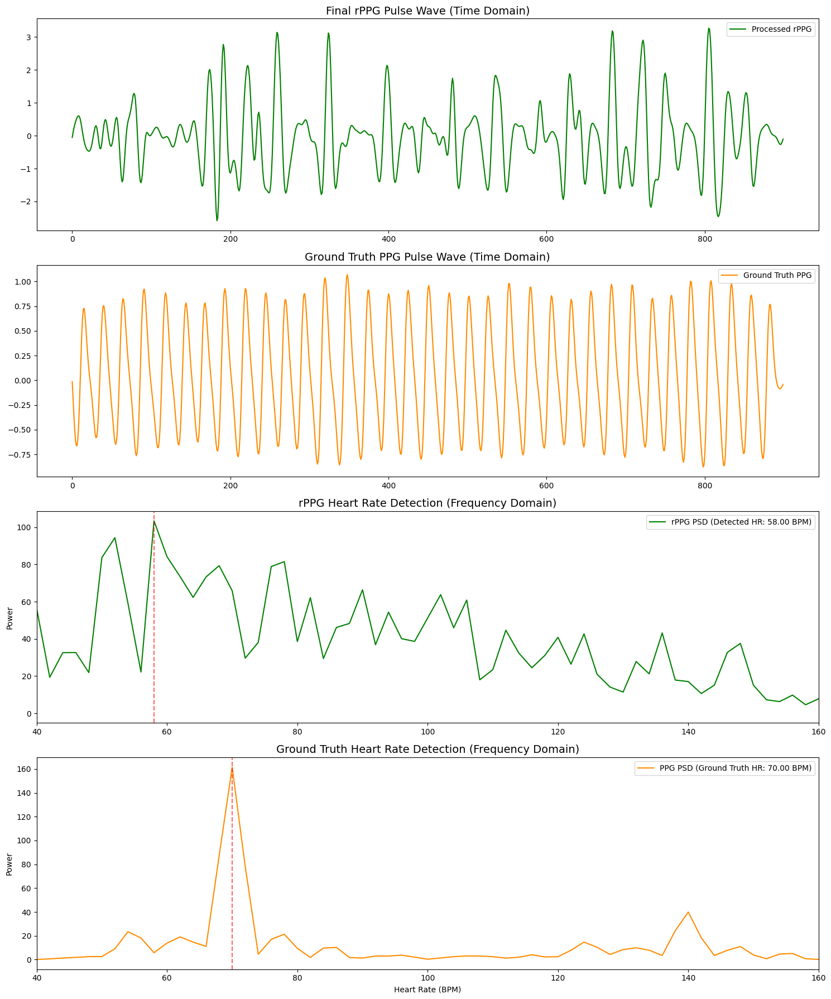

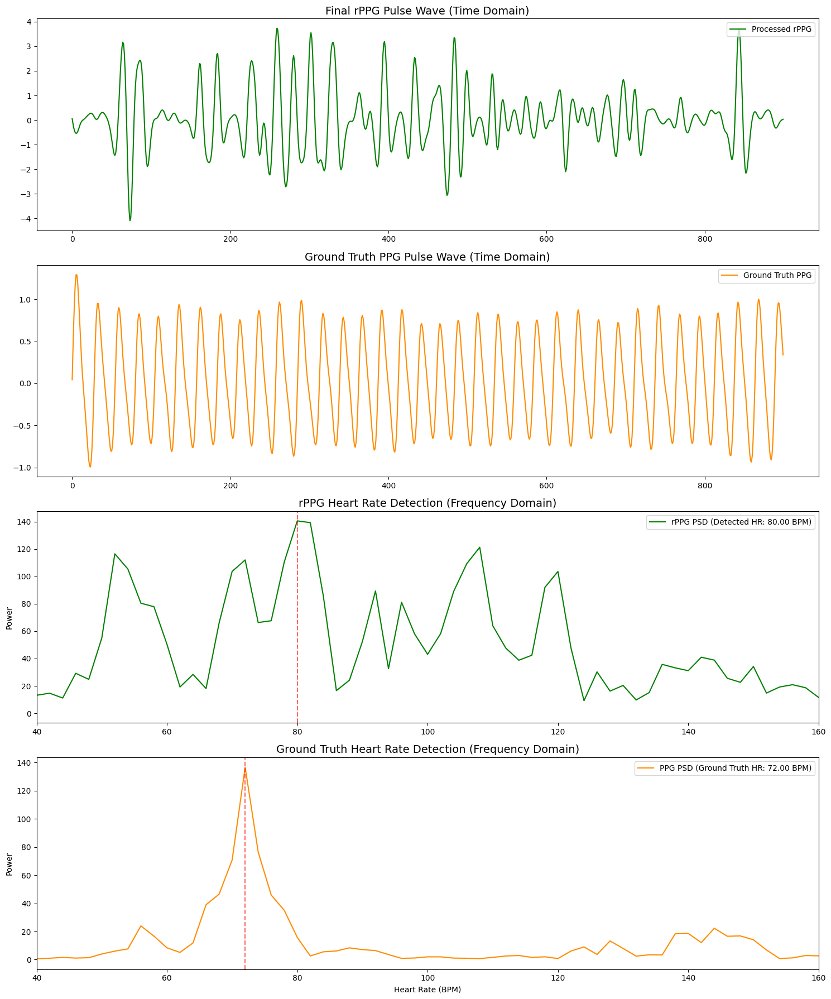

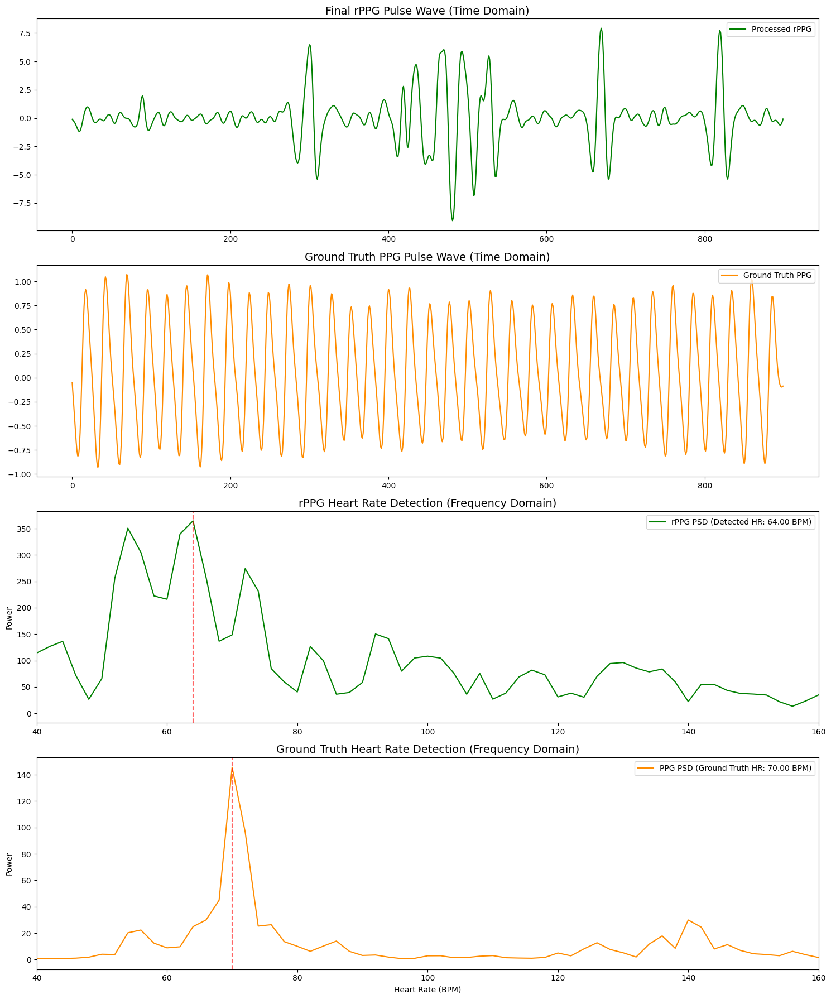

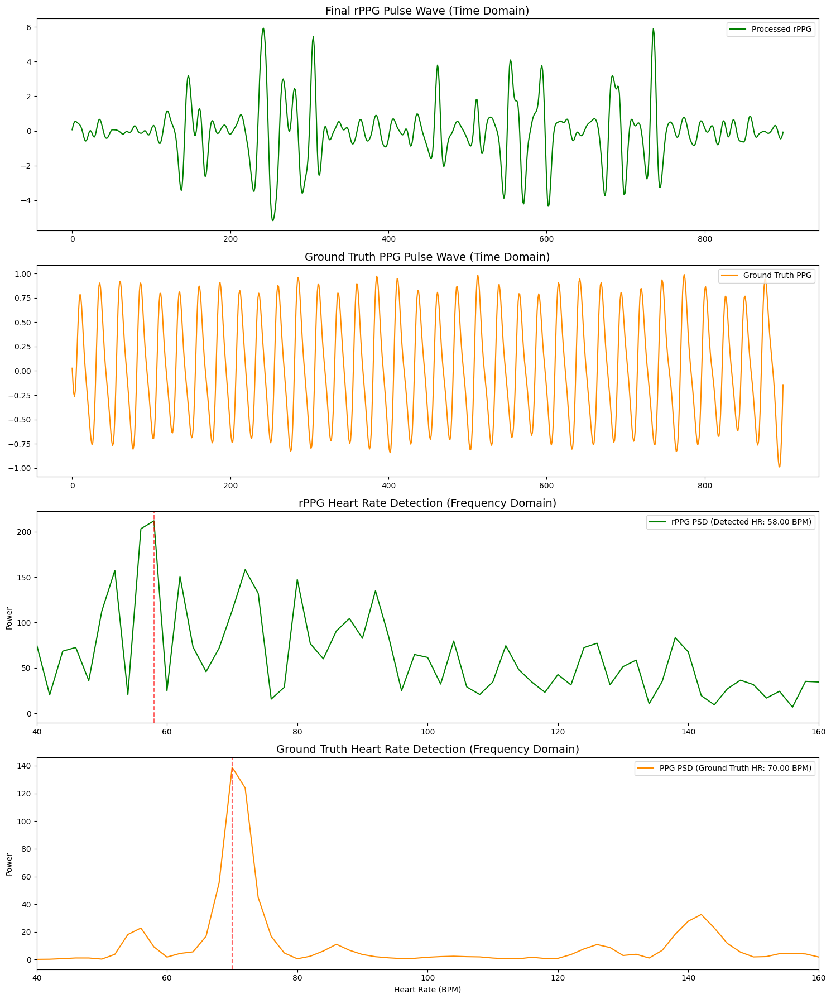

총 126개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 120개, 폐기 윈도우 6개
A002_20250609 : 성공 , hr : 16.533333333333335


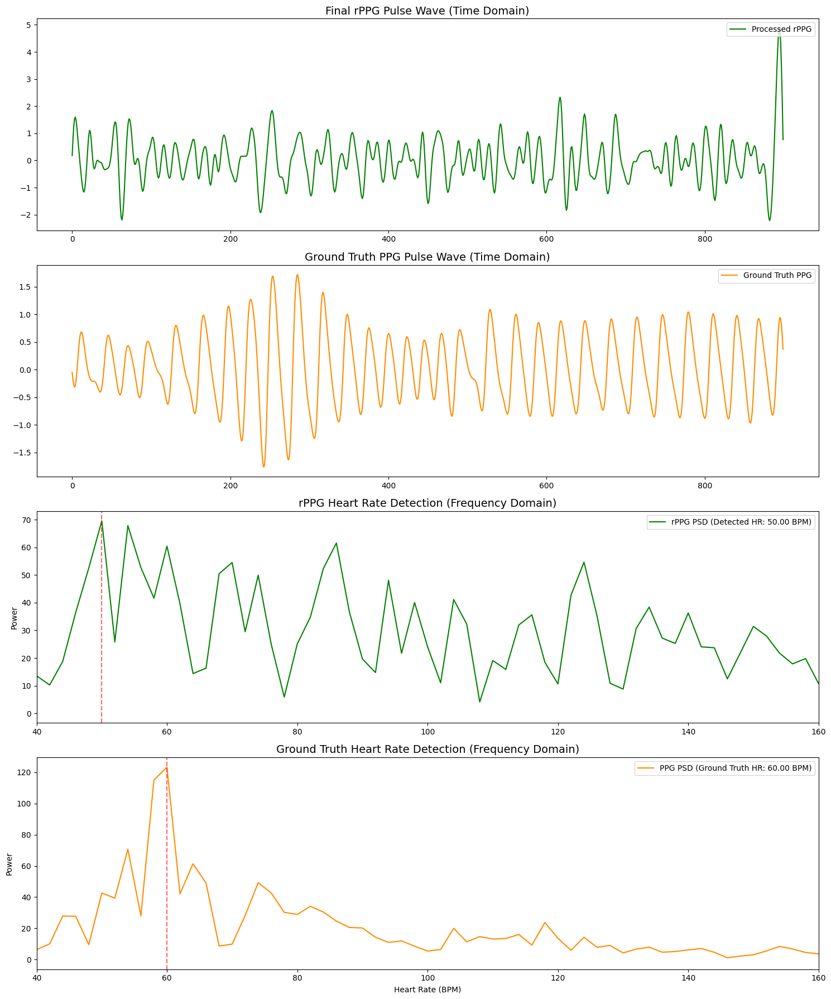

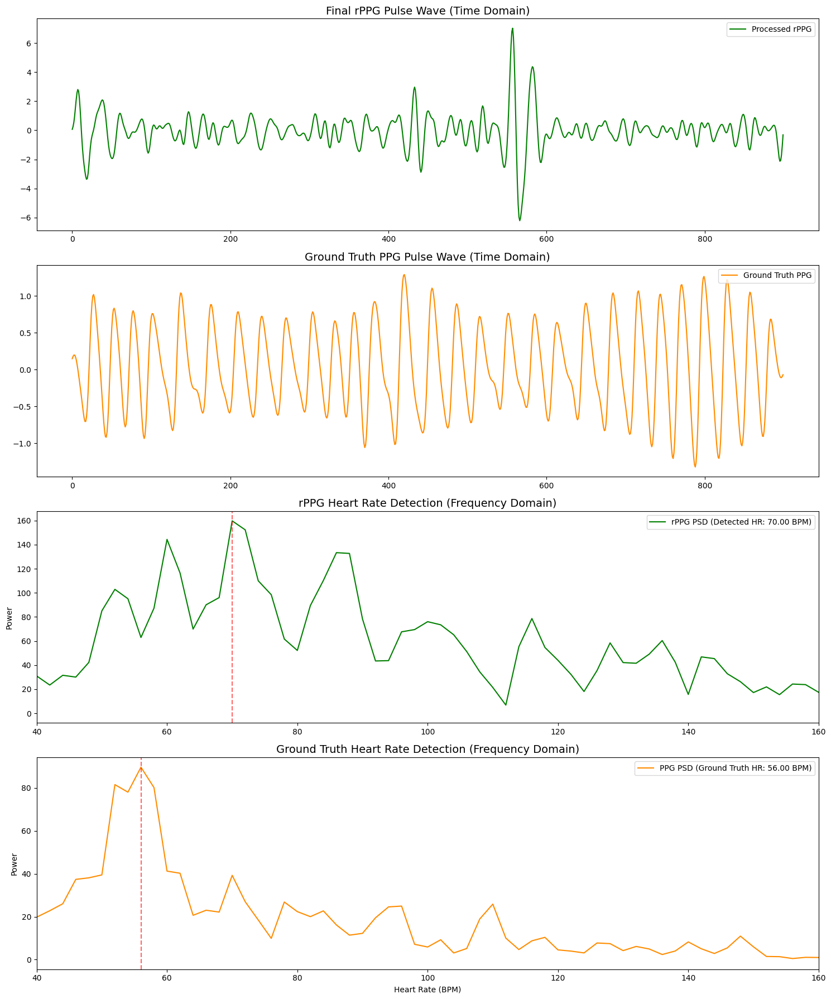

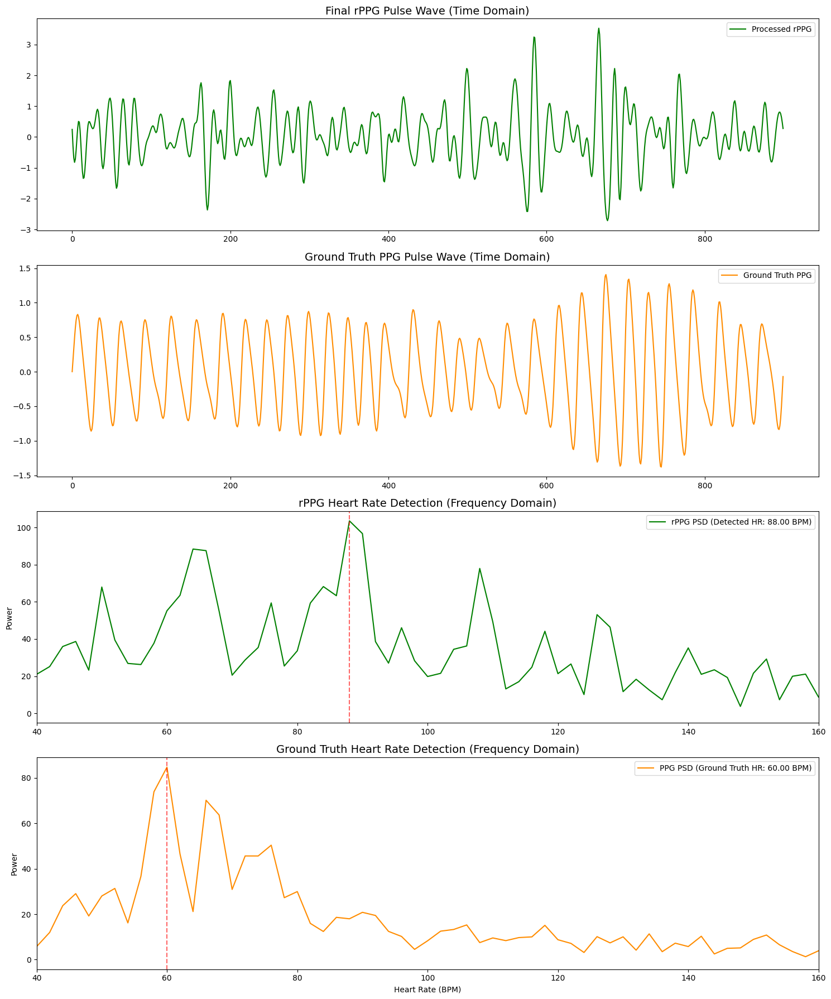

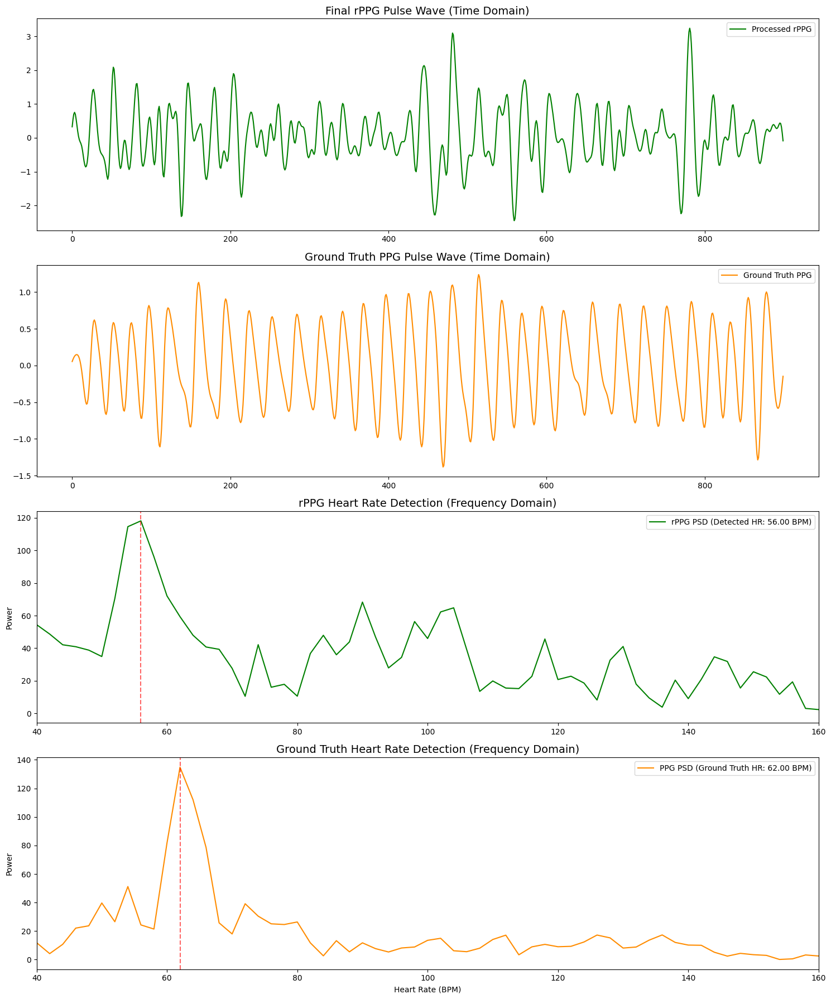

총 127개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 127개, 폐기 윈도우 0개
A004_20250610 : 성공 , hr : 27.086614173228348


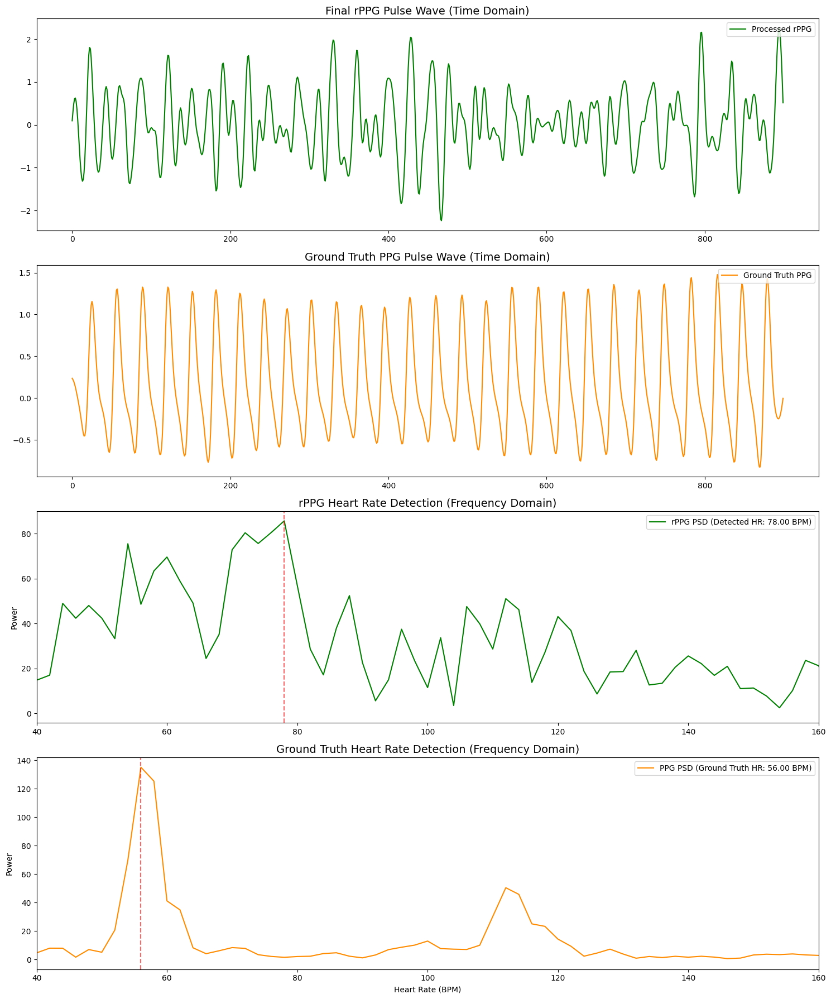

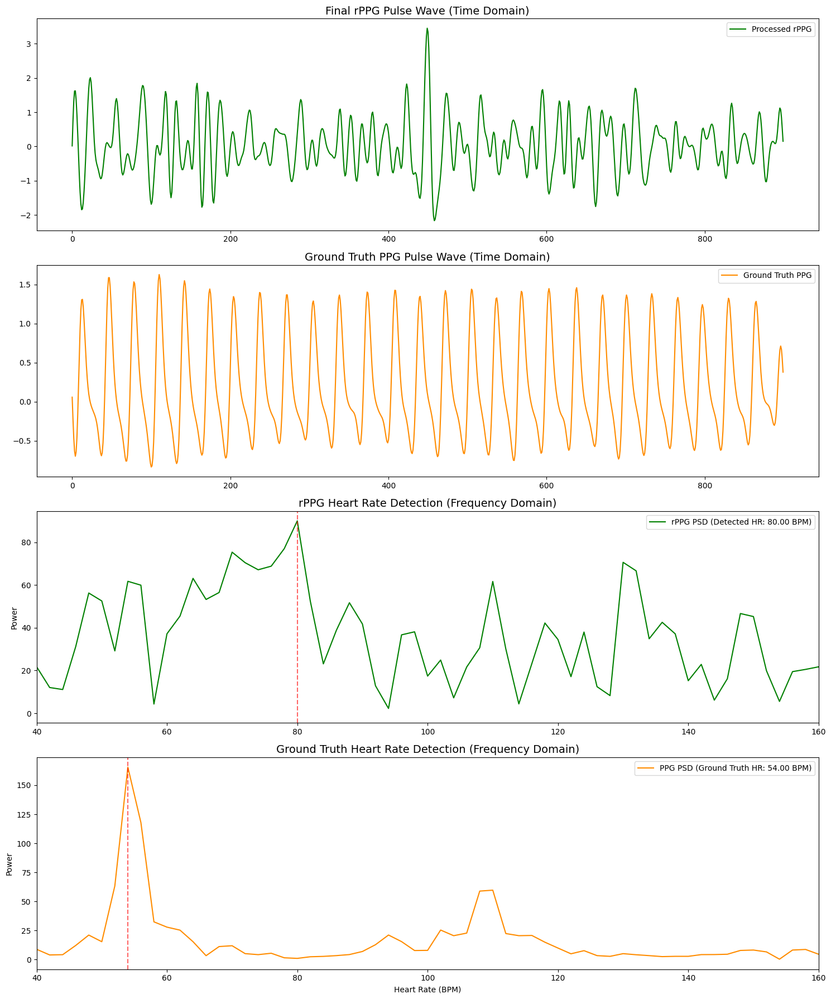

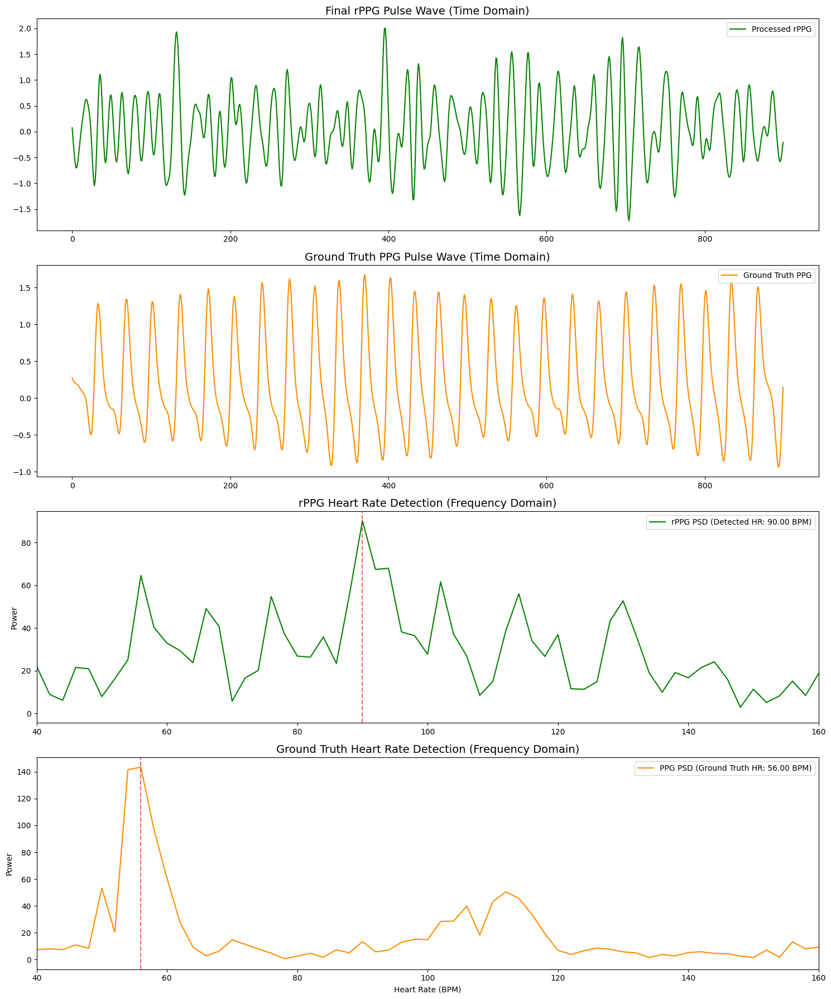

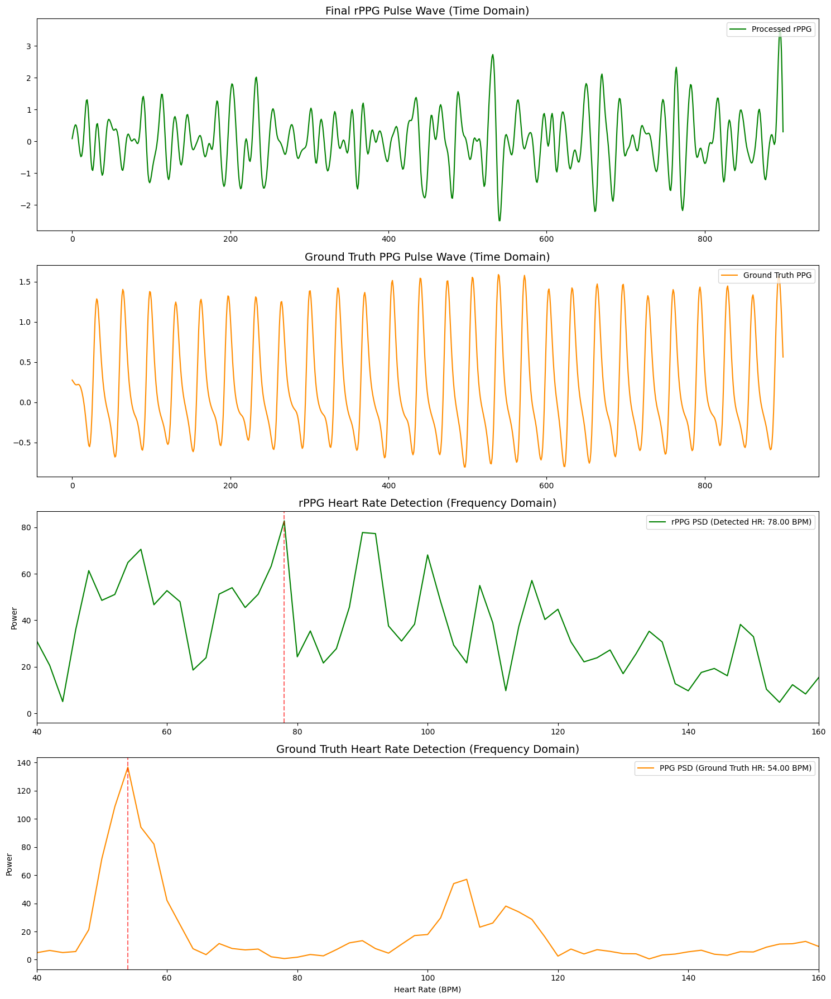

총 133개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 85개, 폐기 윈도우 48개
A005_20250611 : 성공 , hr : 10.75294117647059


❌ [치명적 오류 발생] 프로그램이 중단되었습니다.
에러 메시지: array must not contain infs or NaNs
------------------------------
상세 에러 위치 (Traceback):


Traceback (most recent call last):
  File "/tmp/ipykernel_276547/2728356016.py", line 122, in <module>
    visualize_interpolation_and_fft(sig_rl, ppg_downsampled ,sub_valid, window_idx = j)
  File "/tmp/ipykernel_276547/3516439891.py", line 22, in visualize_interpolation_and_fft
    norm_rppg = z_norm(signal.filtfilt(b, a, signal.detrend(interpolated_window)))
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/scipy/signal/_signaltools.py", line 3958, in detrend
    coef, resids, rank, s = linalg.lstsq(A, newdata[sl])
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/scipy/linalg/_basic.py", line 1413, in lstsq
    b1 = _asarray_validated(b, check_finite=check_finite)
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/scipy/_lib/_util.py", line 537, in _asarray_validated
    a = toarray(a)
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/numpy/lib/function_base.py", line 630, in asarray_chkfinite
  

총 115개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 115개, 폐기 윈도우 0개
A006_20250611 : 성공 , hr : 11.826086956521738


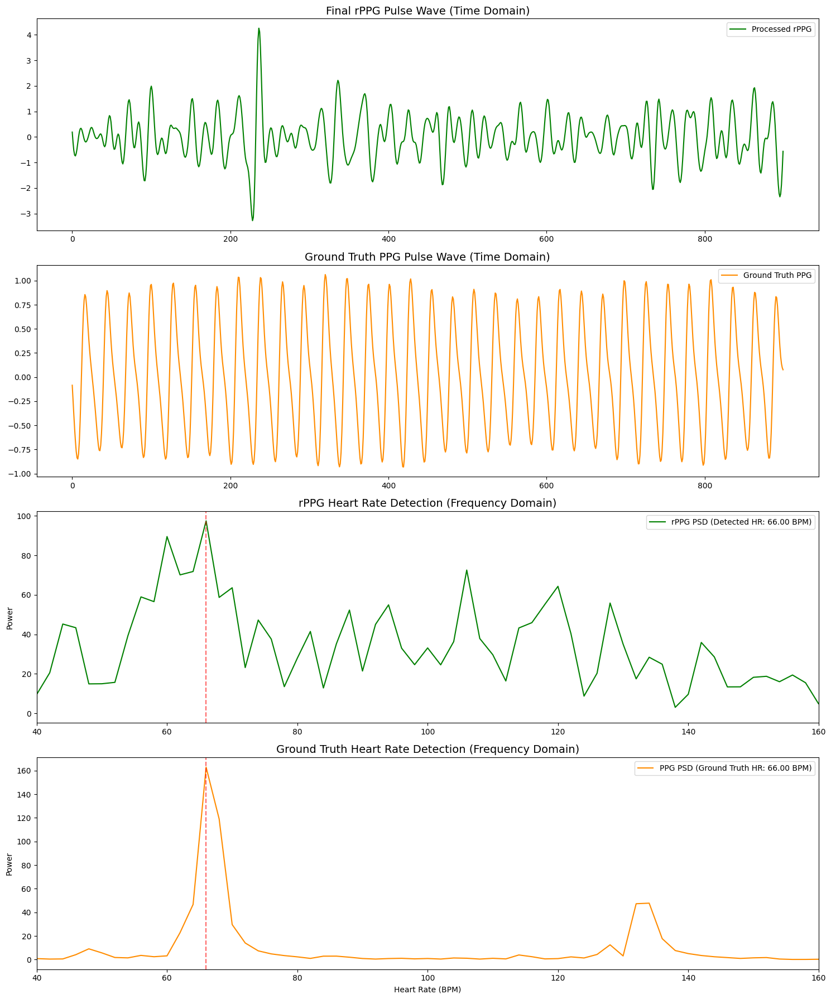

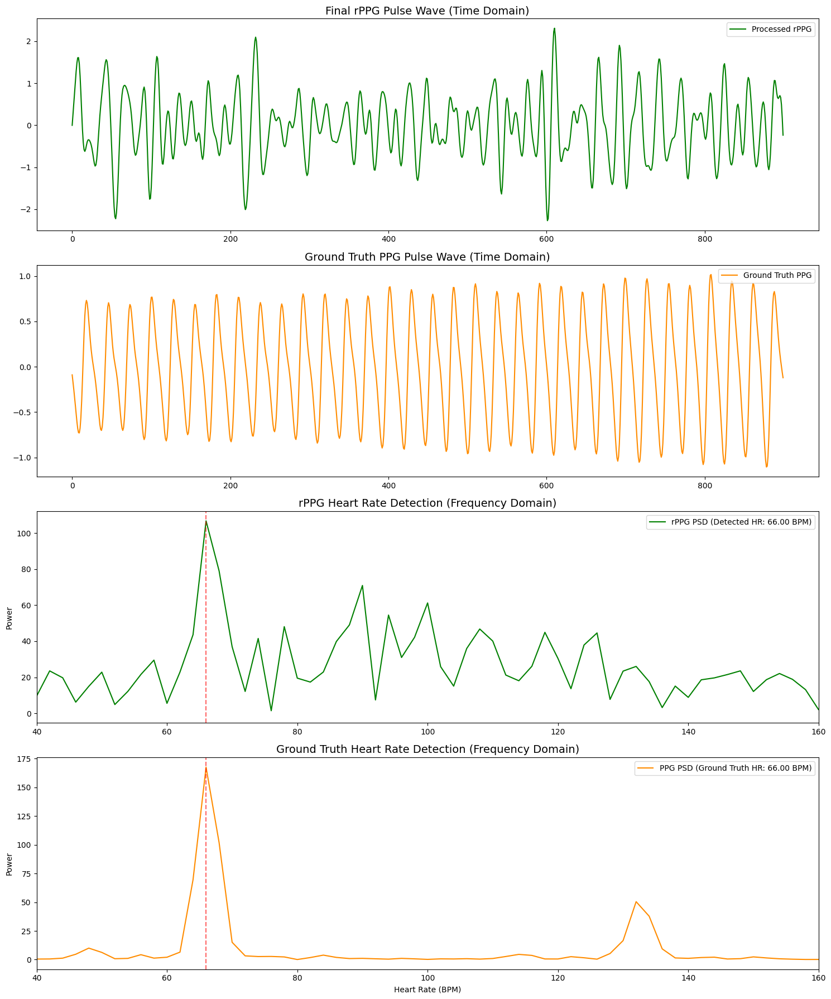

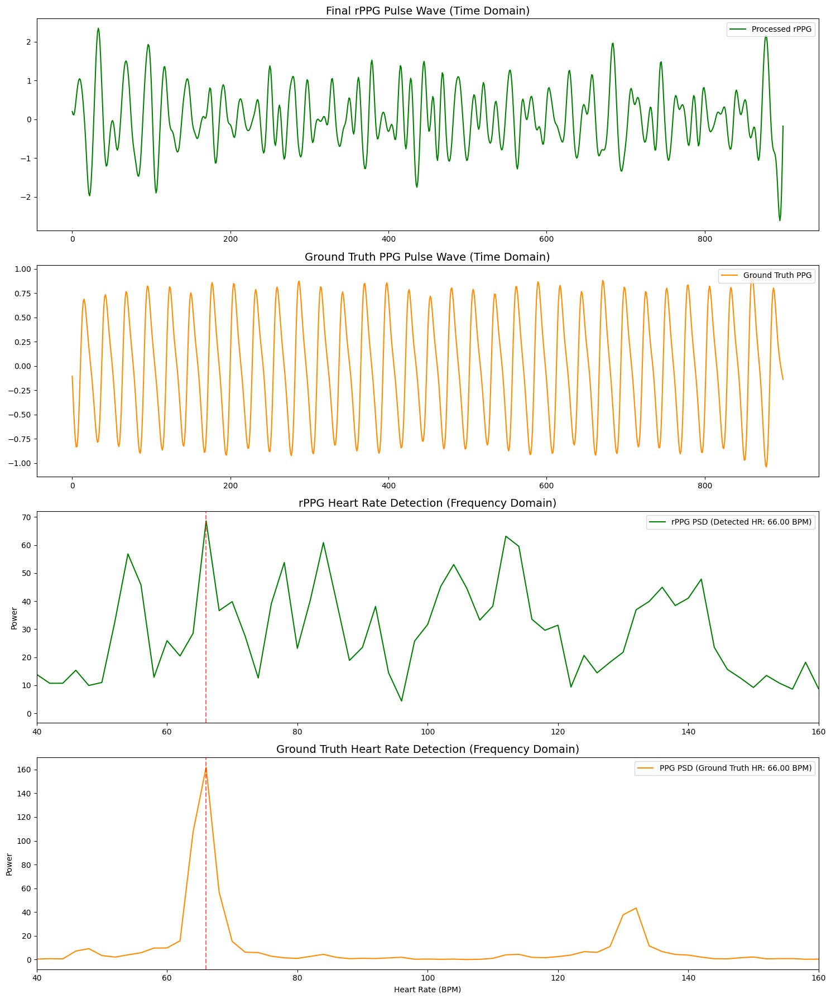

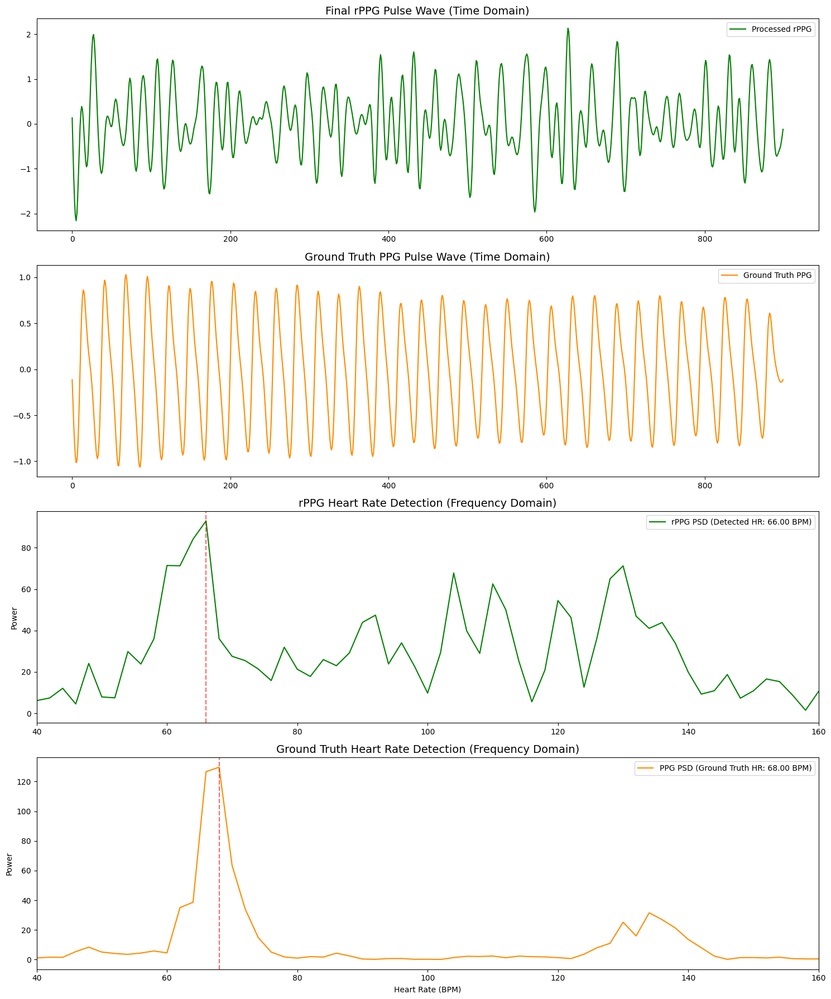

총 133개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 79개, 폐기 윈도우 54개
A007_20250612 : 성공 , hr : 26.126582278481013


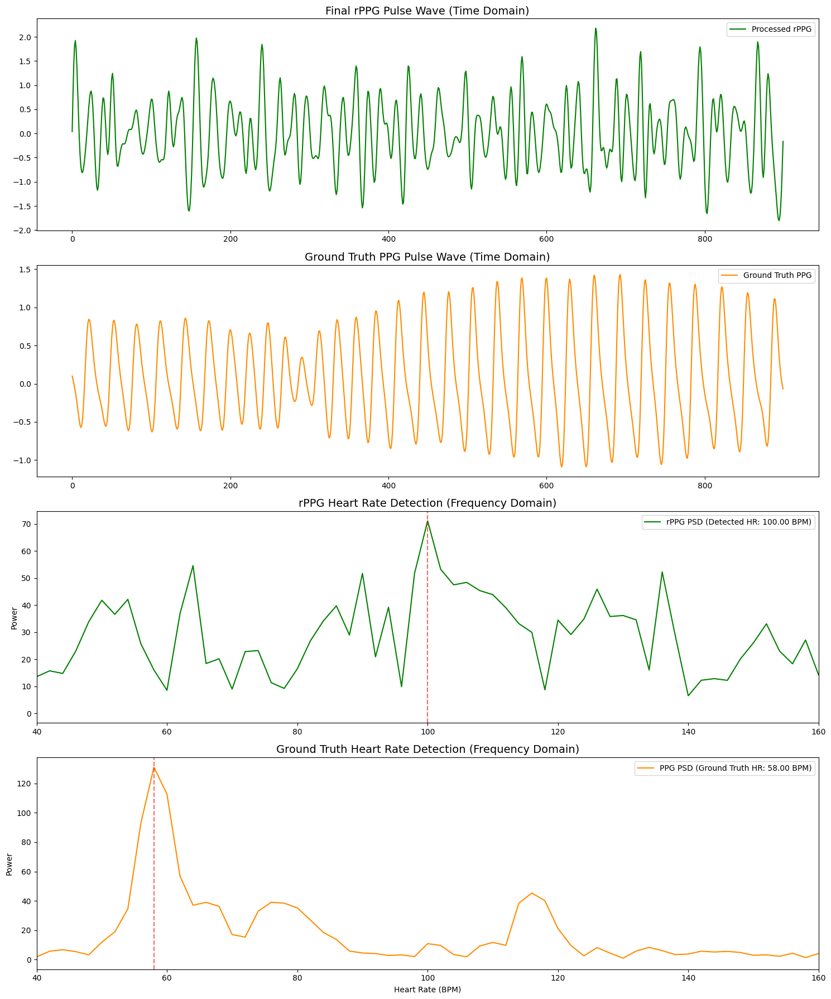

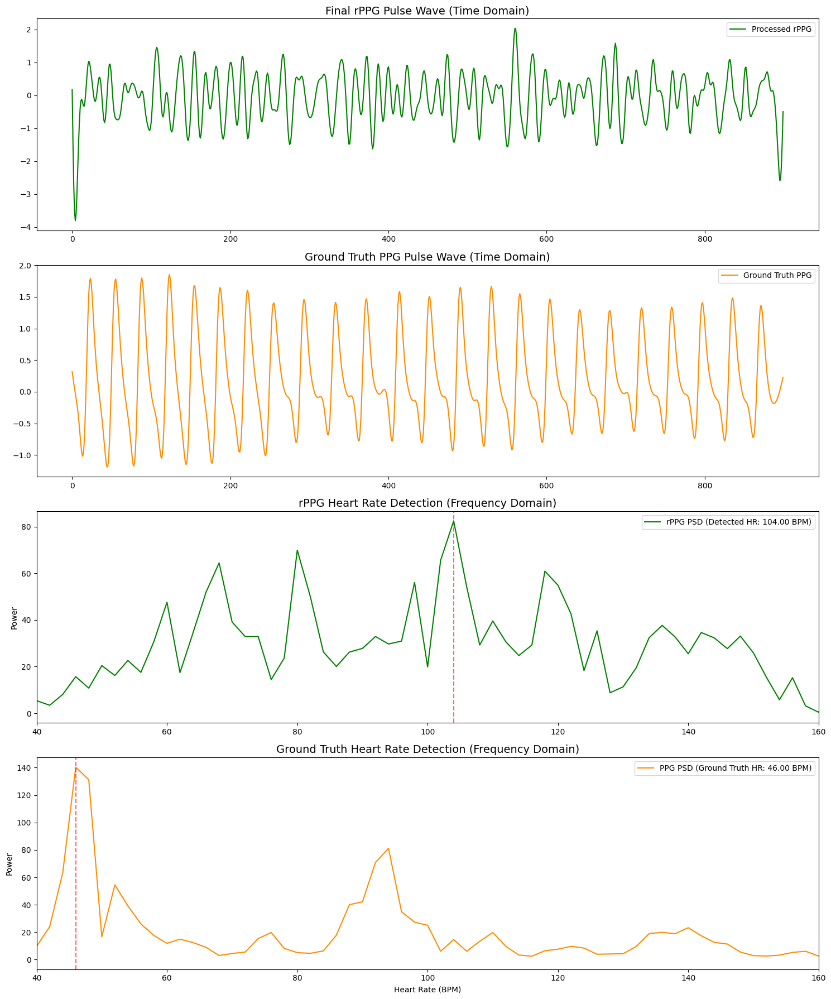

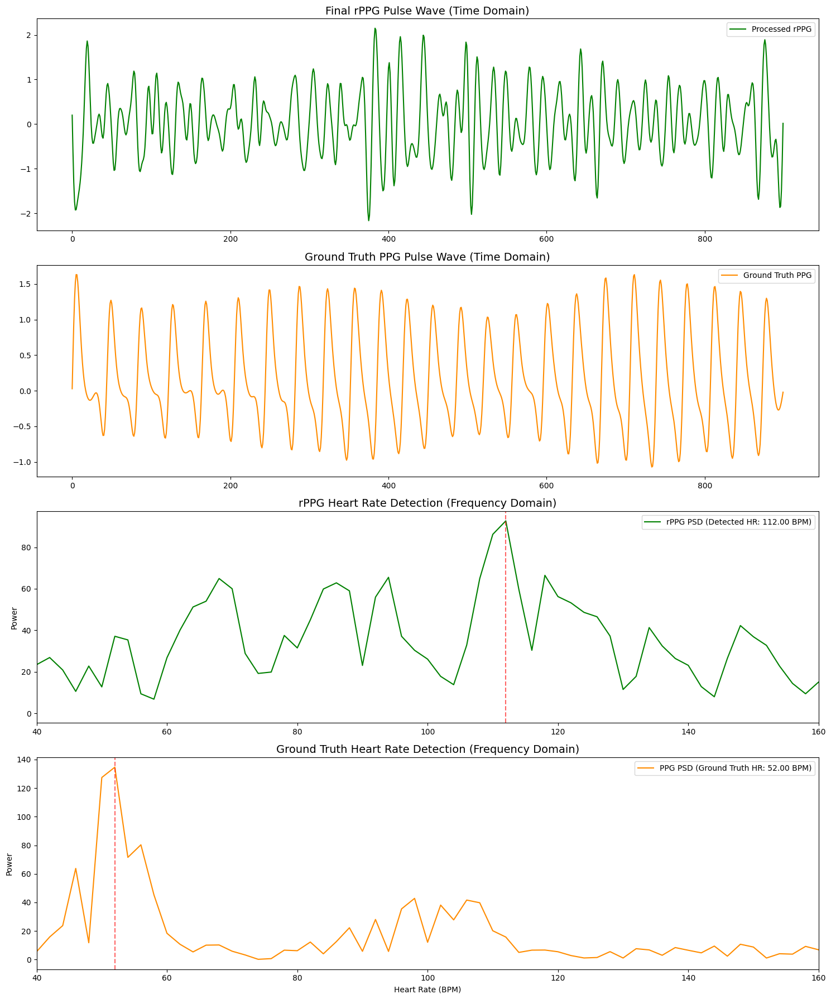

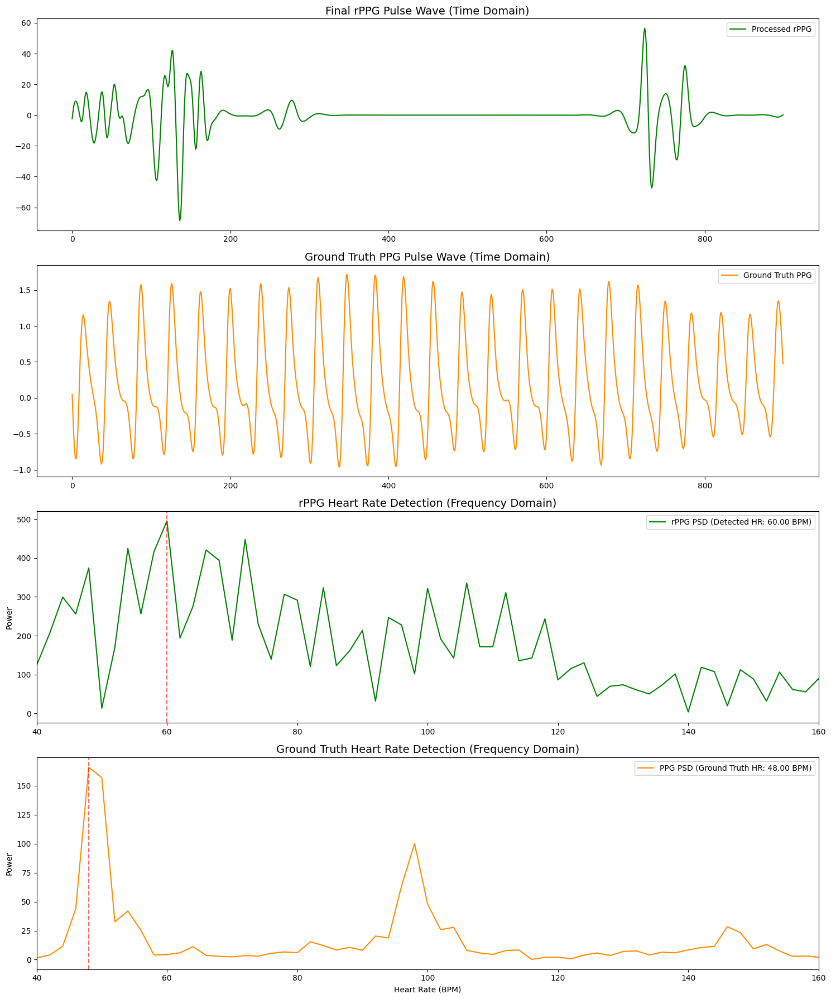

총 129개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 73개, 폐기 윈도우 56개
A008_20250612 : 성공 , hr : 21.45205479452055


❌ [치명적 오류 발생] 프로그램이 중단되었습니다.
에러 메시지: array must not contain infs or NaNs
------------------------------
상세 에러 위치 (Traceback):


Traceback (most recent call last):
  File "/tmp/ipykernel_276547/2728356016.py", line 122, in <module>
    visualize_interpolation_and_fft(sig_rl, ppg_downsampled ,sub_valid, window_idx = j)
  File "/tmp/ipykernel_276547/3516439891.py", line 22, in visualize_interpolation_and_fft
    norm_rppg = z_norm(signal.filtfilt(b, a, signal.detrend(interpolated_window)))
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/scipy/signal/_signaltools.py", line 3958, in detrend
    coef, resids, rank, s = linalg.lstsq(A, newdata[sl])
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/scipy/linalg/_basic.py", line 1413, in lstsq
    b1 = _asarray_validated(b, check_finite=check_finite)
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/scipy/_lib/_util.py", line 537, in _asarray_validated
    a = toarray(a)
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/numpy/lib/function_base.py", line 630, in asarray_chkfinite
  

총 130개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 127개, 폐기 윈도우 3개
B001_20250623 : 성공 , hr : 13.763779527559056


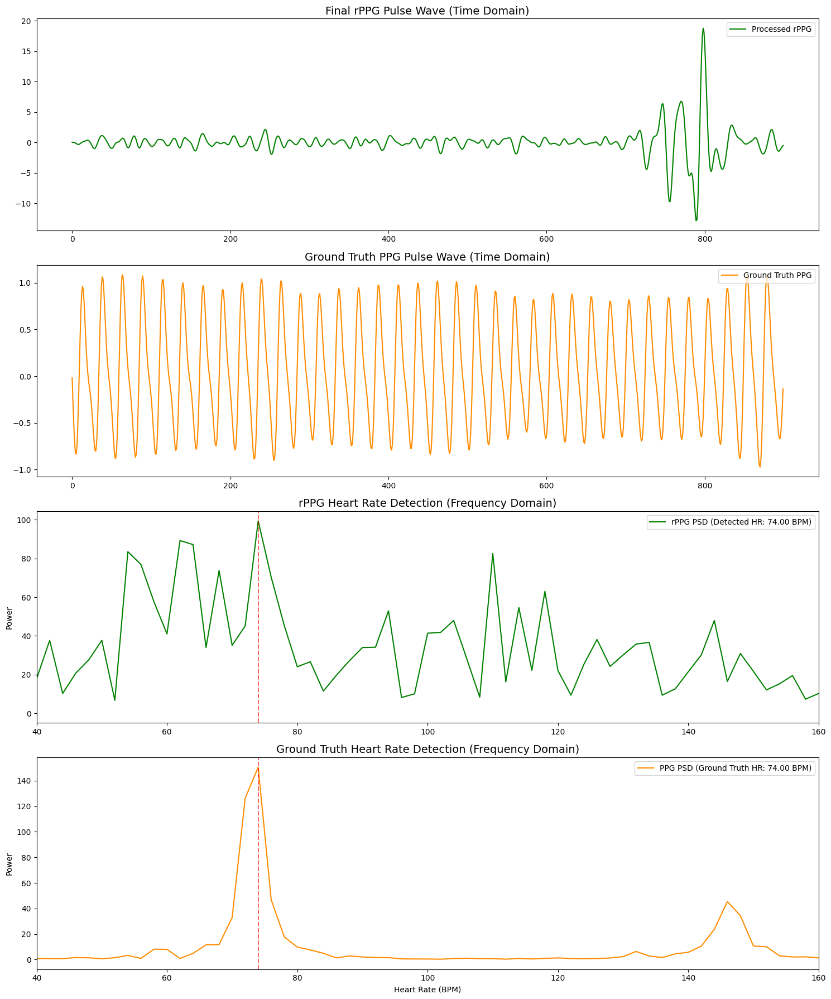

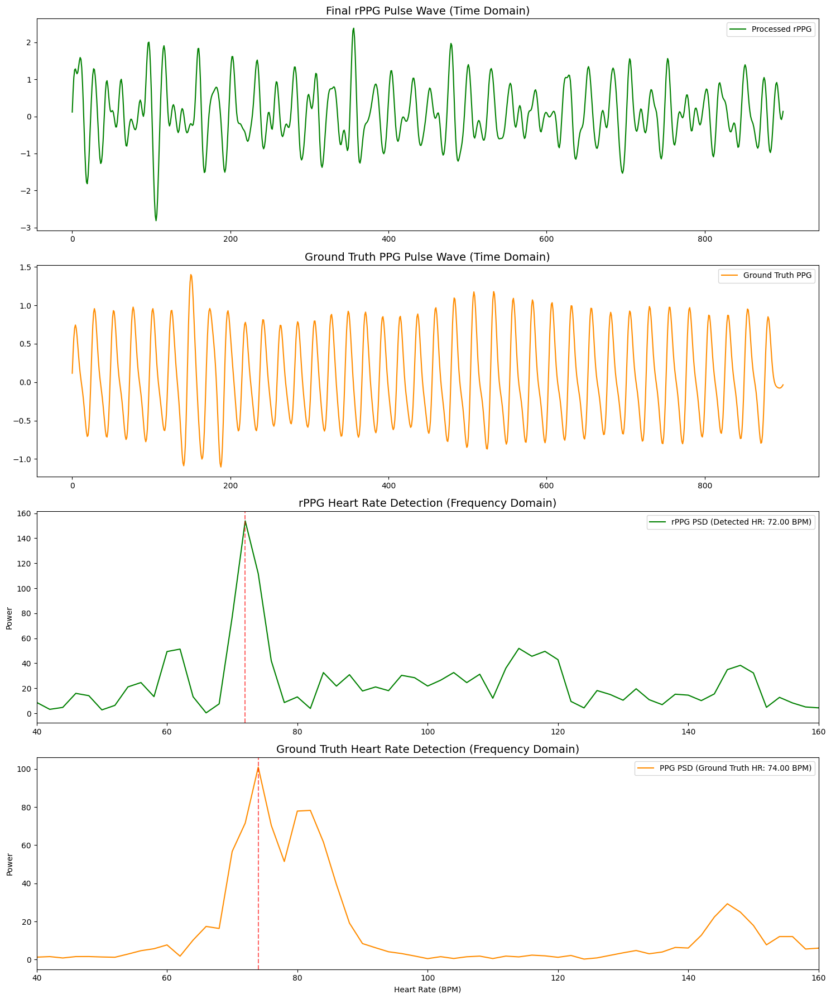

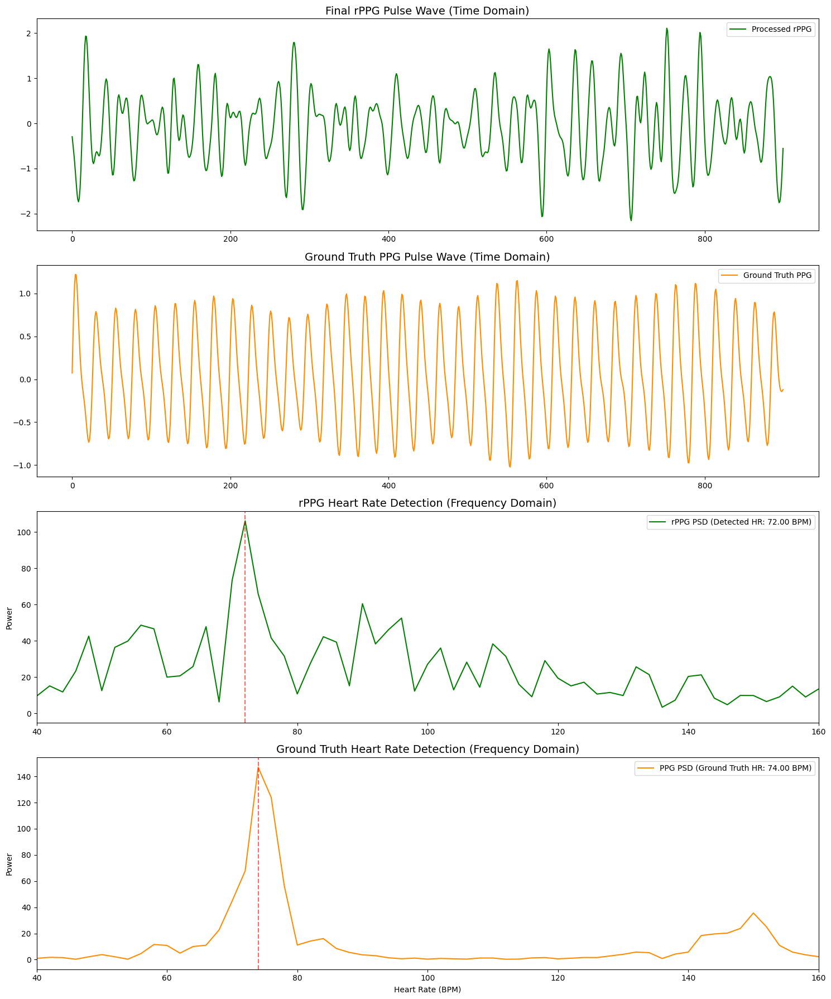

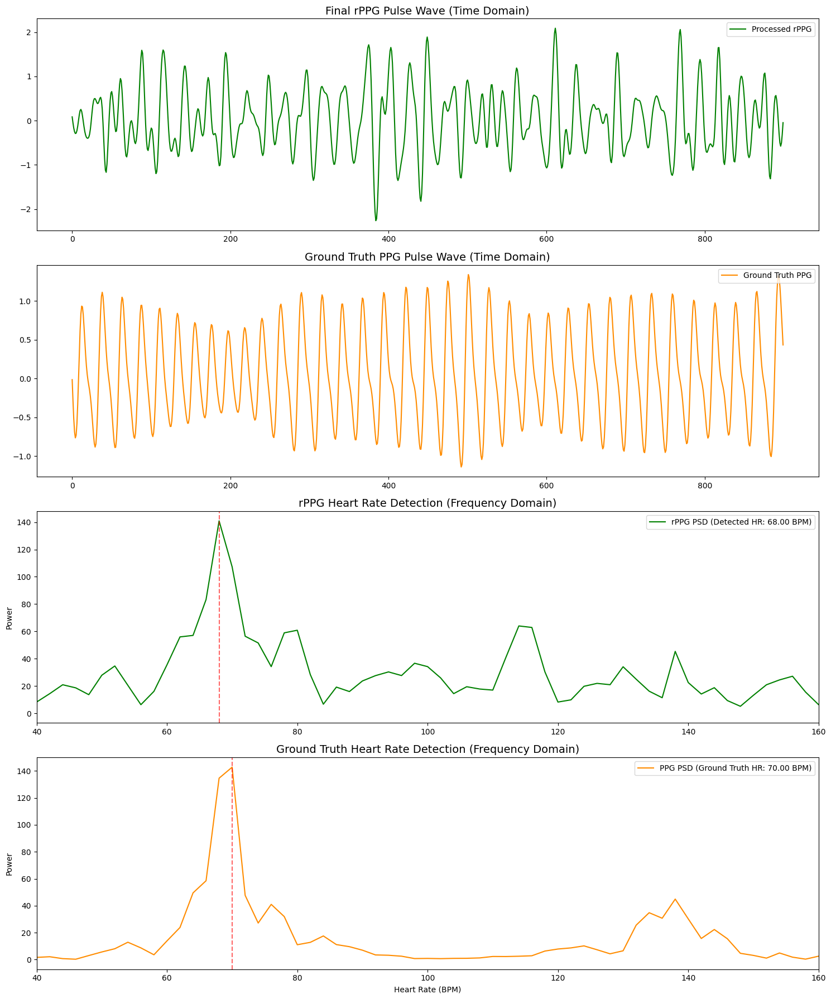

총 132개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 130개, 폐기 윈도우 2개
B002_20250623 : 성공 , hr : 13.646153846153846


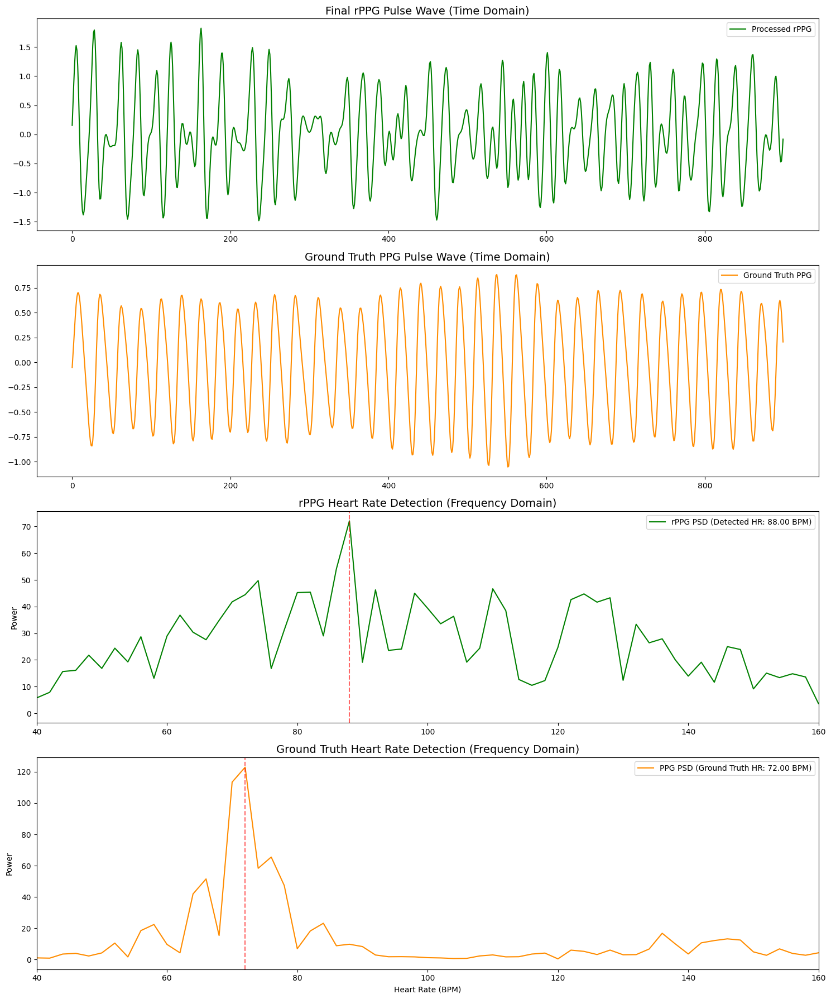

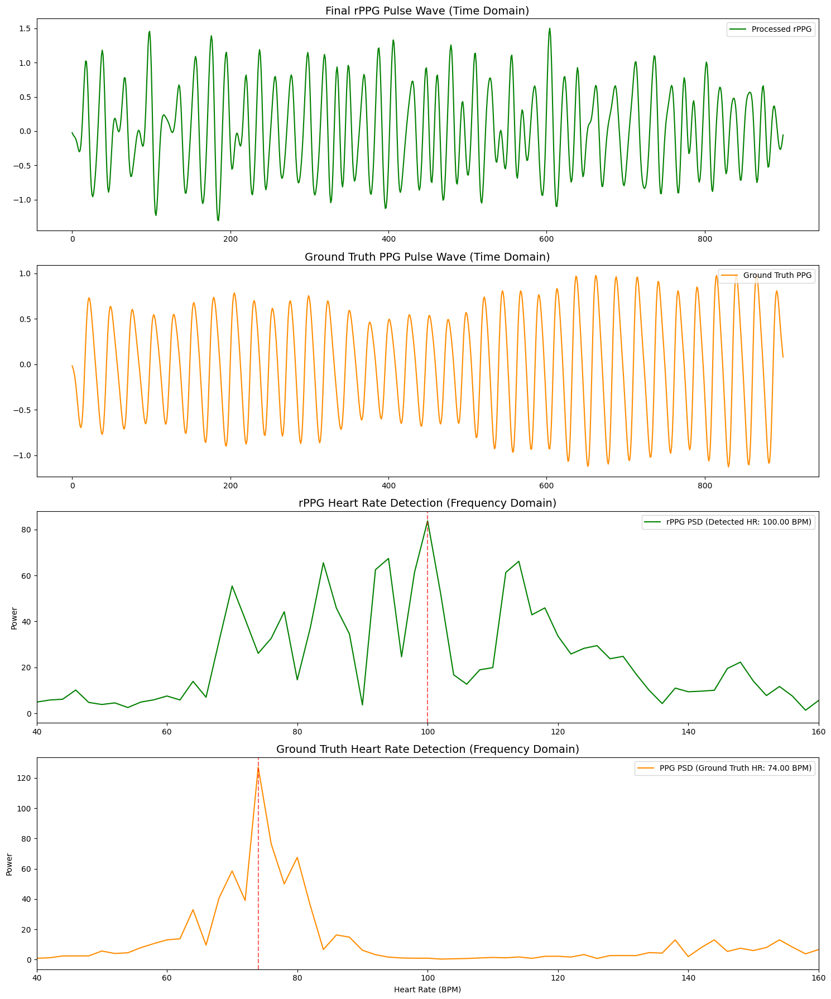

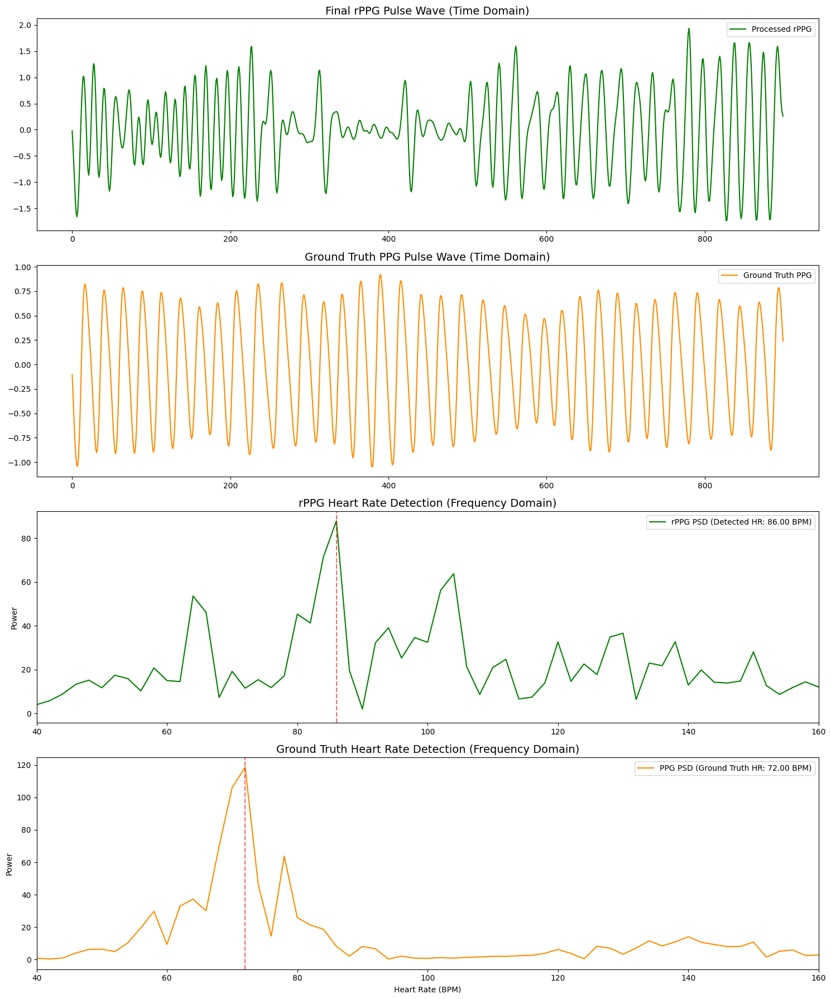

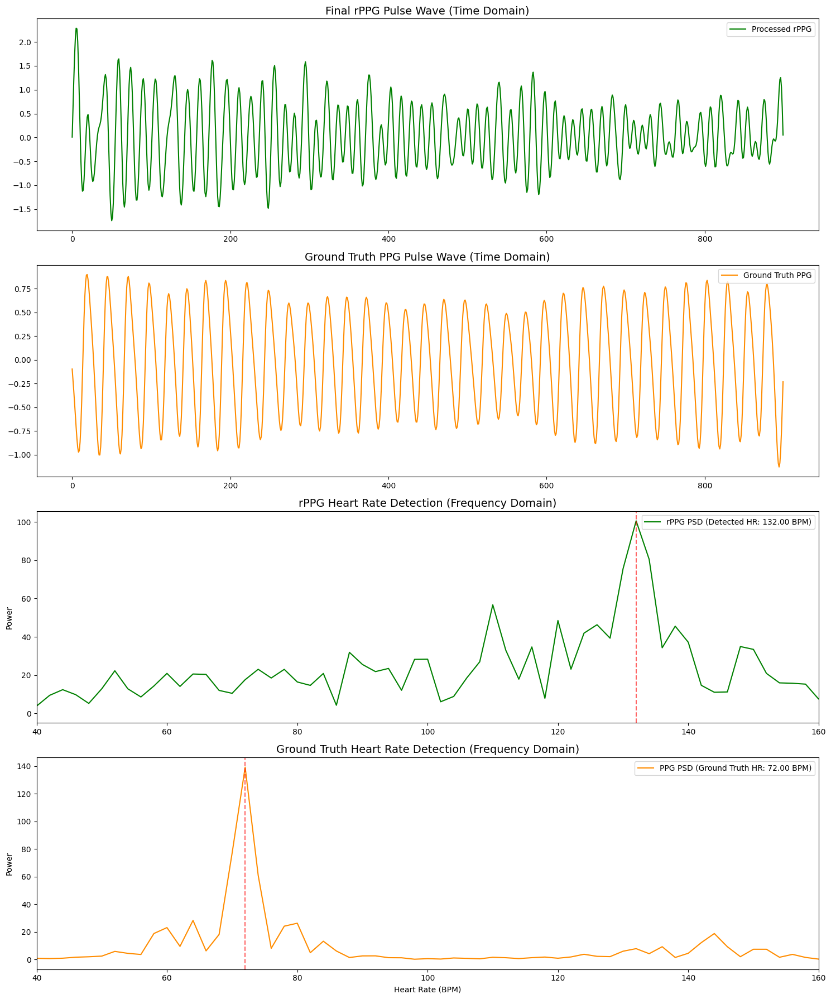

총 117개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 117개, 폐기 윈도우 0개
B003_20250624 : 성공 , hr : 13.82905982905983


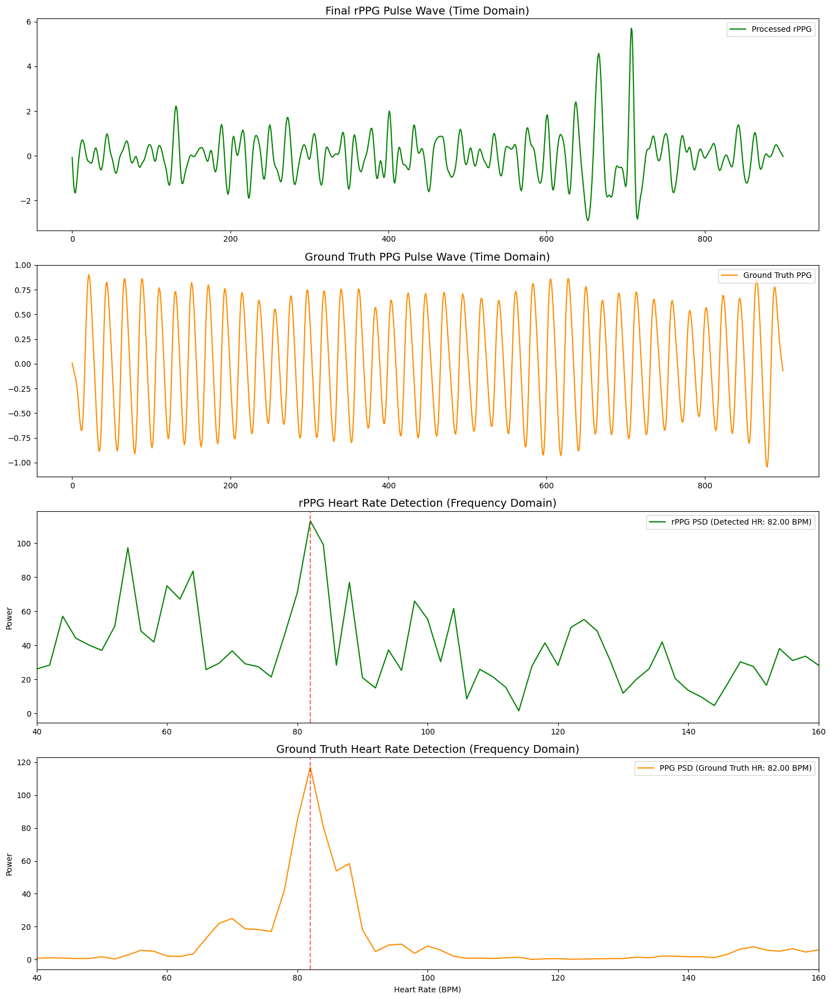

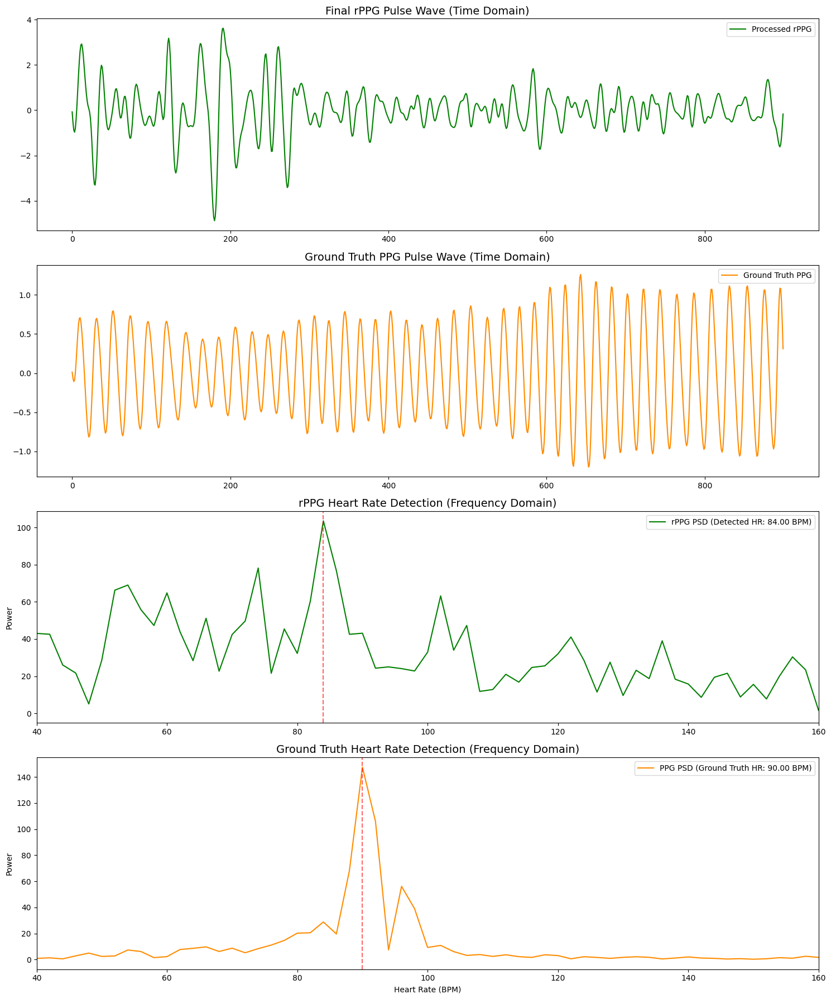

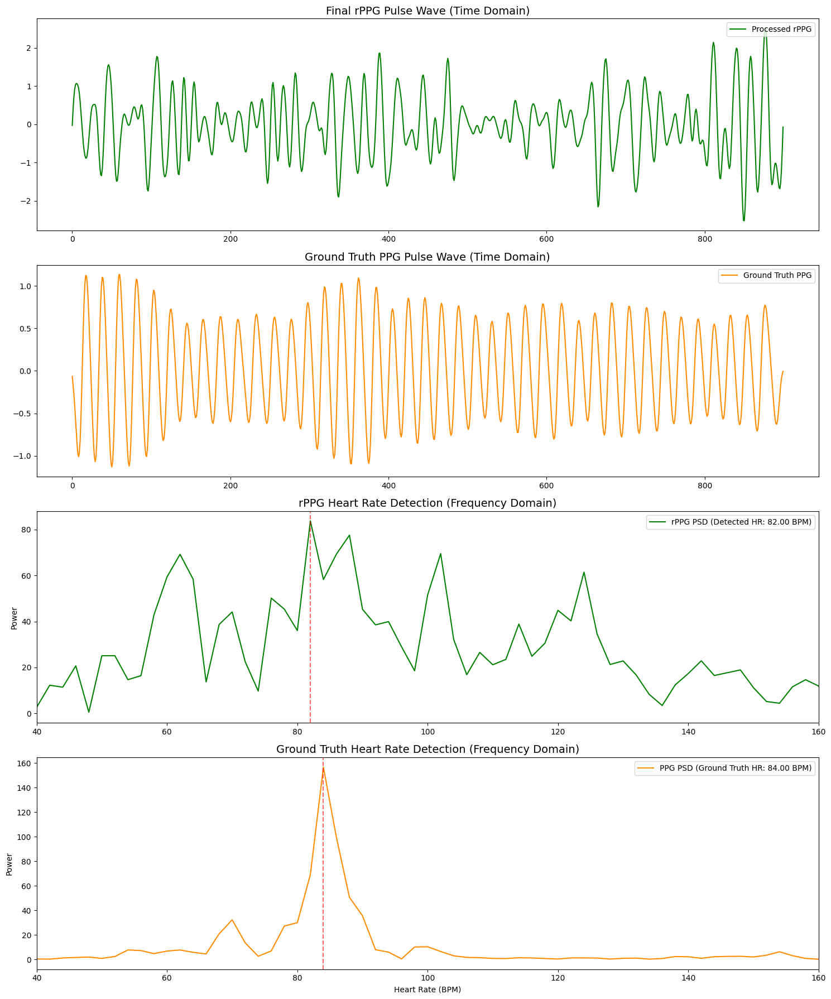

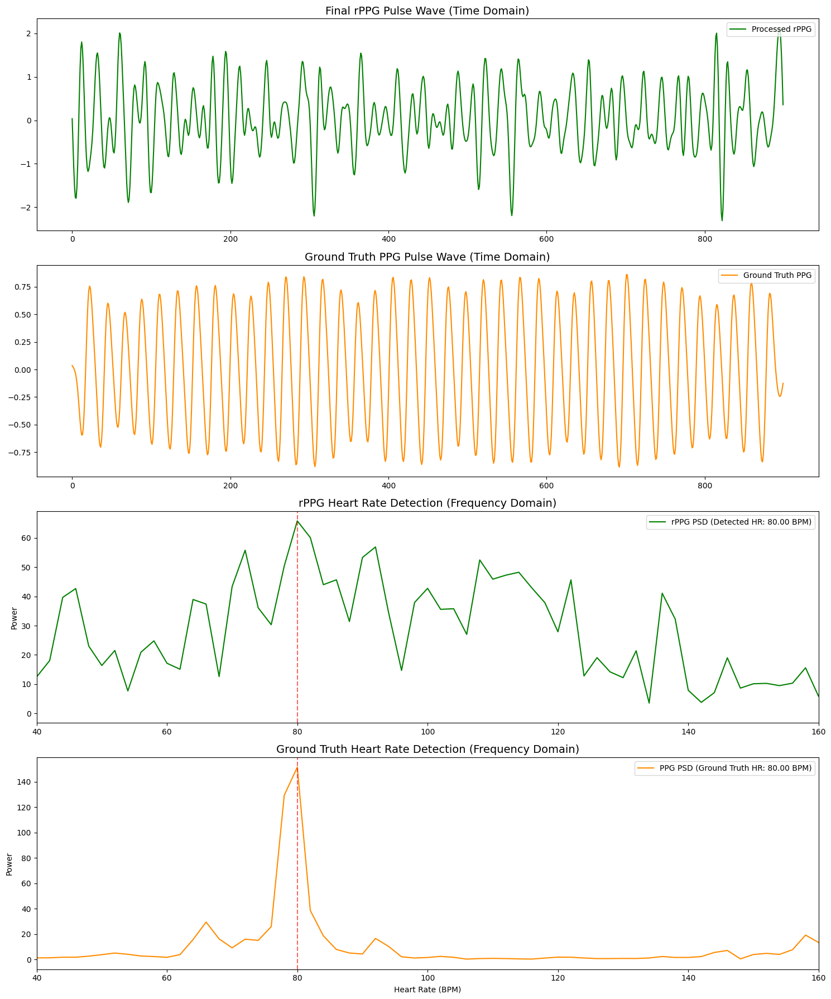

총 118개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 117개, 폐기 윈도우 1개
B004_20250624 : 성공 , hr : 26.324786324786327


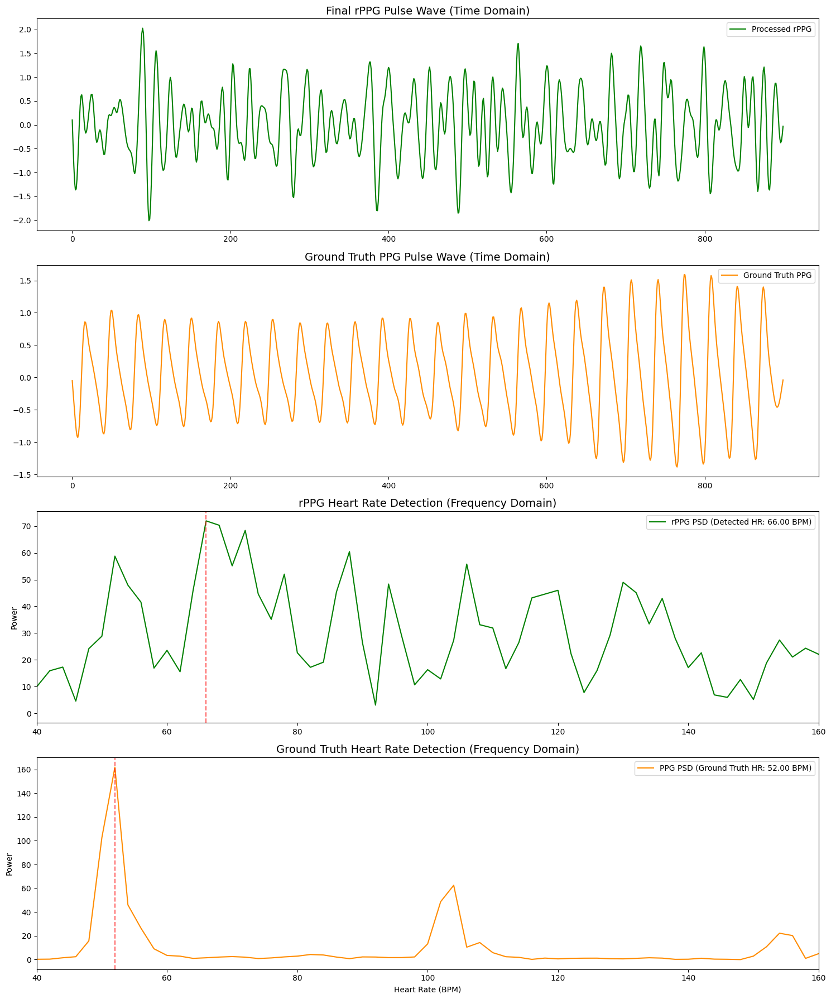

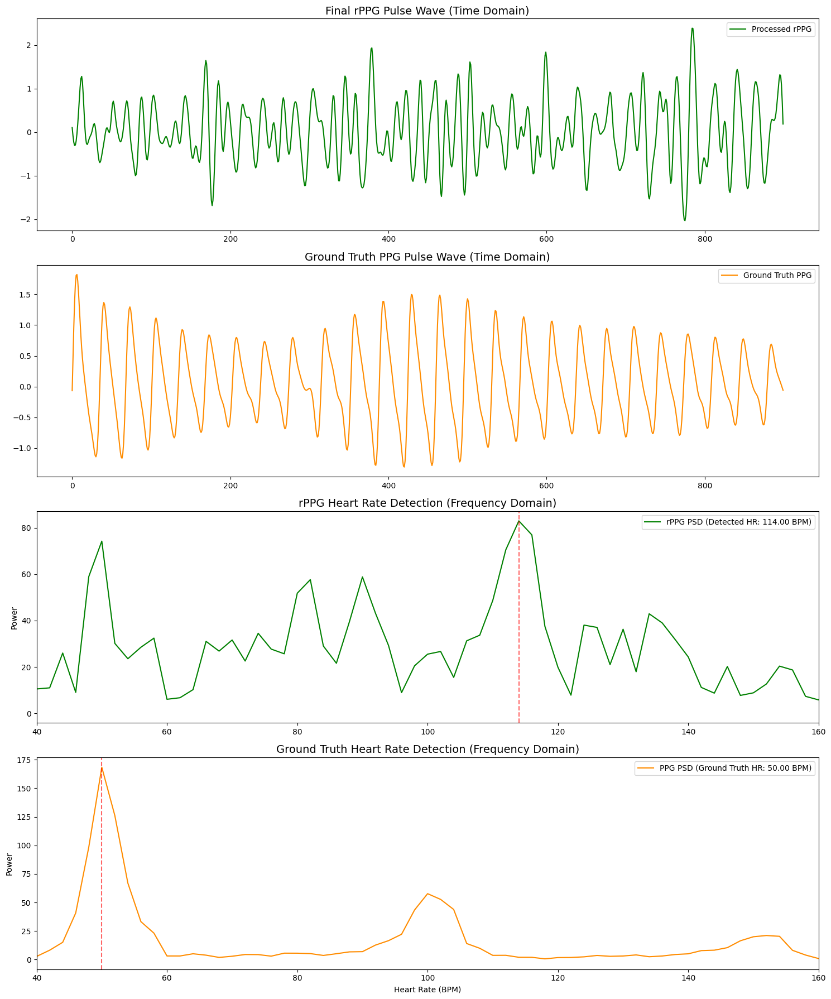

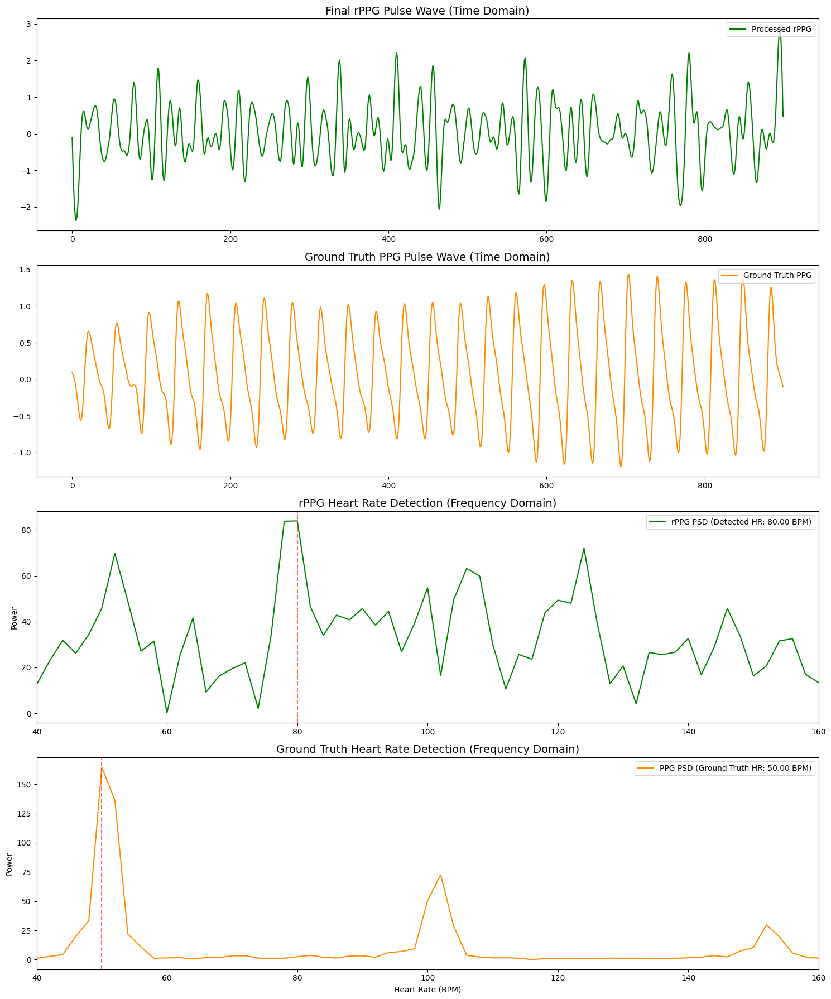

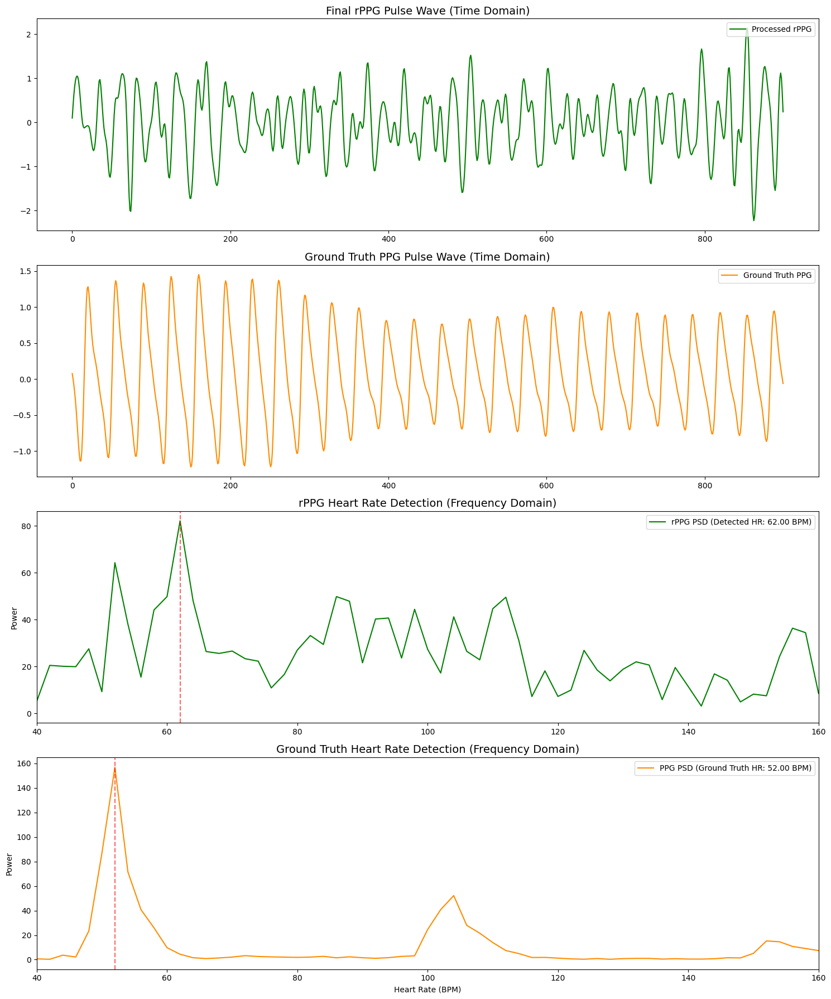

총 141개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 70개, 폐기 윈도우 71개
B005_20250625 : 성공 , hr : 18.542857142857144


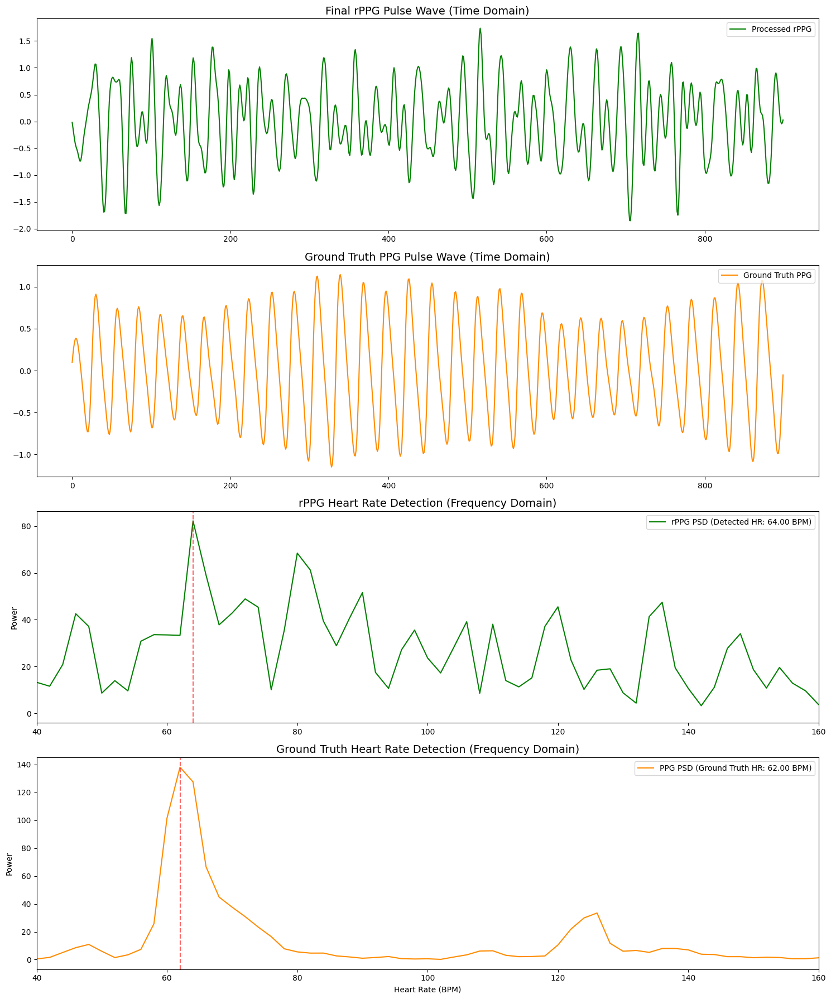

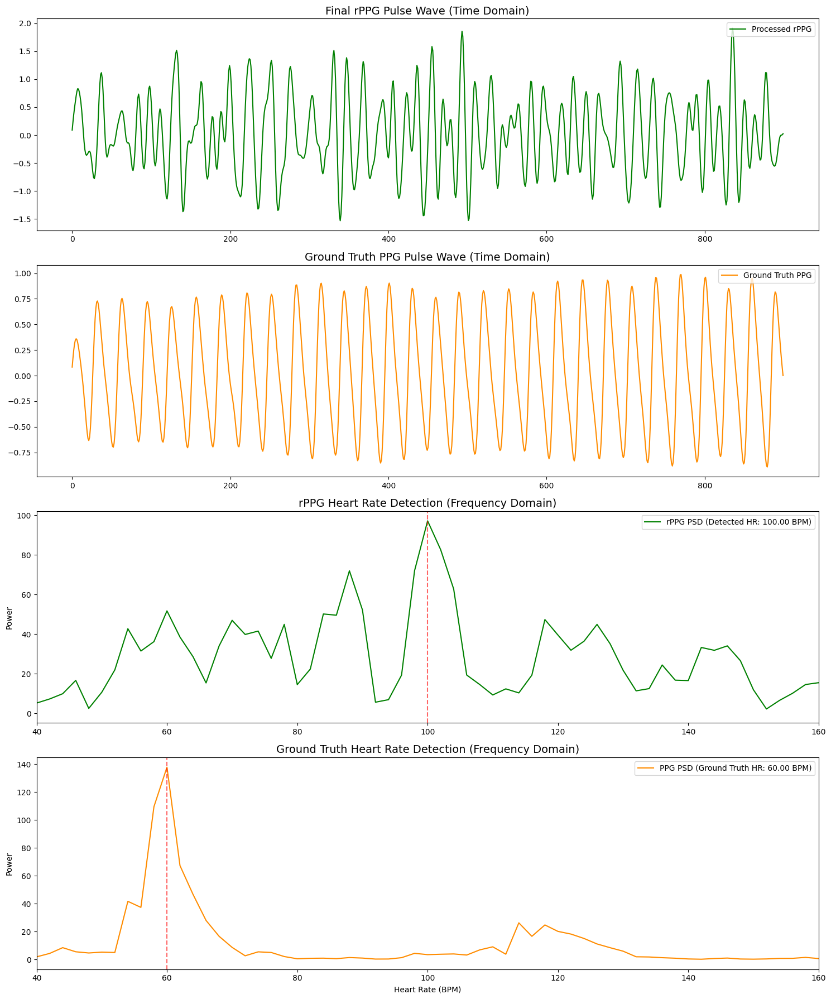

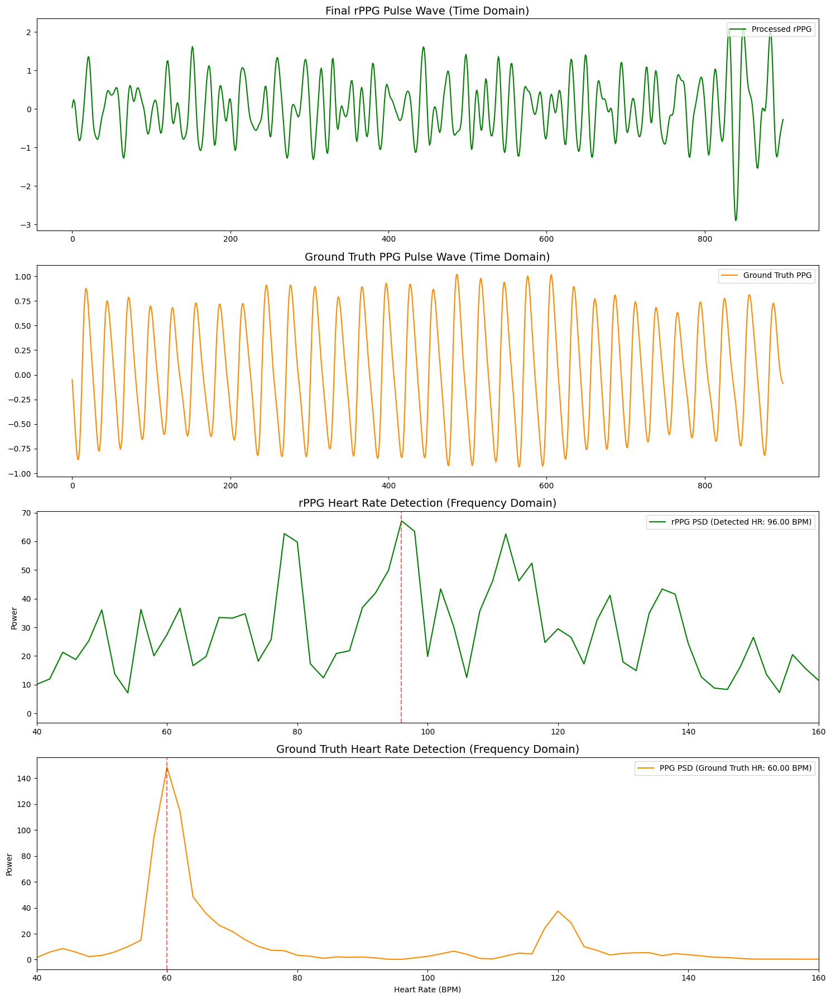

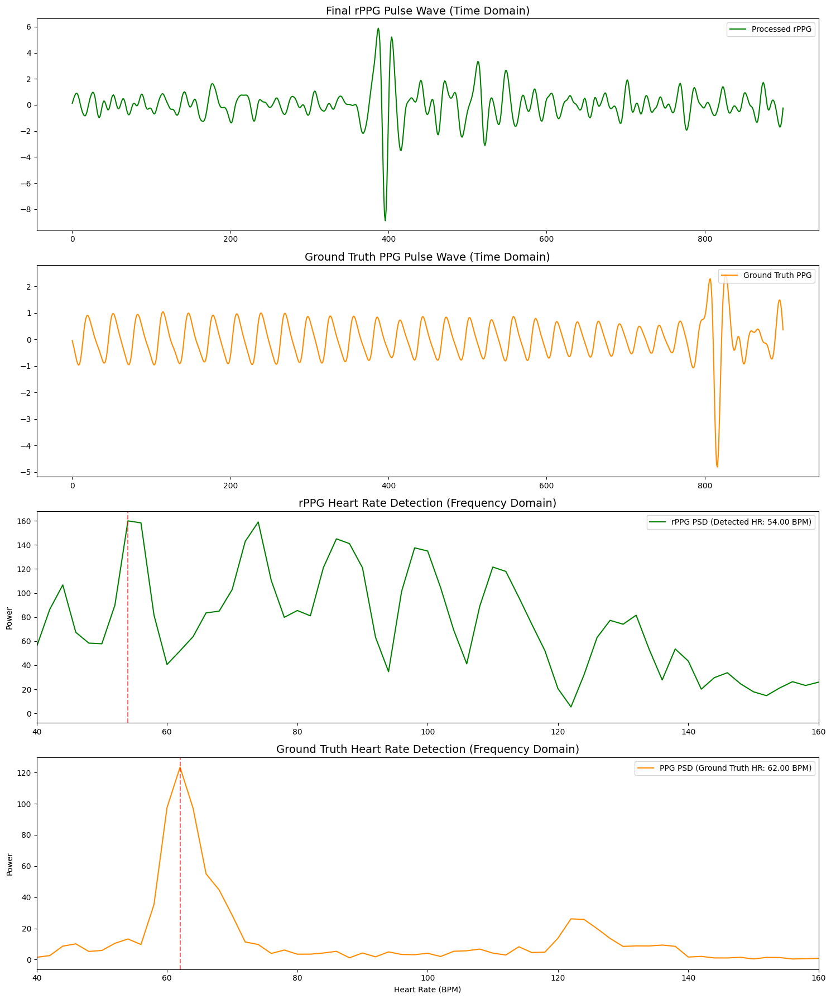

총 116개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 80개, 폐기 윈도우 36개
B008_20250627 : 성공 , hr : 10.099999999999998


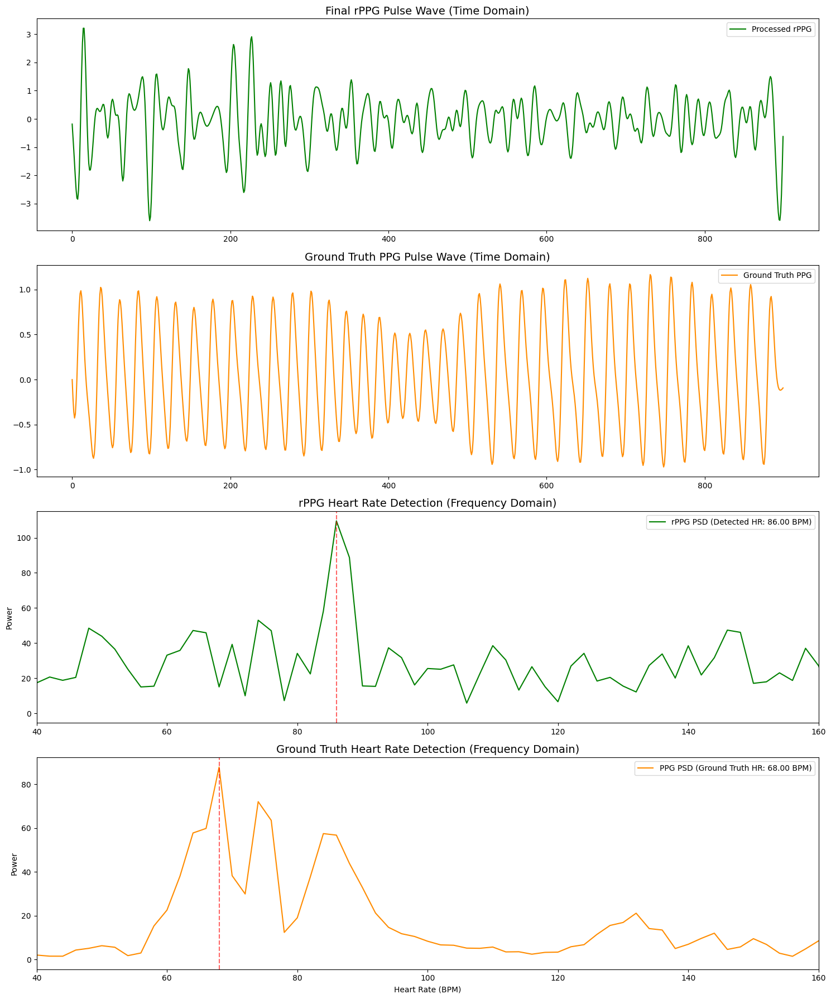

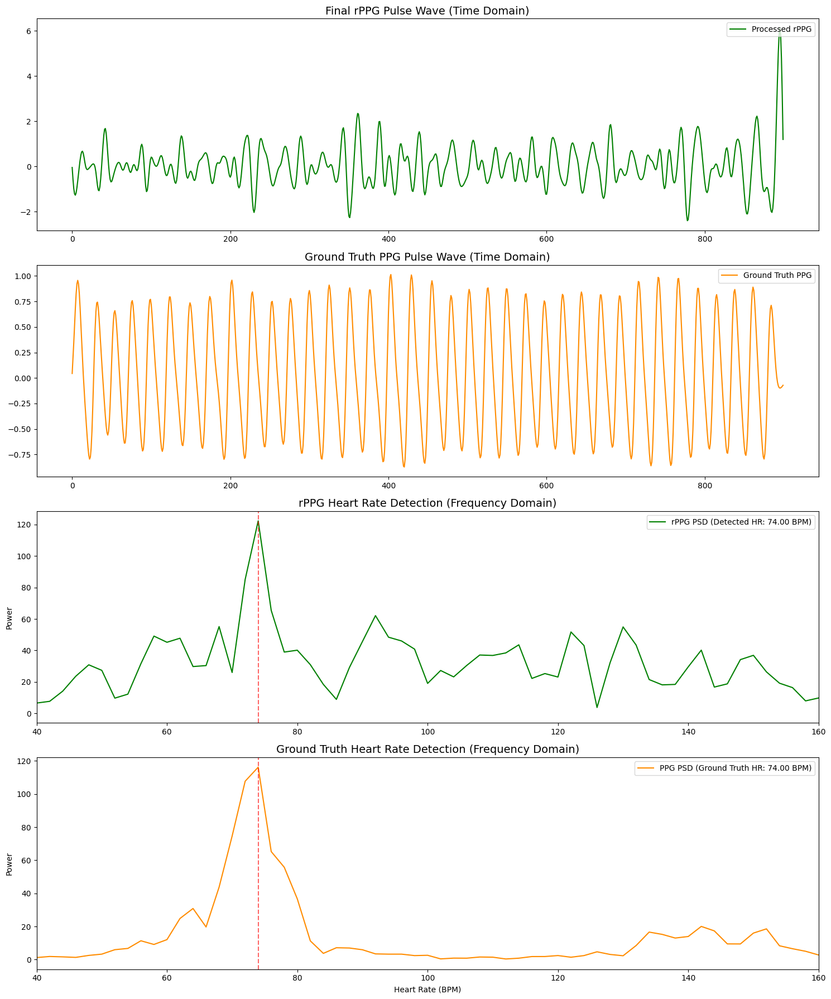

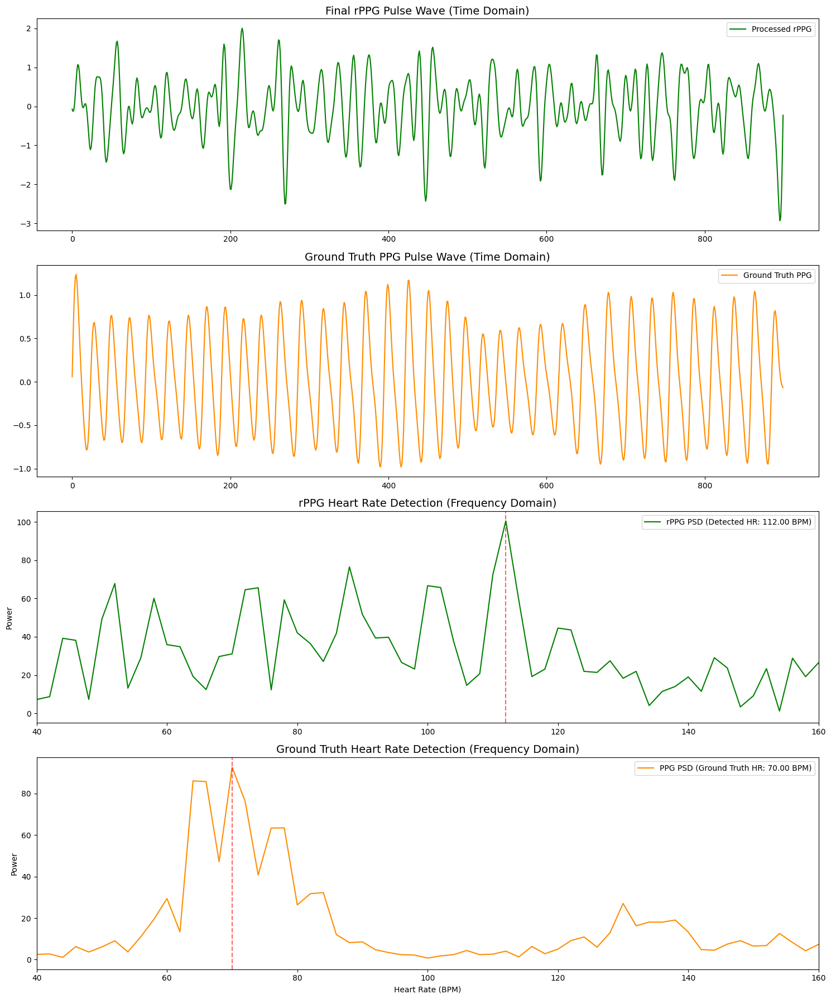

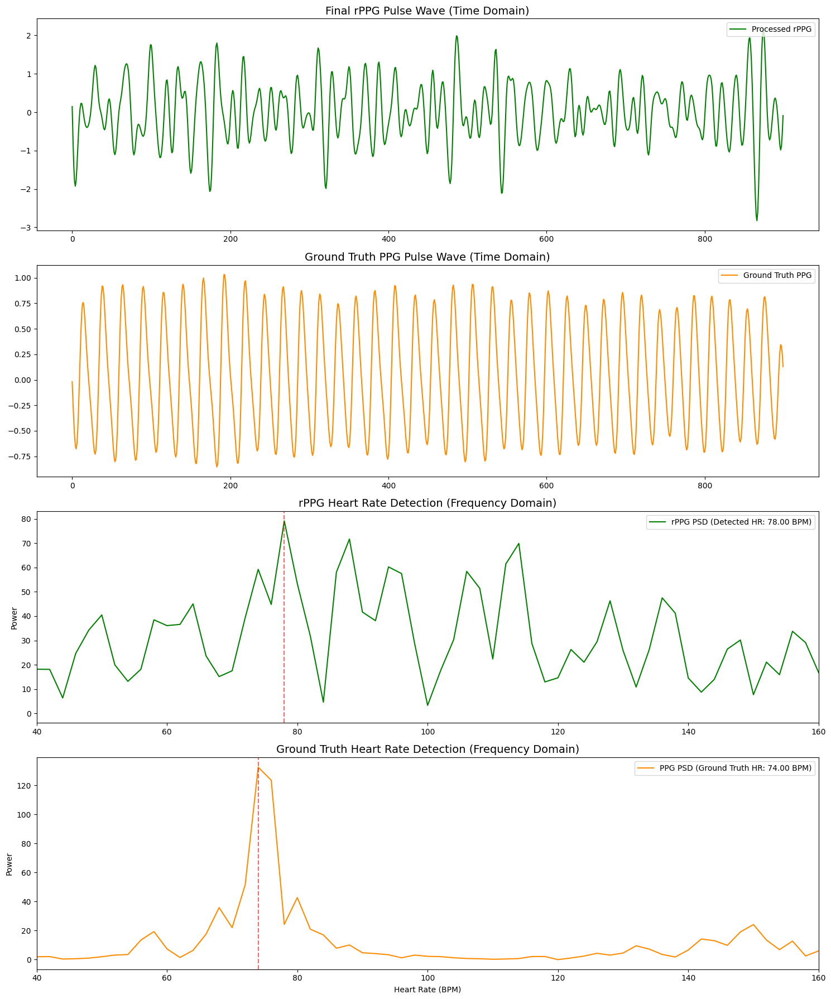

총 120개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 113개, 폐기 윈도우 7개
C001_20250701 : 성공 , hr : 29.02654867256637


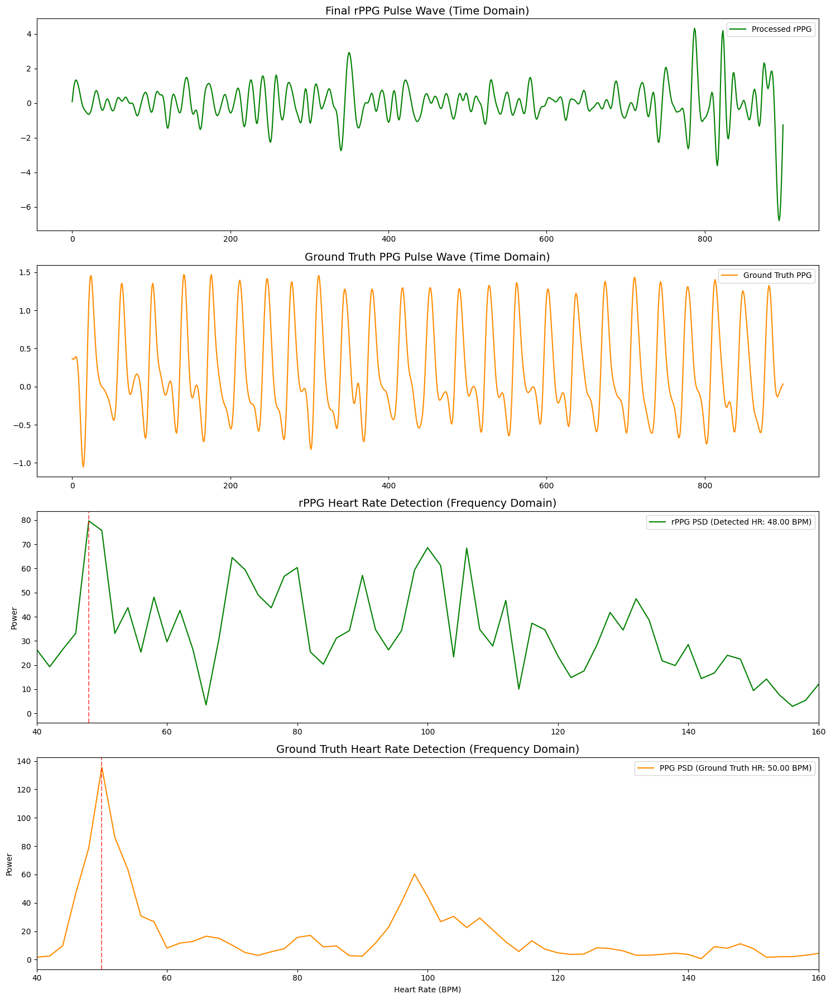

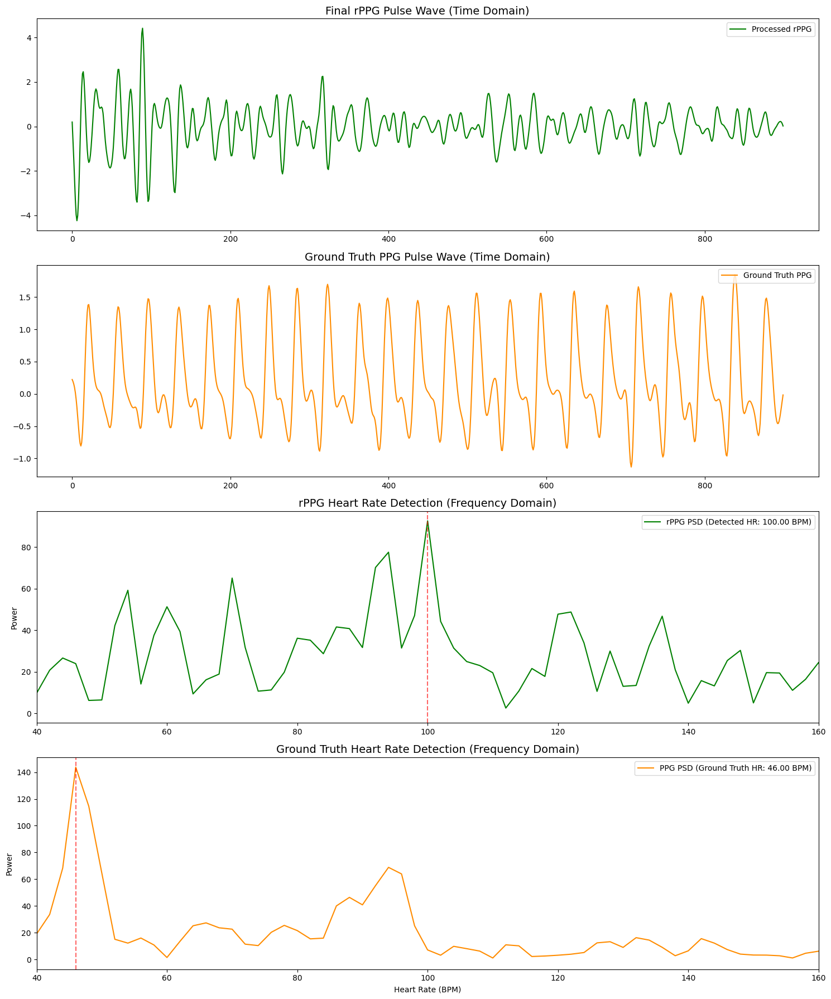

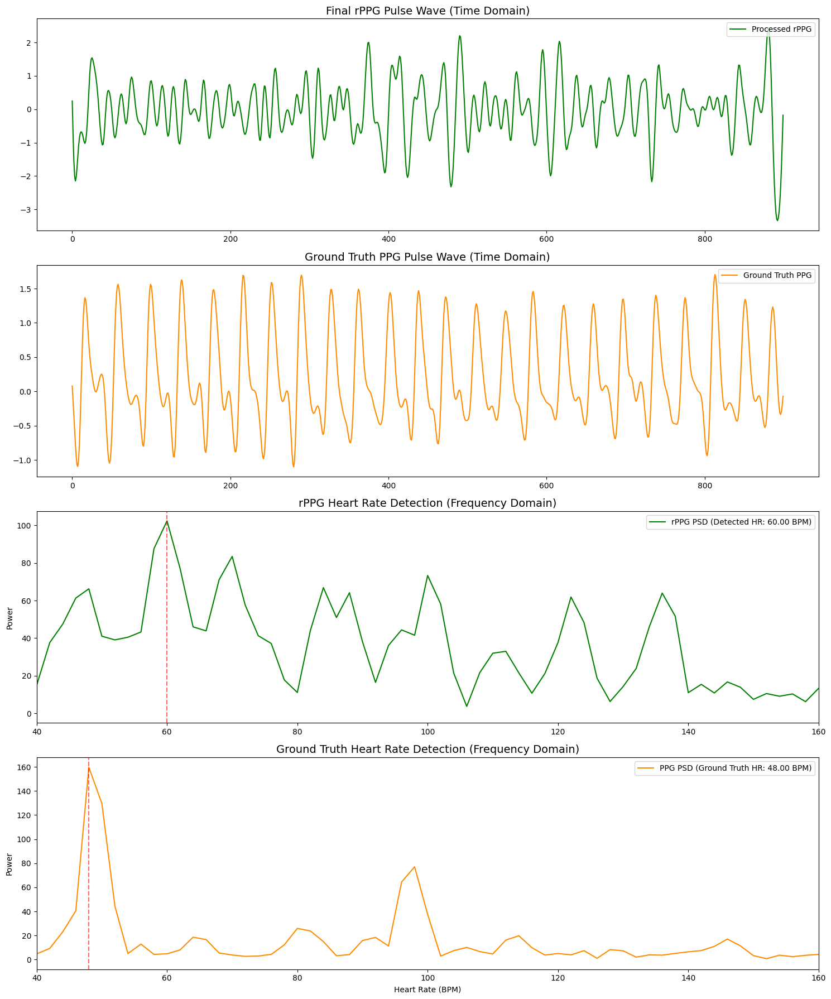

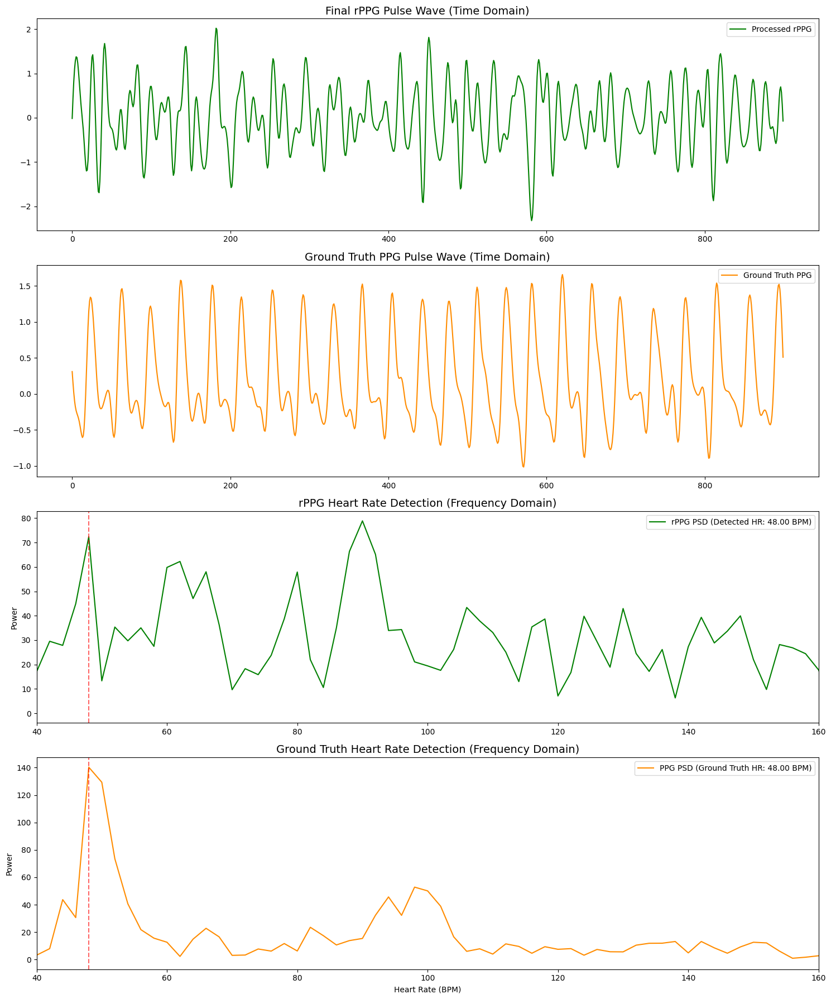

총 130개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 30개, 폐기 윈도우 100개
C002_20250703 : 성공 , hr : 19.2


❌ [치명적 오류 발생] 프로그램이 중단되었습니다.
에러 메시지: array must not contain infs or NaNs
------------------------------
상세 에러 위치 (Traceback):


Traceback (most recent call last):
  File "/tmp/ipykernel_276547/2728356016.py", line 122, in <module>
    visualize_interpolation_and_fft(sig_rl, ppg_downsampled ,sub_valid, window_idx = j)
  File "/tmp/ipykernel_276547/3516439891.py", line 22, in visualize_interpolation_and_fft
    norm_rppg = z_norm(signal.filtfilt(b, a, signal.detrend(interpolated_window)))
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/scipy/signal/_signaltools.py", line 3958, in detrend
    coef, resids, rank, s = linalg.lstsq(A, newdata[sl])
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/scipy/linalg/_basic.py", line 1413, in lstsq
    b1 = _asarray_validated(b, check_finite=check_finite)
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/scipy/_lib/_util.py", line 537, in _asarray_validated
    a = toarray(a)
  File "/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/numpy/lib/function_base.py", line 630, in asarray_chkfinite
  

총 119개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 117개, 폐기 윈도우 2개
C003_20250702 : 성공 , hr : 15.931623931623932


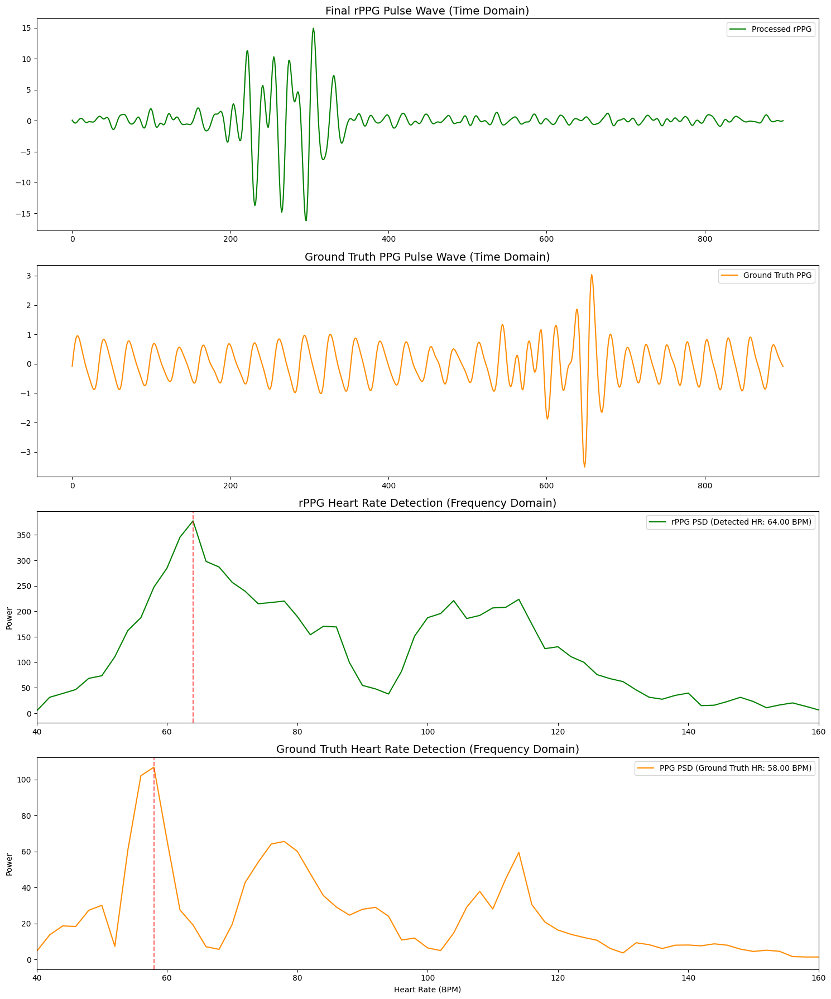

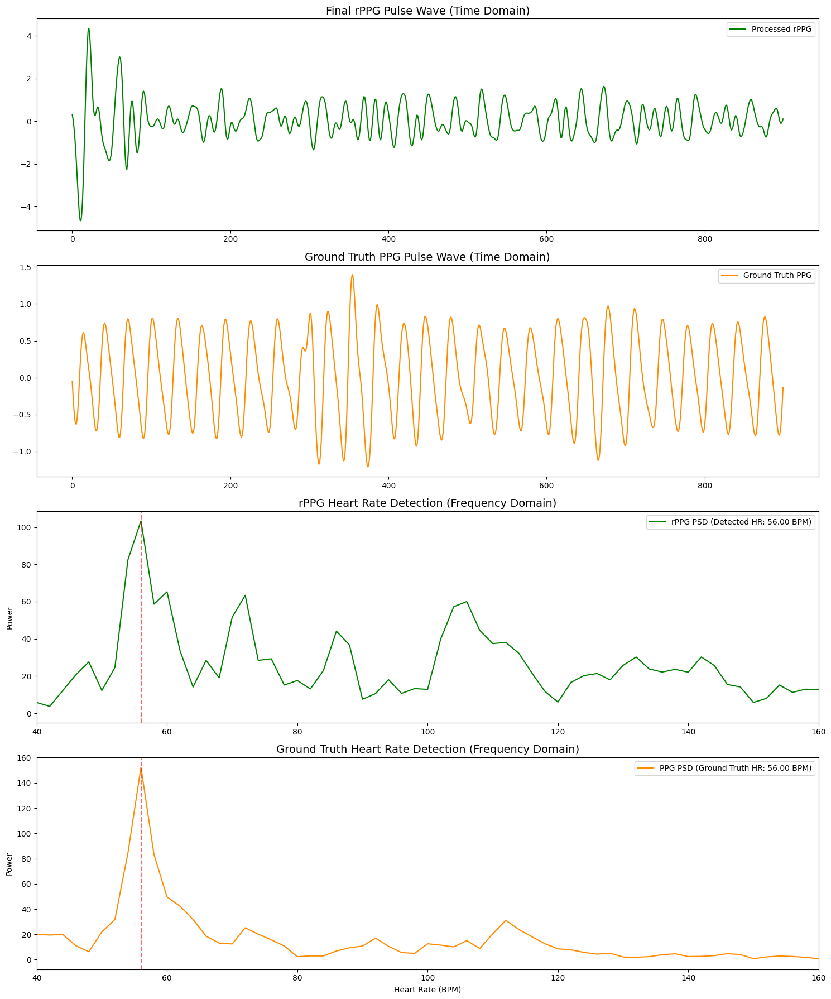

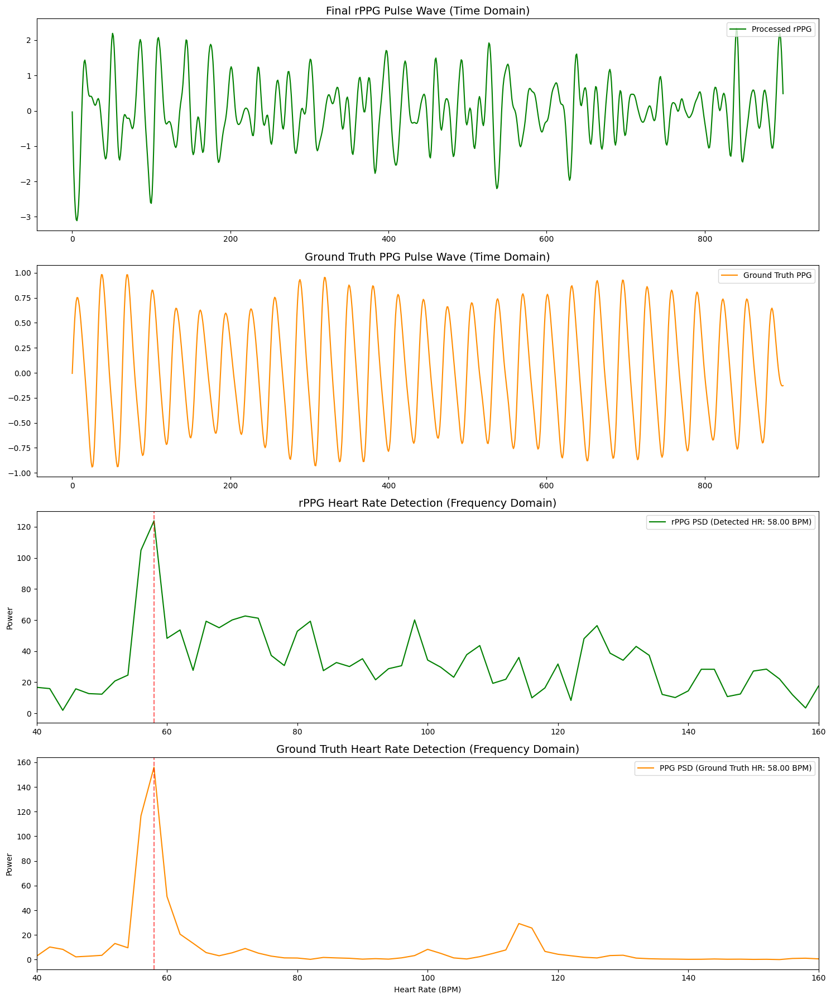

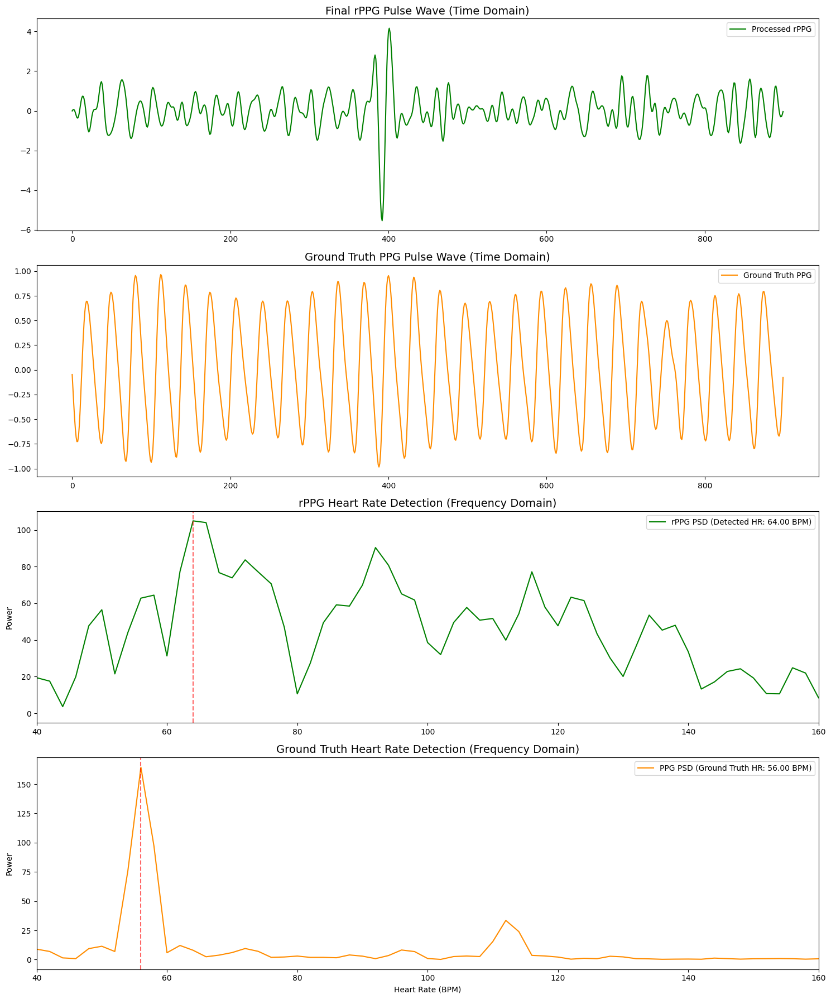

In [42]:
hr_dict = {}
hrv_dict = {}
sub_dict ={}
sub_dict_2 = {}
nan_dict = {}
f_lc, f_hc = 0.75 , 2.5 ## 밴드패스 주파수 설정

for s_n in range(len(subject_lists)) : 
    #print("\n\n" + "="*50)
    #print("strat the process....")
    try :
        

        # ====================================================
        # 1. 데이터 로드
        # ====================================================
        subject_num = s_n ######################################################### subject 설정 #########################################################
        subject_id = subject_lists[subject_num].split('[')[1].split(']')[0]
        #print(f"subject id : {subject_id}")

        # ====================================================
        # 2. rppg 로드
        # ====================================================
        h_dir = os.path.join(h5_preprocess_dir,subject_lists[subject_num]) # rppg 루트
        with h5py.File(h_dir, 'r') as f_r:
            # 데이터셋 키(key) 확인 (파일 안에 어떤 데이터셋이 있는지 모를 때)
            #print("Keys in H5 file:", list(f_r.keys()))
            
            subject_dict = {
                'data' : f_r['nir_uv_data'][()],
                'valid_mask' : f_r['valid_mask'][()],
                'fail_rate' : f_r['valid_mask'].attrs['fail_rate']
                }

        # rppg 추출
        sub_data = subject_dict['data'] #(T, 64, 64)
        sub_valid = subject_dict['valid_mask']
        sub_fr = subject_dict['fail_rate']

        failed_indices = np.where(sub_valid == False)[0]

        data = sub_data 
        T,H,W = data.shape
        
        get_s = get_sig(data)

        ## 양볼 16좌표들
        # roi_samples = data[:,roi_rows, roi_cols]
        # nonzero_counts = ( roi_samples > 0 ).sum(axis = 1)
        # sig_rl = roi_samples.sum(axis =1) / (nonzero_counts +1e-8 )

        #양볼 16좌표들 3x3 평균
        sig_rl = get_s.get_rl_rois( roi_rows, roi_cols )
        
        ## 양볼1좌표
        #sig_rl =get_s.get_rl_roi_one(roi_l_r, roi_l_c, roi_r_r, roi_r_c )
        
        # 왼볼1좌표
        #sig_rl = get_s.get_rl_roi_left(roi_l_r, roi_l_c, roi_r_r, roi_r_c )

    


        # ====================================================
        # 3. ppg 로드 (순서를 위로 끌어올림!)
        # ====================================================
        
        cut_ppg_root = os.path.join(ppg_cut_dir, ppg_list[subject_num]) 
        ppg_cut = pd.read_csv(cut_ppg_root)        
        # rPPG의 프레임 길이에 맞춰 정답 PPG도 다운샘플링 (전체 길이 확보)
        ppg_downsampled = signal.resample(ppg_cut, data.shape[0])

        # ====================================================
        # 4. rPPG 전처리 및 VMD 수행 (정답 PPG를 같이 넘겨줌)
        # ====================================================

        rppg_windows, discarded_indices = process_rppg_windows(
            sig_rl, 
            sub_valid, 
            window_size=900, # window 길이 : 30초
            max_gap_threshold=30, # 보간기준 1초이상 nan시 폐기
            mode='normal', 
            alp=800, 
            k=3, 
            lowcut=f_lc, 
            highcut=f_hc, 
            plot_g= False,
            plot_d = False,                    
            ref_ppg_sig= None     
        )

        # ====================================================
        # 5. PPG 윈도우 생성 (rPPG에서 에러난 구간 제외)
        # ====================================================

        ppg_windows = ppg_to_window(
            ppg_downsampled, 
            discarded_indices, 
            window_size = 900, 
            lowcut = f_lc, 
            highcut = f_hc
        )

        # ====================================================
        # 6. HR 검출 및 비교
        # ====================================================
        mae, nan_list, rmse, r_hr = get_hr(ppg_windows, rppg_windows, window_size=900, lowcut=f_lc, highcut=f_hc)
        
        sub_dict['hr_mae'] = mae
        sub_dict['hr_rmse'] = rmse
        sub_dict['hr_r'] = r_hr

        hr_dict[subject_id] = sub_dict
        nan_dict[subject_id] = nan_list

        sub_dict = {}
        
        print(f"{subject_id} : 성공 , hr : {mae}" )

        # time, frequency domain에서 시각화
        for j in [110,111,112,113] :
            visualize_interpolation_and_fft(sig_rl, ppg_downsampled ,sub_valid, window_idx = j)

        # ====================================================
        # 7. hrv 검출
        # ====================================================
        
        # hrv_anal = get_hrv()
        # hrv_anal.process_dataset(ppg_dict = ppg_windows, rppg_dict = rppg_windows)
        # if subject_id not in hrv_dict:
        #     hrv_dict[subject_id] = []
        # hrv_dict[subject_id].append(hrv_anal.print_table_metrics()) 
        # print(f'subject : {subject_id} , 전체 윈도우 : {len(rppg_windows) + len(discarded_indices)} , 폐기 윈도우 : {len(discarded_indices) + len(hrv_anal.failed_windows) } , 비율 : { (len(rppg_windows) -  len(hrv_anal.failed_windows)) / (len(rppg_windows) + len(discarded_indices)) *100 }%')
        # #print("\n\n" + "="*50)


    except Exception as e :

        print("\n\n" + "="*50)
        print("❌ [치명적 오류 발생] 프로그램이 중단되었습니다.")
        print("="*50)
        print(f"에러 메시지: {e}")
        print("-" * 30)
        print("상세 에러 위치 (Traceback):")
        traceback.print_exc() # 어디서 에러가 났는지 상세하게 줄 번호까지 출력해줍니다.
        print("="*50)

In [ ]:
##이전꺼실험
hr_dict = {}
hrv_dict = {}
sub_dict ={}
sub_dict_2 = {}
nan_dict = {}

roi_point = (uv_numpy[425] * 64).astype(int)

left_chick_r = roi_point[1]
left_chick_c = roi_point[0]

right_chick_r = roi_point[1]
right_chick_c = ((64 - roi_point[0])).astype(int)
pp = ['A001_250609.csv', 'A002_250609.csv', 'A004_250610.csv', 'A005_250611.csv', 'A006_250611.csv', 'A007_250612.csv', 'A008_250612.csv', 'B001_250623.csv',
 'B002_250623.csv', 'B003_250624.csv', 'B004_250624.csv', 'B005_250625.csv', 'B008_250627.csv', 'C001_250701.csv', 'C002_250703.csv', 'C003_250702.csv']

for s_n in range(len(people_list_2)) : 
    print("strat the process....")
    try :
        

        # ====================================================
        # 1. 데이터 로드
        # ====================================================
        subject_num = s_n ######################################################### subject 설정 #########################################################
        subject_id = subject_lists[subject_num].split('[')[1].split(']')[0]
        print(f"subject id : {subject_id}")

        # ====================================================
        # 2. rppg 로드
        # ====================================================
        h_dir = os.path.join(h5_preprocess_dir,subject_lists[subject_num]) # rppg 루트
        with h5py.File(h_dir, 'r') as f_r:
            # 데이터셋 키(key) 확인 (파일 안에 어떤 데이터셋이 있는지 모를 때)
            #print("Keys in H5 file:", list(f_r.keys()))
            
            subject_dict = {
                'data' : f_r['nir_uv_data'][()],
                'valid_mask' : f_r['valid_mask'][()],
                'fail_rate' : f_r['valid_mask'].attrs['fail_rate']
                }


        sub_data = subject_dict['data'] #(T, 64, 64)
        sub_valid = subject_dict['valid_mask']
        sub_fr = subject_dict['fail_rate']

        failed_indices = np.where(sub_valid == False)[0]

        data = sub_data
        T, H, W = data.shape
        lr,lc = left_chick_r , left_chick_c
        rr, rc = right_chick_r, right_chick_c

        roi_pixels_l = data[: , lr-1 : lr + 2, lc-1 : lc + 2]
        nonzero_count_l = (roi_pixels_l > 0).sum(axis=(1, 2))
        #avg_sig_sl_l = roi_pixels_l.sum(axis=(1,2)) / (nonzero_count_l + 1e-8) # 0으로 나누기 방지

        roi_pixels_r = data[: , rr-1 : rr + 2, rc-1 : rc + 2]
        nonzero_count_r = (roi_pixels_r > 0).sum(axis=(1, 2))
        #avg_sig_sl_r = roi_pixels_r.sum(axis=(1,2)) / (nonzero_count_r + 1e-8) # 0으로 나누기 방지

        roi_pixels = (roi_pixels_l + roi_pixels_r).sum(axis = (1,2))

        sig_rl = roi_pixels / (nonzero_count_r + nonzero_count_l + 1e-8)

        rppg_windows, discarded_indices = process_rppg_windows(sig_rl, sub_valid, window_size=900, max_gap_threshold= 30)


        # ====================================================
        # 3. ppg 로드
        # ====================================================
        ppg_cut_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/ppg_last_5mtruncated' #ppg cut
        cut_ppg_root = os.path.join(ppg_cut_dir, pp[subject_num]) # cut ppg 루트   
        ppg_cut = pd.read_csv(cut_ppg_root)
        ppg_downsampled = signal.resample(ppg_cut, data.shape[0])

        ppg_windows = ppg_to_window(ppg_downsampled, discarded_indices, window_size=900 )

        # ====================================================
        # 4. hr 검출
        # ====================================================
        mae, nan_list, rmse, r_hr = get_hr(ppg_windows, rppg_windows)
        
        sub_dict['hr_mae'] = mae
        sub_dict['hr_rmse'] = rmse
        sub_dict['hr_r'] = r_hr

        hr_dict[subject_id] = sub_dict
        nan_dict[subject_id] = nan_list

        sub_dict = {}
        
        print(f"{subject_id} : 성공 , hr : {mae}" )

        # ====================================================
        # 5. hrv 검출
        # ====================================================
        
        # hrv_anal = get_hrv()
        # hrv_anal.process_dataset(ppg_dict = ppg_windows, rppg_dict = rppg_windows)
        # if subject_id not in hrv_dict:
        #     hrv_dict[subject_id] = []
        # hrv_dict[subject_id].append(hrv_anal.print_table_metrics()) 




    except Exception as e :

        print("\n\n" + "="*50)
        print("❌ [치명적 오류 발생] 프로그램이 중단되었습니다.")
        print("="*50)
        print(f"에러 메시지: {e}")
        print("-" * 30)
        print("상세 에러 위치 (Traceback):")
        traceback.print_exc() # 어디서 에러가 났는지 상세하게 줄 번호까지 출력해줍니다.
        print("="*50)

In [43]:
hr_df = pd.DataFrame(hr_dict)
display(hr_df)
hr_df.mean(axis =1)

,A001_20250609,A002_20250609,A004_20250610,A005_20250611,A006_20250611,A007_20250612,A008_20250612,B001_20250623,B002_20250623,B003_20250624,B004_20250624,B005_20250625,B008_20250627,C001_20250701,C002_20250703,C003_20250702
hr_mae,14.554622,16.533333,27.086614,10.752941,11.826087,26.126582,21.452055,13.763780,13.646154,13.829060,26.324786,18.542857,10.100000,29.026549,19.200000,15.931624
hr_rmse,19.686620,22.756684,34.130827,16.927527,19.517662,33.244777,28.345230,20.102102,18.489914,19.923786,33.866505,24.999429,14.959947,35.203580,26.122787,25.341429
hr_r,-0.073263,0.136092,-0.089421,0.230664,0.184827,-0.150145,-0.092896,0.035367,-0.009148,-0.032127,-0.041668,-0.067261,0.061539,-0.146379,-0.228266,-0.122097


hr_mae     18.043565
hr_rmse    24.601175
hr_r       -0.025261
dtype: float64

In [12]:
all_dfs = []

# 딕셔너리에서 DataFrame 꺼내기
for subject_id, df_list in hrv_dict.items():
    if df_list:
        # 리스트 안에 있는 DataFrame 추출
        df = df_list[0]
        all_dfs.append(df)

if all_dfs:
    # 1. 모든 피험자의 결과를 하나의 긴 DataFrame으로 합치기
    combined_df = pd.concat(all_dfs, ignore_index=True)
    
    # 2. 'Metric'을 기준으로 그룹화하여 평균 계산
    # (LF끼리, HF끼리 묶어서 STD, RMSE, R의 평균을 냄)
    final_avg_df = combined_df.groupby('Metric')[['STD', 'RMSE', 'R']].mean().reset_index()

    # 3. 보기 좋게 정렬 (옵션)
    # 원하는 순서 지정
    desired_order = ['LF(n.u.)', 'HF(n.u.)', 'LF/HF', 'RF(Hz)']
    final_avg_df['Metric'] = pd.Categorical(final_avg_df['Metric'], categories=desired_order, ordered=True)
    final_avg_df = final_avg_df.sort_values('Metric').reset_index(drop=True)


    # 소수점 포맷팅해서 보기 (선택사항)
    print("\n[Formatted View]")
    print(final_avg_df.round(4))

else:
    print("분석할 데이터가 없습니다.")


[Formatted View]
     Metric     STD    RMSE       R
0  LF(n.u.)  0.2113  0.2819  0.0436
1  HF(n.u.)  0.2145  0.2759  0.0279
2     LF/HF  1.6101  1.9083  0.0316
3    RF(Hz)  0.0444  0.0458  0.0147


# 분포관찰

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

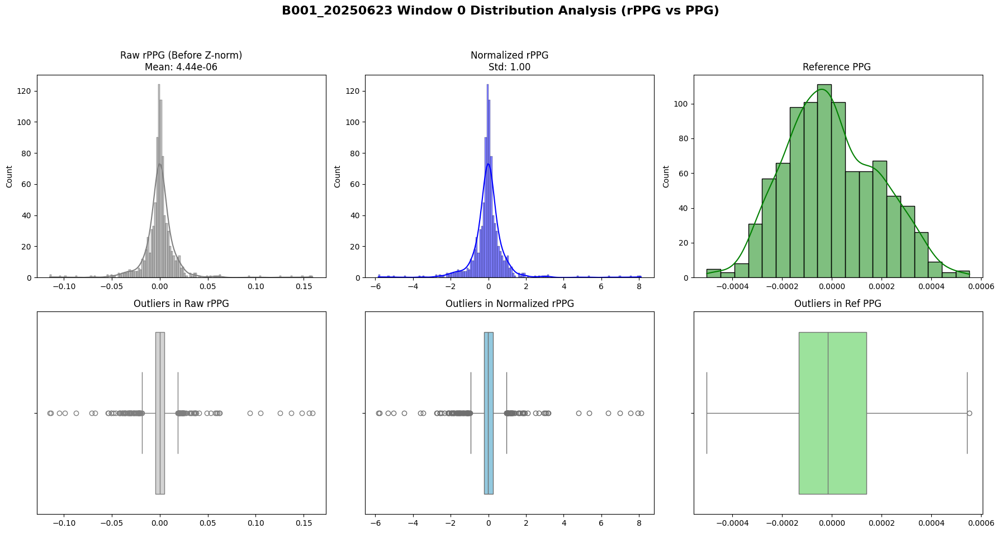

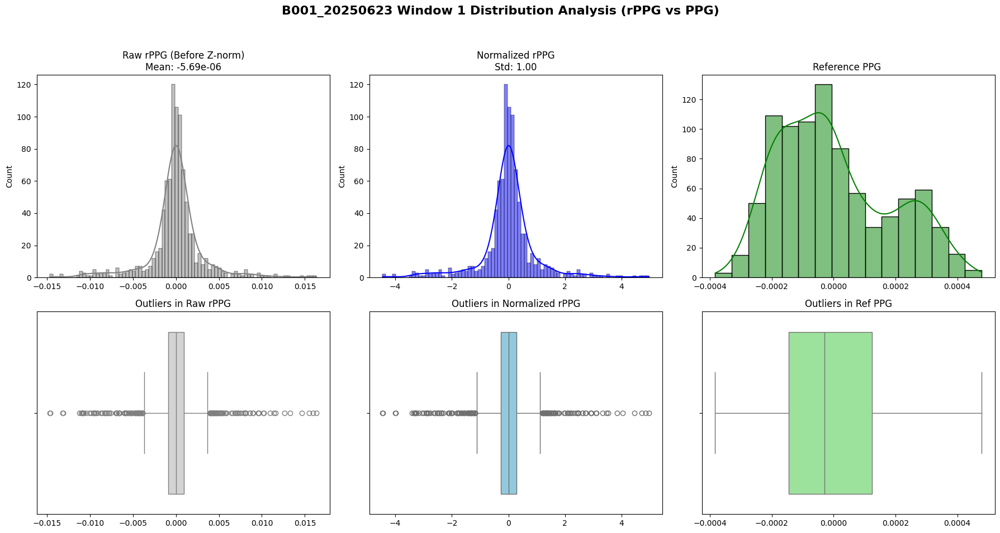

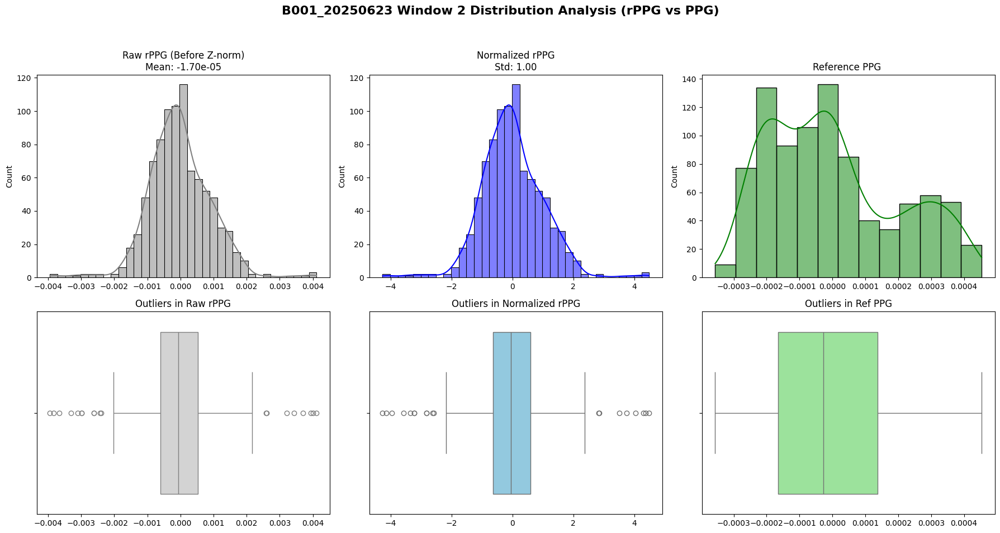

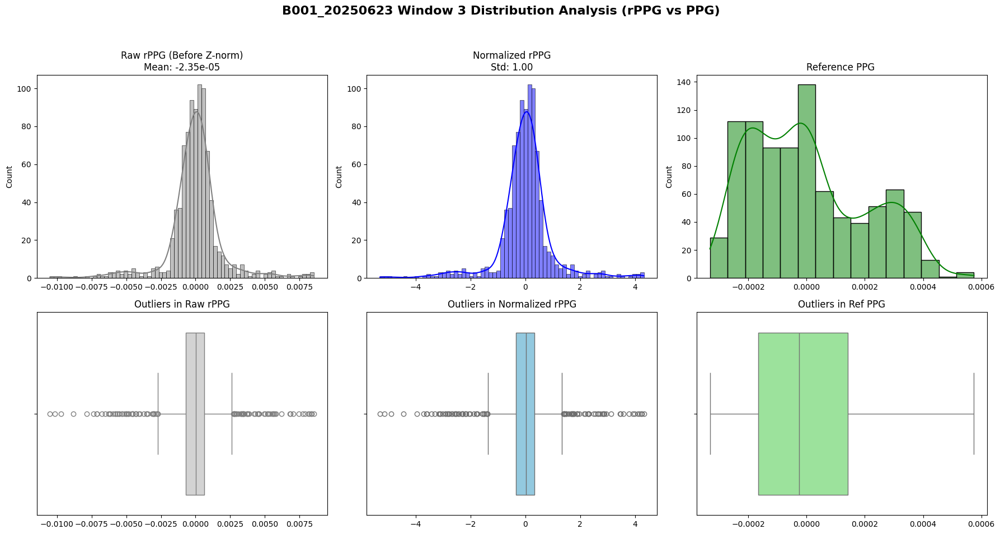

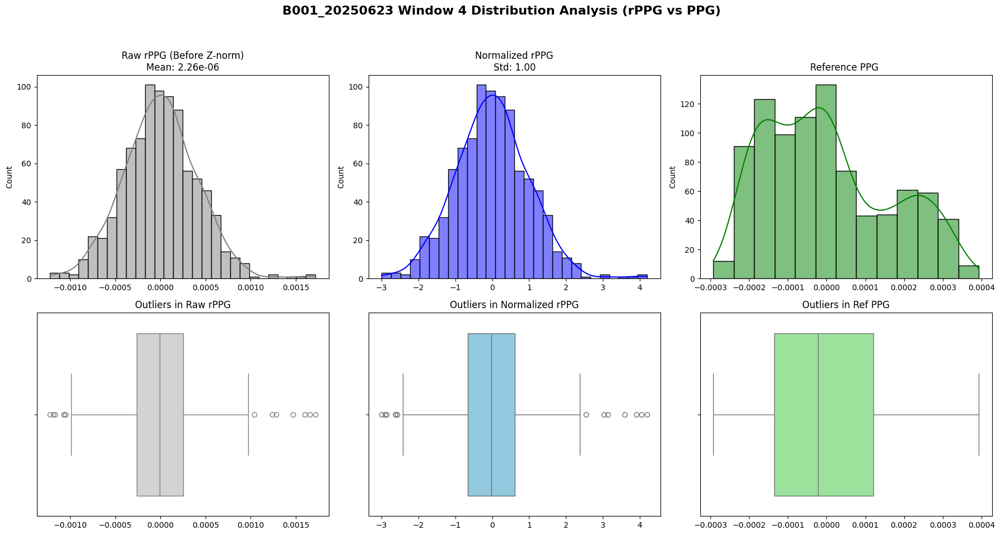

...

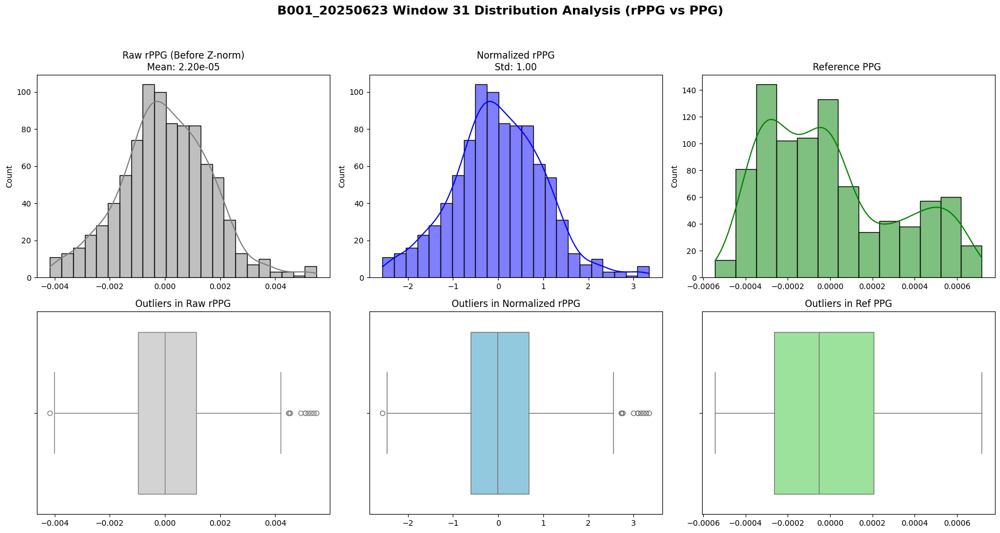

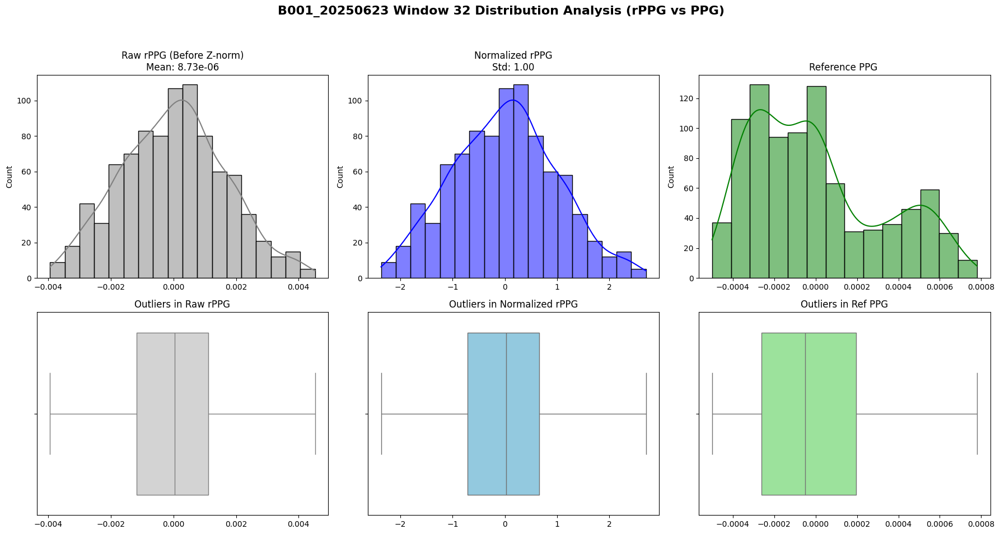

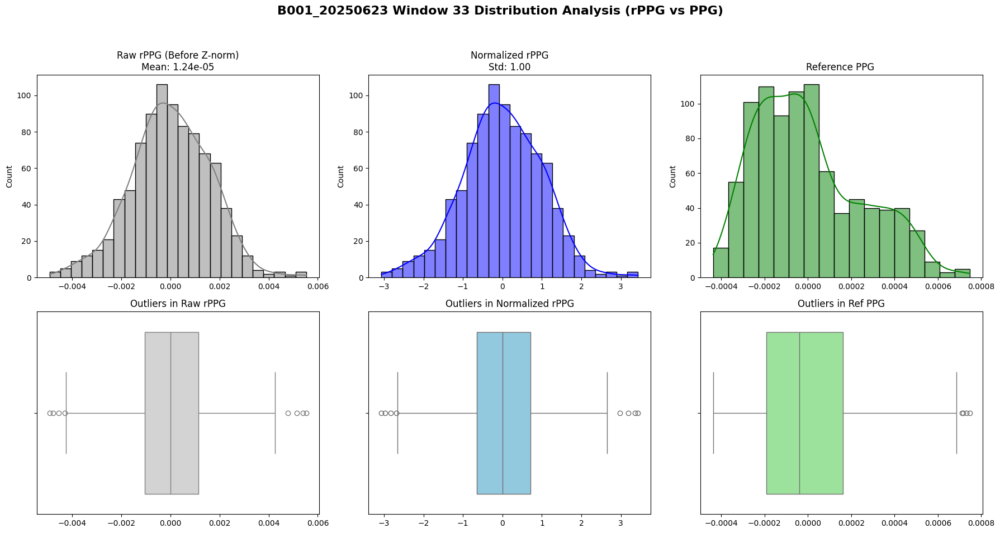

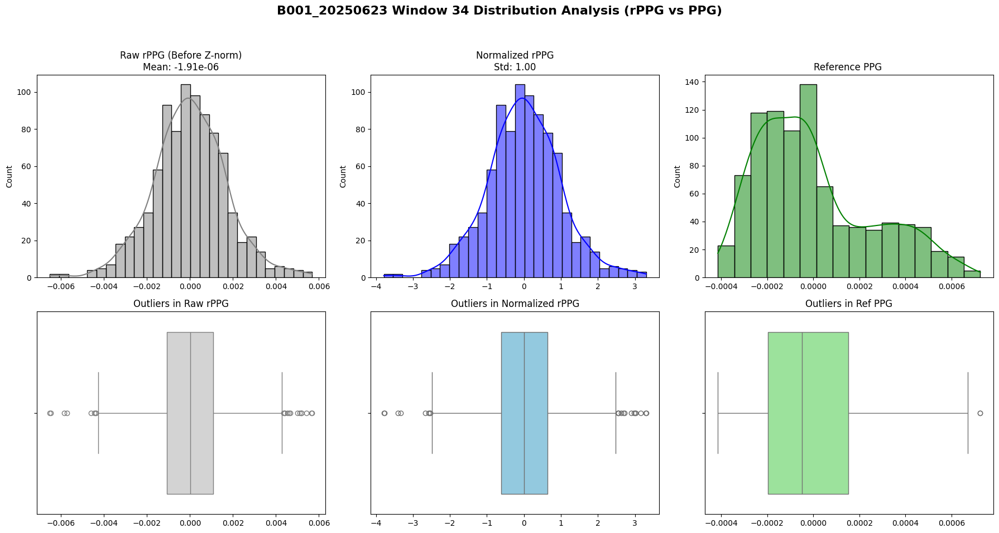

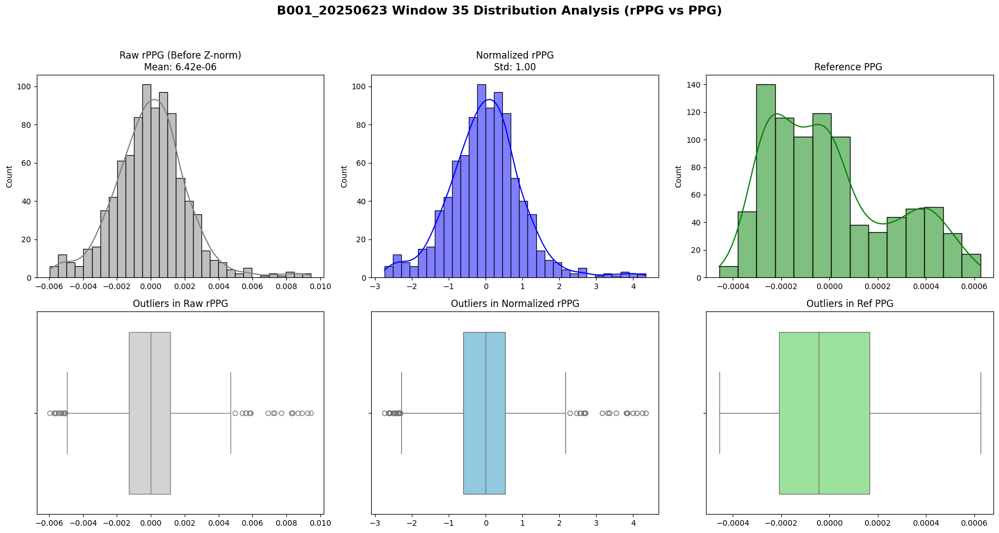

KeyboardInterrupt: 

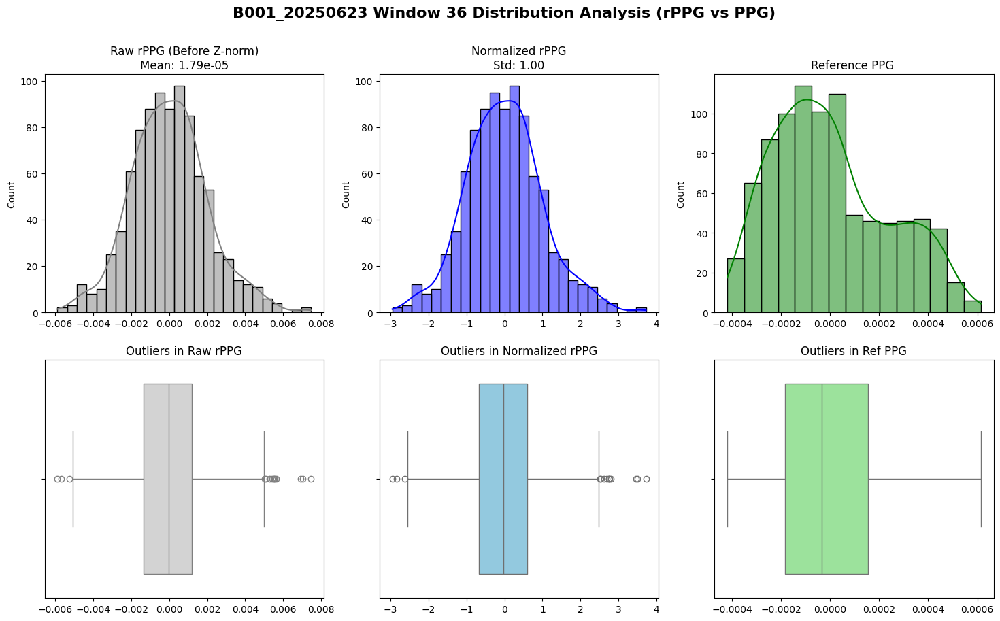

In [38]:
hr_dict = {}
hrv_dict = {}
sub_dict ={}
sub_dict_2 = {}
nan_dict = {}
f_lc, f_hc = 0.75 , 2.5 ## 밴드패스 주파수 설정

# ====================================================
# 1. 데이터 로드
# ====================================================
subject_num = 7 ######################################################### subject 설정 #########################################################
subject_id = subject_lists[subject_num].split('[')[1].split(']')[0]
#print(f"subject id : {subject_id}")

# ====================================================
# 2. rppg 로드
# ====================================================
h_dir = os.path.join(h5_preprocess_dir,subject_lists[subject_num]) # rppg 루트
with h5py.File(h_dir, 'r') as f_r:
    # 데이터셋 키(key) 확인 (파일 안에 어떤 데이터셋이 있는지 모를 때)
    #print("Keys in H5 file:", list(f_r.keys()))
    
    subject_dict = {
        'data' : f_r['nir_uv_data'][()],
        'valid_mask' : f_r['valid_mask'][()],
        'fail_rate' : f_r['valid_mask'].attrs['fail_rate']
        }

# rppg 추출
sub_data = subject_dict['data'] #(T, 64, 64)
sub_valid = subject_dict['valid_mask']
sub_fr = subject_dict['fail_rate']

failed_indices = np.where(sub_valid == False)[0]

data = sub_data 
T,H,W = data.shape

get_s = get_sig(data)

## 양볼 16좌표들
# roi_samples = data[:,roi_rows, roi_cols]
# nonzero_counts = ( roi_samples > 0 ).sum(axis = 1)
# sig_rl = roi_samples.sum(axis =1) / (nonzero_counts +1e-8 )

#양볼 16좌표들 3x3 평균
sig_rl = get_s.get_rl_rois( roi_rows, roi_cols )

## 양볼1좌표
#sig_rl =get_s.get_rl_roi_one(roi_l_r, roi_l_c, roi_r_r, roi_r_c )

# 왼볼1좌표
#sig_rl = get_s.get_rl_roi_left(roi_l_r, roi_l_c, roi_r_r, roi_r_c )


# ====================================================
# 3. ppg 로드 (순서를 위로 끌어올림!)
# ====================================================
cut_ppg_root = os.path.join(ppg_cut_dir, ppg_list[subject_num]) 
ppg_cut = pd.read_csv(cut_ppg_root)

# rPPG의 프레임 길이에 맞춰 정답 PPG도 다운샘플링 (전체 길이 확보)
ppg_downsampled = signal.resample(ppg_cut, data.shape[0])

# ====================================================
# 4. rPPG 전처리 및 VMD 수행 (정답 PPG를 같이 넘겨줌)
# ====================================================
rppg_windows, discarded_indices = process_rppg_windows(
    sig_rl, 
    sub_valid, 
    window_size=900, # window 길이 : 30초
    max_gap_threshold=30, # 보간기준 1초이상 nan시 폐기
    mode='normal', 
    alp=800, 
    k=3, 
    lowcut=f_lc, 
    highcut=f_hc, 
    plot_g= False,
    plot_d = True,                      # 👈 시각화 켬!
    ref_ppg_sig= ppg_downsampled     # 👈 정답지 넘겨줌!
)